# Food Safety and Restaurant Inspection Analytics: Integrated Data Warehouse, OLAP and Data Mining Project
**Rushikesh Maddewad** | PRN 202502040037 | Roll No 353 | Data: City of Chicago Food Inspections (official Data Portal), 2022-2025

**This is the single-file version of the whole project.** Every source file of the project (Python, SQL, shell) is written out by a `%%writefile` cell and then run, so the notebook alone reproduces the work. The same code is also available as a normal repository (`EDA/Project`).

**How to run (Google Colab):** *Runtime > Run all*. It takes about 10 minutes. It installs PostgreSQL inside Colab, downloads the official data, and builds everything.

| Section | What it does |
|---|---|
| 0 | Set-up: libraries, PostgreSQL |
| A | Download, profiling, curation, EDA |
| B, C | Dimensional models and the PostgreSQL batch warehouse (ETL, validation, incremental load, indexing, timing) |
| F | OLAP queries and the HTML dashboard |
| G, H, I | Regression, association-rule mining (Apriori, FP-Growth), decision tree, all on the analytical mart |
| D, E | Distributed warehouse (Citus) and real-time warehouse (Kafka, Spark, ClickHouse): code is saved here, **but not run in Colab** (they need several servers); my recorded measurements are shown |
| J | Architecture comparison and recommendation |

**Honest notes:** the real-time part is a replay of historical data; Citus ran on one machine and was not faster than one node; there is no Power BI `.pbix` (Power BI Desktop is Windows-only), the HTML dashboard replaces it.

## 0. Set-up
Folder layout, libraries and a local PostgreSQL server (in Colab it is installed with apt; elsewhere an existing server on port 5432 is used).

In [1]:
import os, sys, pathlib
IN_COLAB = "google.colab" in sys.modules
WORK = pathlib.Path("/content") if IN_COLAB else pathlib.Path.cwd()
os.chdir(WORK)
for d in ["etl", "sql", "scripts", "streaming", "notebooks", "data/raw", "data/curated", "results/analytical_query_results", "docs", "dashboard"]:
    os.makedirs(f"Project/{d}", exist_ok=True)
print("working folder:", WORK, "| Colab:", IN_COLAB)

working folder: /tmp/claude-0/-home-user-academics-6th/da020520-4181-591c-b5b1-bc79cf26c93a/scratchpad/colabtest | Colab: False


In [2]:
%pip install -q psycopg2-binary mlxtend statsmodels plotly

Note: you may need to restart the kernel to use updated packages.


In [3]:
%%bash
# PostgreSQL: installed only if no server answers on localhost:5432
if ! pg_isready -q -h localhost -p 5432; then
  apt-get -qq update && apt-get -qq install -y postgresql > /dev/null
  service postgresql start; sleep 4
fi
su postgres -c "psql -tc \"SELECT 1 FROM pg_roles WHERE rolname='foodsafety'\"" | grep -q 1 || su postgres -c "psql -c \"CREATE ROLE foodsafety LOGIN PASSWORD 'foodsafety' SUPERUSER;\""
su postgres -c "psql -tc \"SELECT 1 FROM pg_database WHERE datname='foodsafety'\"" | grep -q 1 || su postgres -c "psql -c \"CREATE DATABASE foodsafety OWNER foodsafety;\""
PGPASSWORD=foodsafety psql -h localhost -U foodsafety -d foodsafety -tc "select version()"

 PostgreSQL 16.15 (Ubuntu 16.15-1.pgdg24.04+2) on x86_64-pc-linux-gnu, compiled by gcc (Ubuntu 13.3.

0-6ubuntu2~24.04.1) 13.3.0, 64-bit



# Part A. Dataset, profiling, curation and EDA

**`scripts/fetch_data.py`**: downloads the official records for 1 Jan 2022 - 31 Dec 2025 from the City of Chicago Data Portal (Socrata API).

In [4]:
%%writefile Project/scripts/fetch_data.py
"""Downloads the official Chicago Food Inspections records for 1 Jan 2022 - 31 Dec 2025 from the City of Chicago Data Portal (Socrata API)."""
import hashlib, urllib.parse, urllib.request
from pathlib import Path

root = Path(__file__).resolve().parents[1] / "data" / "raw"; root.mkdir(parents=True, exist_ok=True)
base = "https://data.cityofchicago.org/resource/4ijn-s7e5.csv"
query = urllib.parse.urlencode({"$where": "inspection_date between '2022-01-01T00:00:00' and '2025-12-31T23:59:59'", "$order": "inspection_date,inspection_id", "$limit": "500000"})
target = root / "food_inspections_2022_2025.csv"
with urllib.request.urlopen(f"{base}?{query}", timeout=600) as r, open(target, "wb") as f:
    f.write(r.read())
meta = root / "socrata_metadata.json"
with urllib.request.urlopen("https://data.cityofchicago.org/api/views/4ijn-s7e5.json", timeout=60) as r, open(meta, "wb") as f:
    f.write(r.read())
print("saved", target, "sha256", hashlib.sha256(target.read_bytes()).hexdigest())
print("The portal is updated over time: a later download can differ slightly from the file documented in docs/dataset_source.md.")


Writing Project/scripts/fetch_data.py


In [5]:
# the download is skipped when the file already exists (a later download can differ slightly because the portal is updated)
if not pathlib.Path("Project/data/raw/food_inspections_2022_2025.csv").exists():
    !python Project/scripts/fetch_data.py
else:
    print("raw file already present, download skipped")

raw file already present, download skipped


**`etl/curation.py`**: the curation library: loading, cleaning rules (each counted and justified), derived attributes (violation count, bands, groups, area, season).

In [6]:
%%writefile Project/etl/curation.py
"""Data profiling and curation for the Chicago Food Inspections project.

Used by the curation notebook and by the ETL scripts so that every stage applies
exactly the same rules.  All thresholds / mappings are defined once, here.
"""
import re
import numpy as np
import pandas as pd

# ----------------------------------------------------------------------------- constants
COMPLETED_RESULTS = ["Pass", "Pass w/ Conditions", "Fail"]          # inspections that were actually carried out
DOCUMENTED_RESULTS = COMPLETED_RESULTS + ["Out of Business", "No Entry", "Not Ready", "Business Not Located"]
DOCUMENTED_RISK = ["Risk 1 (High)", "Risk 2 (Medium)", "Risk 3 (Low)"]
HIGH_VIOLATION_THRESHOLD = 6          # ViolationCount >= 6 (just above the 75th percentile of completed inspections)
CHICAGO_BOX = dict(lat=(41.6, 42.1), lon=(-88.0, -87.4))   # broad bounding box, used only as a validity check
GRID_ORIGIN = (41.8820, -87.6278)     # State St & Madison St: origin of the Chicago street-address grid

RESULT_GROUP = {"Pass": "Pass", "Pass w/ Conditions": "Conditional Pass", "Fail": "Fail"}   # everything else -> Not Completed
RISK_GROUP = {"Risk 1 (High)": "High", "Risk 2 (Medium)": "Medium", "Risk 3 (Low)": "Low"}  # everything else -> Unknown

# ordered rules: the first regular expression that matches the lower-cased facility type wins
FACILITY_GROUP_RULES = [
    ("Restaurant & Food Service", r"^restaurant"),
    ("Schools & Childcare", r"school|shcool|day ?care|daycare|child|charter|cps|preschool|teaching|culinary class|cooking class|after school"),
    ("Healthcare & Residential Care", r"long term care|hospital|nursing|assisted living|supportive living|senior|adult|rehab|shelter|youth housing|hostel|golden diner|archdiocese|pantry|soup kitchen|church"),
    ("Mobile, Catering & Events", r"mobil|catering|catered|special event|pop-up|shared kitchen|commissary|commisary|commiasary|vending|banquet|event|rooftop|roof top|riverwalk|stadium|venue|theat|navy pier|vfw|pushcart|push cart"),
    ("Retail Food & Grocery", r"grocery|bakery|liquor|convenience|convenient|store|gas|wholesale|retail|candy|deli|butcher|newsstand|poultry|slaughter|warehouse|distribution|cold storage|herbal|nutrition|shake|packaged|paleteria|popcorn|donut|frozen"),
    ("Restaurant & Food Service", r"restaurant|tavern|bar|lounge|club|cafe|coffee|ice cream|juice|brewery|dining|cafeteria|hot dog|sushi|tea|hotel|room service|food hall|gym|fitness|kitchen"),
]


def violation_codes(text):
    """Rule numbers found in the Violations text, e.g. '34. FLOORS ... | 35. WALLS ...' -> [34, 35]."""
    if not isinstance(text, str):
        return []
    return [int(m.group(1)) for part in text.split("|") for m in [re.match(r"^\s*(\d+)\.", part)] if m]


def facility_group(ftype):
    if not isinstance(ftype, str):
        return "Unknown"
    t = ftype.strip().lower()
    for group, pattern in FACILITY_GROUP_RULES:
        if re.search(pattern, t):
            return group
    return "Other"


def inspection_type_group(itype):
    t = str(itype).lower()
    if "re-inspection" in t:
        return "Re-inspection"
    if "canvass" in t:
        return "Routine (Canvass)"
    if "license" in t:
        return "License"
    if "complaint" in t or "food poisoning" in t:
        return "Complaint / Illness"
    return "Other"


def violation_band(n):
    if pd.isna(n):
        return "Unknown"
    if n == 0:
        return "None (0)"
    if n <= 2:
        return "Low (1-2)"
    if n <= 5:
        return "Medium (3-5)"
    if n <= 9:
        return "High (6-9)"
    return "Very High (10+)"


def season(month):
    return {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
            6: "Summer", 7: "Summer", 8: "Summer"}.get(month, "Autumn")


def area_group(lat, lon):
    if pd.isna(lat) or pd.isna(lon):
        return "Unknown"
    ns = "North" if lat > GRID_ORIGIN[0] else "South"
    ew = "West" if lon < GRID_ORIGIN[1] else "East"
    return (ns + ew).title()


# ----------------------------------------------------------------------------- loading
def load_raw(path):
    """Read the portal CSV with every column as text so that nothing is silently converted."""
    return pd.read_csv(path, dtype=str, keep_default_na=False, na_values=[""])


# ----------------------------------------------------------------------------- profiling
def missing_profile(raw):
    n = len(raw)
    out = pd.DataFrame({"missing": raw.isna().sum(), "missing_pct": (raw.isna().mean() * 100).round(2)})
    out["distinct"] = raw.nunique()
    return out


# ----------------------------------------------------------------------------- curation
def curate(raw):
    """Return (curated_df, decisions).  `decisions` is a list of dicts with the actual count of
    affected rows, the treatment applied and the justification (the data-quality report)."""
    log = []

    def note(problem, field, count, treatment, justification):
        log.append(dict(problem=problem, field=field, count=int(count), treatment=treatment, justification=justification))

    df = raw.copy()
    df.columns = [c.strip().lower().rstrip("_") if c != "license_" else "license_number" for c in df.columns]
    n0 = len(df)

    # ---- text cleaning
    for c in ["dba_name", "aka_name", "facility_type", "risk", "address", "city", "state", "inspection_type", "results"]:
        df[c] = df[c].str.strip()

    # ---- data types
    df["inspection_date"] = pd.to_datetime(df["inspection_date"], errors="coerce")
    bad_date = df["inspection_date"].isna().sum()
    note("Invalid timestamp", "inspection_date", bad_date, "Exclude (none found)" if bad_date == 0 else "Exclude",
         "A date that cannot be parsed cannot be placed in DimDate.")
    df["latitude"] = pd.to_numeric(df["latitude"], errors="coerce")
    df["longitude"] = pd.to_numeric(df["longitude"], errors="coerce")
    df["inspection_id"] = df["inspection_id"].astype("int64")
    df["zip"] = df["zip"].str.strip()

    # ---- duplicates
    exact = df.duplicated(subset=[c for c in df.columns if c != "location"], keep="first").sum()
    note("Exact duplicate record", "all columns", exact, "Remove", "Identical rows add no information.")
    df = df.drop_duplicates(subset=[c for c in df.columns if c != "location"], keep="first")
    dup_id = df["inspection_id"].duplicated().sum()
    note("Repeated inspection_id", "inspection_id", dup_id, "Investigate (none found)" if dup_id == 0 else "Remove",
         "inspection_id is the source identifier of one inspection.")
    df = df.drop_duplicates(subset=["inspection_id"], keep="first")

    has_lic = df["license_number"].notna() & (df["license_number"] != "0")
    key = ["license_number", "inspection_date", "inspection_type", "results", "violations"]
    same_content = df[has_lic].duplicated(subset=key, keep="first")
    drop_idx = same_content[same_content].index
    note("Logical duplicate (same licence, date, type, result and violation text, different inspection_id)", "inspection_id",
         len(drop_idx), "Remove later copies",
         "The source documentation says duplicate reports may remain; identical content for the same licence and day is a repeated report.")
    df = df.drop(index=drop_idx)
    same_day = df[has_lic.reindex(df.index, fill_value=False)].duplicated(subset=["license_number", "inspection_date", "inspection_type"], keep=False)
    note("Same licence, date and type but different result/violations", "license_number", same_day.sum(), "Retain and flag",
         "Different content means they may be separate visits (e.g. morning and afternoon); cannot be proven duplicates.")
    df["is_same_day_repeat"] = False
    df.loc[same_day[same_day].index, "is_same_day_repeat"] = True

    # ---- invalid codes / standardisation
    bad_results = (~df["results"].isin(DOCUMENTED_RESULTS)).sum()
    note("Result value not in documented list", "results", bad_results, "Map to Not Completed (none found)" if bad_results == 0 else "Investigate",
         "Results are checked against the source documentation.")
    all_risk = (df["risk"] == "All").sum()
    note("Invalid risk code 'All'", "risk", all_risk, "Map to Unknown member", "Only Risk 1/2/3 are documented, so 'All' is not a real category.")
    miss_risk = df["risk"].isna().sum()
    note("Missing risk", "risk", miss_risk, "Map to Unknown member", "Facts are kept; excluding them would bias counts.")
    df["risk_category"] = df["risk"].where(df["risk"].isin(DOCUMENTED_RISK), "Unknown")
    df["risk_group"] = df["risk_category"].map(RISK_GROUP).fillna("Unknown")

    miss_ft = df["facility_type"].isna().sum()
    note("Missing facility type", "facility_type", miss_ft, "Map to Unknown member", "Facts are kept; type is not needed for counts.")
    df["facility_type_clean"] = df["facility_type"].fillna("Unknown").str.strip().str.title().str.replace(r"'S\b", "'s", regex=True)
    df["facility_group"] = df["facility_type"].map(facility_group)
    note("Free-text facility types (distinct raw spellings)", "facility_type", df["facility_type"].nunique(),
         "Title-case + keyword grouping into FacilityGroup",
         "Raw type is free text with spelling variants; the group is a DERIVED attribute, the clean type keeps the original wording.")

    city_fix = df["city"].str.upper().isin(["CCHICAGO"]).sum()
    note("Misspelt city (CCHICAGO)", "city", city_fix, "Correct to CHICAGO", "Obvious typo; coordinates confirm Chicago.")
    df["city"] = df["city"].str.upper().replace({"CCHICAGO": "CHICAGO"})
    non_il = (df["state"].notna() & (df["state"] != "IL")).sum()
    note("State other than IL", "state", non_il, "Retain and flag", "Coordinates are checked separately; state may be a data-entry error.")
    note("Missing city/state", "city, state", int((df["city"].isna() | df["state"].isna()).sum()), "Retain (not used as a key)", "Location is analysed via ZIP and coordinates.")
    miss_zip = df["zip"].isna().sum()
    note("Missing ZIP", "zip", miss_zip, "Map to 'Unknown'", "Facts are kept.")
    df["zip"] = df["zip"].fillna("Unknown")
    odd_zip = (~df["zip"].str.match(r"^606\d\d$") & (df["zip"] != "Unknown")).sum()
    note("ZIP outside the 606xx Chicago range", "zip", odd_zip, "Retain and flag", "Could be a real suburb address or a typo; not removed.")

    # ---- facility identity
    no_lic = (df["license_number"].isna() | (df["license_number"] == "0")).sum()
    note("Missing or zero licence number", "license_number", no_lic, "Identify facility by name + address instead",
         "Licence 0 is a placeholder; such facilities are excluded from repeat-inspection analysis only.")
    lic_ok = df["license_number"].notna() & (df["license_number"] != "0")
    df["facility_id_source"] = np.where(lic_ok, "License", "NameAddress")
    df["facility_nk"] = np.where(lic_ok, "L" + df["license_number"].fillna(""),
                                 "N|" + df["dba_name"].fillna("").str.upper() + "|" + df["address"].fillna("").str.upper())

    # ---- coordinates
    miss_geo = (df["latitude"].isna() | df["longitude"].isna()).sum()
    note("Missing coordinates", "latitude, longitude", miss_geo, "Keep row; LocationKey -> Unknown area", "ZIP is still available for these rows.")
    box = ~(df["latitude"].between(*CHICAGO_BOX["lat"]) & df["longitude"].between(*CHICAGO_BOX["lon"])) & df["latitude"].notna()
    note("Coordinates outside Chicago bounding box", "latitude, longitude", box.sum(), "Set to missing (none found)" if box.sum() == 0 else "Set to missing",
         "Impossible for a Chicago establishment; the box is a quality check, not the exact city boundary.")
    df.loc[box, ["latitude", "longitude"]] = np.nan

    # ---- dates
    df["is_weekend"] = df["inspection_date"].dt.dayofweek >= 5
    note("Inspection on Saturday/Sunday", "inspection_date", df["is_weekend"].sum(), "Retain and flag",
         "Possible but rare; no evidence of error.")
    note("Time of day not available", "inspection_date", len(df), "No hourly analysis possible",
         "All timestamps are 00:00:00 in the source, so hourly patterns are NOT derived or invented.")

    # ---- violations
    codes = df["violations"].map(violation_codes)
    df["violation_text_missing"] = df["violations"].isna()
    df["violation_count_raw"] = codes.map(len)
    completed = df["results"].isin(COMPLETED_RESULTS)
    # Pass with no text = no violation was cited; Fail / Pass w/ Conditions without text are inconsistent -> unknown
    inconsistent = completed & df["violation_text_missing"] & df["results"].isin(["Fail", "Pass w/ Conditions"])
    note("Fail / Pass w/ Conditions without violation text", "violations", inconsistent.sum(), "ViolationCount = NULL (unknown)",
         "These results require at least one cited violation, so zero would be wrong; the row is kept for counts.")
    pass_none = completed & df["violation_text_missing"] & (df["results"] == "Pass")
    note("Pass with no violation text", "violations", pass_none.sum(), "ViolationCount = 0", "A passing inspection with nothing recorded cited no violations.")
    df["violation_count"] = np.where(~completed, np.nan, np.where(inconsistent, np.nan, df["violation_count_raw"].astype(float)))
    q1, q3 = df.loc[completed, "violation_count"].quantile([.25, .75])
    outl = (df["violation_count"] > q3 + 1.5 * (q3 - q1)).sum()
    note("Extreme violation count (above Q3 + 1.5 x IQR)", "violation_count", outl, "Retain and flag",
         "Large counts are plausible for badly failing premises; capping would hide the very inspections of interest.")
    df["is_extreme_violation_count"] = df["violation_count"] > q3 + 1.5 * (q3 - q1)
    neg = (df["violation_count"] < 0).sum()
    note("Negative or impossible violation count", "violation_count", neg, "None found", "A count cannot be negative.")
    df["violation_codes"] = codes.map(lambda c: ",".join(map(str, c)))

    # ---- completed vs not completed
    nc = (~completed).sum()
    note("Result is not a completed inspection (Out of Business, No Entry, Not Ready, Business Not Located)", "results", nc,
         "Keep in curated/staging data, exclude from FactInspection",
         "The fact grain is one COMPLETED inspection; these rows are status outcomes with no assessment.")
    df["is_completed"] = completed

    # ---- derived attributes
    d = df["inspection_date"]
    df["year"] = d.dt.year
    df["quarter"] = d.dt.quarter
    df["month"] = d.dt.month
    df["day_of_week"] = d.dt.day_name()
    df["result_group"] = df["results"].map(RESULT_GROUP).fillna("Not Completed")
    df["inspection_type_group"] = df["inspection_type"].map(inspection_type_group)
    df["has_violations"] = np.where(df["violation_count"].isna(), np.nan, (df["violation_count"] > 0).astype(float))
    df["is_failed_inspection"] = (df["results"] == "Fail").astype(int)
    df["high_violation_flag"] = np.where(df["violation_count"].isna(), 0, (df["violation_count"] >= HIGH_VIOLATION_THRESHOLD).astype(int))
    df["violation_band"] = df["violation_count"].map(violation_band)
    df["season"] = df["month"].map(season)
    df["geographic_area_group"] = [area_group(a, b) for a, b in zip(df["latitude"], df["longitude"])]
    df["latitude_band"] = (np.floor(df["latitude"] / 0.05) * 0.05).round(2)
    df["longitude_band"] = (np.floor(df["longitude"] / 0.05) * 0.05).round(2)

    note("Rows before / after curation", "-", n0 - len(df), f"{n0:,} raw rows -> {len(df):,} curated rows", "Row reconciliation (rows removed = exact + id + logical duplicates).")
    cols = ["inspection_id", "dba_name", "aka_name", "license_number", "facility_nk", "facility_id_source", "facility_type_clean", "facility_group",
            "risk_category", "risk_group", "address", "city", "state", "zip", "inspection_date", "inspection_type", "inspection_type_group",
            "results", "result_group", "is_completed", "is_failed_inspection", "violation_count", "has_violations", "high_violation_flag",
            "violation_band", "violation_codes", "latitude", "longitude", "latitude_band", "longitude_band", "geographic_area_group",
            "year", "quarter", "month", "day_of_week", "is_weekend", "season", "is_same_day_repeat", "is_extreme_violation_count"]
    return df[cols].sort_values(["inspection_date", "inspection_id"]).reset_index(drop=True), pd.DataFrame(log)


# ----------------------------------------------------------------------------- documentation of derived attributes
DERIVED_ATTRIBUTES = [
    ("Year", "YEAR(inspection_date)", "-", "None"),
    ("Quarter", "QUARTER(inspection_date)", "1-4", "None"),
    ("Month", "MONTH(inspection_date)", "1-12", "None"),
    ("DayOfWeek", "Day name of inspection_date", "Monday-Sunday", "None"),
    ("IsWeekend", "DayOfWeek in (Saturday, Sunday)", "TRUE/FALSE", "None"),
    ("ViolationCount", "Number of numbered items ('34. FLOORS ...') in the Violations text", "Completed inspections only. Pass without text = 0. Fail / Pass w/ Conditions without text = NULL (unknown). Not completed = NULL", "None"),
    ("HasViolations", "ViolationCount > 0", "NULL when ViolationCount is NULL", "None"),
    ("ResultGroup", "Mapping of Results", "Pass -> Pass; Pass w/ Conditions -> Conditional Pass; Fail -> Fail; Out of Business, No Entry, Not Ready, Business Not Located -> Not Completed", "None"),
    ("RiskGroup", "Mapping of Risk", "Risk 1 (High) -> High; Risk 2 (Medium) -> Medium; Risk 3 (Low) -> Low; 'All', missing -> Unknown", "None"),
    ("FacilityGroup", "Ordered keyword rules on lower-cased Facility Type", "Restaurant & Food Service; Schools & Childcare; Healthcare & Residential Care; Mobile, Catering & Events; Retail Food & Grocery; Other; missing -> Unknown", "None (rules are in etl/curation.py)"),
    ("InspectionTypeGroup", "Rules on Inspection Type", "contains 're-inspection' -> Re-inspection; Canvass -> Routine (Canvass); License -> License; Complaint / Food Poisoning -> Complaint / Illness; else Other", "None"),
    ("IsFailedInspection", "Results = 'Fail'", "1 / 0", "None"),
    ("HighViolationFlag", "ViolationCount >= 6", "Threshold 6 is just above the 75th percentile (5) of completed inspections; NULL count -> 0", "None"),
    ("ViolationBand", "Banding of ViolationCount", "None (0); Low (1-2); Medium (3-5); High (6-9); Very High (10+); Unknown", "None"),
    ("Season", "Month -> season", "Dec-Feb Winter; Mar-May Spring; Jun-Aug Summer; Sep-Nov Autumn", "None"),
    ("GeographicAreaGroup", "Quadrant of the coordinates relative to the origin of the Chicago street grid (State St and Madison St, 41.8820, -87.6278)", "Northwest / Northeast / Southwest / Southeast; missing coordinates -> Unknown", "External reference: location of the street-grid origin only. No external dataset joined."),
    ("LatitudeBand / LongitudeBand", "FLOOR(coordinate / 0.05) x 0.05", "0.05 degree cells (about 5 km)", "None"),
    ("FacilityNK (facility natural key)", "'L' + licence number; if licence is missing or 0: 'N|' + DBA name + '|' + address", "Used to build DimFacility", "None"),
]


Writing Project/etl/curation.py


Next come the curation notebook and the EDA notebook of the project, embedded as they are. They use relative paths, so the working folder is changed to `Project/notebooks` first.

In [7]:
os.chdir(WORK / "Project" / "notebooks")
print(os.getcwd())

/tmp/claude-0/-home-user-academics-6th/da020520-4181-591c-b5b1-bc79cf26c93a/scratchpad/colabtest/Project/notebooks


# Part A: Dataset Understanding, Profiling and Data Curation
**Project:** Food Safety and Restaurant Inspection Analytics &nbsp;|&nbsp; **Student:** Rushikesh Maddewad &nbsp;|&nbsp; PRN 202502040037 &nbsp;|&nbsp; Roll No 353

## 1. Dataset source documentation
| Item | Value |
|---|---|
| Dataset | Food Inspections |
| Publisher | City of Chicago / Chicago Department of Public Health |
| Official link | https://data.cityofchicago.org/Health-Human-Services/Food-Inspections/4ijn-s7e5 |
| Access method | Socrata API of the City of Chicago Data Portal (`/resource/4ijn-s7e5.csv`) |
| Extraction date | 29 October 2026 |
| Selected period | 1 January 2022 to 31 December 2025 (the period prescribed in the project document) |
| Filter applied | `inspection_date between '2022-01-01' and '2025-12-31'` |
| Enrichment sources | None (no external dataset was joined) |

The source notes that duplicate reports may remain and that results describe conditions at the time of inspection.

In [8]:
import sys, hashlib
sys.path.insert(0, "../etl")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import curation as cur

pd.set_option("display.width", 140); pd.set_option("display.max_colwidth", 70); pd.set_option("display.max_rows", 60)
RAW = "../data/raw/food_inspections_2022_2025.csv"
raw = cur.load_raw(RAW)
print("Rows:", f"{len(raw):,}", "| Columns:", len(raw.columns))
print("SHA-256 of the downloaded file:", hashlib.sha256(open(RAW, "rb").read()).hexdigest())
print("Date range:", pd.to_datetime(raw["inspection_date"]).min().date(), "to", pd.to_datetime(raw["inspection_date"]).max().date())
print("\nColumns used:", list(raw.columns))
raw.head(3)

Rows: 73,630 | Columns: 17
SHA-256 of the downloaded file: 11dd8f5c6cb6d5baf35de583134068ae6fd02ac5de5c6ae98d63e0d92b510b84
Date range: 2022-01-03 to 2025-12-31

Columns used: ['inspection_id', 'dba_name', 'aka_name', 'license_', 'facility_type', 'risk', 'address', 'city', 'state', 'zip', 'inspection_date', 'inspection_type', 'results', 'violations', 'latitude', 'longitude', 'location']


,inspection_id,dba_name,aka_name,license_,facility_type,risk,address,city,state,zip,inspection_date,inspection_type,results,violations,latitude,longitude,location
0,2546078,PULASKI FOOD ENTERPRISES,THE OCKY WAY TOBACCO AND FOOD GRILL,2827416,Grocery Store,Risk 1 (High),2 S PULASKI RD,CHICAGO,IL,60624,2022-01-03T00:00:00.000,License,Not Ready,NaN,41.8806769908738,-87.72581612691941,"\n, \n(41.8806769908738, -87.72581612691941)"
1,2546079,AVLI TAVERNA,AVLI TAVERNA,2616777,Restaurant,Risk 1 (High),1335 W WRIGHTWOOD AVE,CHICAGO,IL,60614,2022-01-04T00:00:00.000,Complaint,Pass w/ Conditions,22. PROPER COLD HOLDING TEMPERATURES - Comments: FOUND TCS FOOD ST...,41.92875605419546,-87.66237147194119,"(41.92875605419546, -87.66237147194119)"
2,2546080,DISCO TACOS,DISCO TACOS,2827150,Restaurant,Risk 1 (High),1605 W MONTROSE AVE,CHICAGO,IL,60613,2022-01-04T00:00:00.000,License,Pass w/ Conditions,"3. MANAGEMENT, FOOD EMPLOYEE AND CONDITIONAL EMPLOYEE; KNOWLEDGE, ...",41.96147827109243,-87.66949202485075,"(41.96147827109243, -87.66949202485075)"


## 2. Profiling before cleaning

In [9]:
print("Missing values per column:")
cur.missing_profile(raw)

Missing values per column:


,missing,missing_pct,distinct
inspection_id,0,0.00,73630
dba_name,0,0.00,15159
aka_name,75,0.10,14575
license_,3,0.00,19274
facility_type,321,0.44,217
risk,17,0.02,4
address,0,0.00,22095
city,52,0.07,36
state,25,0.03,5
zip,6,0.01,86


In [10]:
print("Result values:");         print(raw["results"].value_counts(dropna=False).to_string())
print("\nRisk values:");          print(raw["risk"].value_counts(dropna=False).to_string())
print("\nState values:");         print(raw["state"].value_counts(dropna=False).head(6).to_string())
print("\nCity spellings:");       print(raw["city"].value_counts(dropna=False).head(6).to_string())
print("\nDistinct raw facility types:", raw["facility_type"].nunique())
print("Distinct inspection types :", raw["inspection_type"].nunique())
dates = pd.to_datetime(raw["inspection_date"])
print("\nTime of day present?", bool((dates.dt.hour + dates.dt.minute + dates.dt.second).any()))
lat, lon = pd.to_numeric(raw["latitude"]), pd.to_numeric(raw["longitude"])
print("Latitude range :", lat.min(), lat.max(), "| Longitude range:", lon.min(), lon.max())

Result values:
results
Pass                    37749
Fail                    14261
Pass w/ Conditions       9744
Out of Business          5304
No Entry                 4991
Not Ready                1562
Business Not Located       19

Risk values:
risk
Risk 1 (High)      59168
Risk 2 (Medium)    10874
Risk 3 (Low)        3533
All                   38
NaN                   17

State values:
state
IL     73592
NaN       25
IN         8
CA         3
CO         1
WI         1

City spellings:
city
CHICAGO     73317
Chicago       117
NaN            52
chicago        48
CCHICAGO       13
EVANSTON       11

Distinct raw facility types: 217
Distinct inspection types : 15

Time of day present? False
Latitude range : 41.64467013219805 42.02106424782547 | Longitude range: -87.90687413400109 -87.5250941359867


## 3. Curation
All rules live in `etl/curation.py` so the same logic is reused by the ETL. Every decision is attribute-specific, and the number of affected rows is calculated by the code (nothing is typed in by hand).

In [11]:
curated, dq = cur.curate(raw)
dq.rename(columns={"problem": "Quality problem", "field": "Field", "count": "Count", "treatment": "Treatment", "justification": "Justification"})

,Quality problem,Field,Count,Treatment,Justification
0,Invalid timestamp,inspection_date,0,Exclude (none found),A date that cannot be parsed cannot be placed in DimDate.
1,Exact duplicate record,all columns,0,Remove,Identical rows add no information.
2,Repeated inspection_id,inspection_id,0,Investigate (none found),inspection_id is the source identifier of one inspection.
3,"Logical duplicate (same licence, date, type, result and violation ...",inspection_id,29,Remove later copies,The source documentation says duplicate reports may remain; identi...
4,"Same licence, date and type but different result/violations",license_number,496,Retain and flag,Different content means they may be separate visits (e.g. morning ...
5,Result value not in documented list,results,0,Map to Not Completed (none found),Results are checked against the source documentation.
6,Invalid risk code 'All',risk,38,Map to Unknown member,"Only Risk 1/2/3 are documented, so 'All' is not a real category."
7,Missing risk,risk,17,Map to Unknown member,Facts are kept; excluding them would bias counts.
8,Missing facility type,facility_type,320,Map to Unknown member,Facts are kept; type is not needed for counts.
9,Free-text facility types (distinct raw spellings),facility_type,217,Title-case + keyword grouping into FacilityGroup,Raw type is free text with spelling variants; the group is a DERIV...


**Inference (data-quality findings):**
- **Structurally clean data:** there are no exact duplicates, no repeated `inspection_id`, no unparsable dates and no coordinates outside Chicago.
- **Duplicates:** 29 repeated reports (same licence, date, type, result and violation text but a different `inspection_id`) were removed. A further 496 rows share licence, date and type but have different content, so they could be separate visits; they are kept and flagged.
- **Violation text is the biggest gap and depends on the result:** 10,823 *Pass* inspections have no text, which means no violation was cited, so their count is 0. 552 *Fail* or *Pass w/ Conditions* inspections have no text, which is inconsistent, so their count is left **unknown (NULL)** instead of a wrong 0.
- **Codes:** 38 rows have the undocumented risk code `All` and 17 have no risk; both go to an explicit *Unknown* member (55 rows in total). 320 rows have no facility type and 6 no ZIP.
- **Not completed results:** 11,864 rows (16%) are *Out of Business*, *No Entry*, *Not Ready* or *Business Not Located*. No assessment took place, so they stay in staging but are not loaded as inspections in the fact table.
- **No time of day:** every timestamp is 00:00:00, so an hourly pattern cannot be analysed and is not invented.
- **Outliers:** 2,686 inspections have unusually many violations (above Q3 + 1.5 IQR). They are kept and flagged because they are exactly the badly failing premises that a food-safety team wants to find.

## 4. Reconciliation of row counts and key measures before and after curation

In [12]:
before = raw["results"].value_counts()
after = curated["results"].value_counts()
rec = pd.DataFrame({"Before curation": before, "After curation": after}).fillna(0).astype(int)
rec["Removed"] = rec["Before curation"] - rec["After curation"]
rec.loc["TOTAL"] = rec.sum()
display(rec)

comp = curated[curated["is_completed"]]
print("Completed inspections (FactInspection grain):", f"{len(comp):,}")
print("Failed inspections:", int(comp["is_failed_inspection"].sum()))
print("Total violations (known counts):", int(comp["violation_count"].sum()))
print("Rows removed overall:", len(raw) - len(curated), "(= logical duplicates)")

,Before curation,After curation,Removed
results,,,
Pass,37749,37734,15
Fail,14261,14260,1
Pass w/ Conditions,9744,9743,1
Out of Business,5304,5294,10
No Entry,4991,4991,0
Not Ready,1562,1560,2
Business Not Located,19,19,0
TOTAL,73630,73601,29


Completed inspections (FactInspection grain): 61,737
Failed inspections: 14260
Total violations (known counts): 230929
Rows removed overall: 29 (= logical duplicates)


## 5. Derived attributes (documentation)
Derived categories are **not** source fields. Each formula, threshold and mapping is listed here and in `docs/data_dictionary.md`.

In [13]:
pd.DataFrame(cur.DERIVED_ATTRIBUTES, columns=["Derived attribute", "Formula", "Threshold / code mapping", "External enrichment"])

,Derived attribute,Formula,Threshold / code mapping,External enrichment
0,Year,YEAR(inspection_date),-,None
1,Quarter,QUARTER(inspection_date),1-4,None
2,Month,MONTH(inspection_date),1-12,None
3,DayOfWeek,Day name of inspection_date,Monday-Sunday,None
4,IsWeekend,"DayOfWeek in (Saturday, Sunday)",TRUE/FALSE,None
5,ViolationCount,Number of numbered items ('34. FLOORS ...') in the Violations text,Completed inspections only. Pass without text = 0. Fail / Pass w/ ...,None
6,HasViolations,ViolationCount > 0,NULL when ViolationCount is NULL,None
7,ResultGroup,Mapping of Results,Pass -> Pass; Pass w/ Conditions -> Conditional Pass; Fail -> Fail...,None
8,RiskGroup,Mapping of Risk,Risk 1 (High) -> High; Risk 2 (Medium) -> Medium; Risk 3 (Low) -> ...,None
9,FacilityGroup,Ordered keyword rules on lower-cased Facility Type,Restaurant & Food Service; Schools & Childcare; Healthcare & Resid...,None (rules are in etl/curation.py)


In [14]:
print("FacilityGroup coverage:")
display(curated["facility_group"].value_counts().to_frame("rows").assign(pct=lambda d: (d.rows / d.rows.sum() * 100).round(2)))
print("Facility types that fall into 'Other':")
print(curated.loc[curated["facility_group"] == "Other", "facility_type_clean"].value_counts().to_string())

FacilityGroup coverage:


,rows,pct
facility_group,,
Restaurant & Food Service,52217,70.95
Schools & Childcare,9193,12.49
Retail Food & Grocery,8626,11.72
"Mobile, Catering & Events",1822,2.48
Healthcare & Residential Care,1404,1.91
Unknown,320,0.43
Other,19,0.03


Facility types that fall into 'Other':
facility_type_clean
Other                                     9
Regulated Business                        4
A-Not-For-Profit Chef Training Program    3
Greenhouse                                1
Unlicensed Facility                       1
Limited Business                          1


**Inference:** the keyword rules place all but a handful of rows into a real group. Only the rows listed under *Other* (a few unusual free-text types) are unclassified, so FacilityGroup is reliable for analysis. Rows without a facility type are shown as *Unknown* and not forced into a group.

## 6. Save the curated data (input of staging and of the EDA)

In [15]:
curated.to_csv("../data/curated/inspections_curated.csv", index=False)
print("Saved", f"{len(curated):,}", "curated rows to data/curated/inspections_curated.csv")

# data-quality report as a markdown file (part of the project deliverables)
lines = ["# Data-Quality Report", "",
         "Source: City of Chicago Food Inspections, 1 Jan 2022 to 31 Dec 2025 (extracted 29 Oct 2026). Every count below is computed by `etl/curation.py` (see `notebooks/01_data_curation.ipynb`).", "",
         f"Raw rows: {len(raw):,}. Curated rows: {len(curated):,}. Completed inspections (FactInspection grain): {int(curated['is_completed'].sum()):,}.", "",
         "| Quality problem | Field | Count | Treatment | Justification |", "|---|---|---:|---|---|"]
for _, r in dq.iterrows():
    lines.append(f"| {r.problem} | {r.field} | {r['count']:,} | {r.treatment} | {r.justification} |")
open("../docs/data_quality_report.md", "w").write("\n".join(lines) + "\n")
print("Wrote docs/data_quality_report.md")

Saved 73,601 curated rows to data/curated/inspections_curated.csv
Wrote docs/data_quality_report.md


# Part A (continued): Exploratory Data Analysis
**Project:** Food Safety and Restaurant Inspection Analytics &nbsp;|&nbsp; **Student:** Rushikesh Maddewad &nbsp;|&nbsp; PRN 202502040037 &nbsp;|&nbsp; Roll No 353

The EDA uses the curated file from `01_data_curation.ipynb`. Outcome analysis uses **completed inspections** only (Pass, Pass w/ Conditions, Fail), which is the grain of the warehouse fact table.

In [16]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

pd.set_option("display.width", 140); pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")
df = pd.read_csv("../data/curated/inspections_curated.csv", parse_dates=["inspection_date"], dtype={"zip": str})
comp = df[df["is_completed"]].copy()
print("Curated rows:", f"{len(df):,}", "| Completed inspections:", f"{len(comp):,}")

Curated rows: 73,601 | Completed inspections: 61,737


## A. Numerical analysis

In [17]:
def describe(series, name):
    s = series.dropna()
    q1, q3 = s.quantile([.25, .75])
    return pd.Series({"count": len(s), "mean": s.mean(), "median": s.median(), "min": s.min(), "max": s.max(),
                      "variance": s.var(), "std": s.std(), "Q1": q1, "Q3": q3, "IQR": q3 - q1,
                      "skewness": stats.skew(s), "kurtosis": stats.kurtosis(s)}, name=name)

per_facility = comp[comp["facility_id_source"] == "License"].groupby("facility_nk").size()
monthly = comp.groupby(comp["inspection_date"].dt.to_period("M")).size()
table = pd.concat([describe(comp["violation_count"], "ViolationCount (per inspection)"),
                   describe(per_facility, "Inspections per facility (2022-2025)"),
                   describe(monthly, "Inspections per month")], axis=1).T
table.round(2)

,count,mean,median,min,max,variance,std,Q1,Q3,IQR,skewness,kurtosis
ViolationCount (per inspection),61185.0,3.77,3.0,0.0,40.0,13.72,3.70,1.00,5.00,4.0,1.64,4.03
Inspections per facility (2022-2025),17001.0,3.62,3.0,1.0,25.0,5.83,2.41,2.00,5.00,3.0,1.22,3.18
Inspections per month,48.0,1286.19,1304.0,917.0,1641.0,29040.33,170.41,1156.25,1385.75,229.5,0.05,-0.27


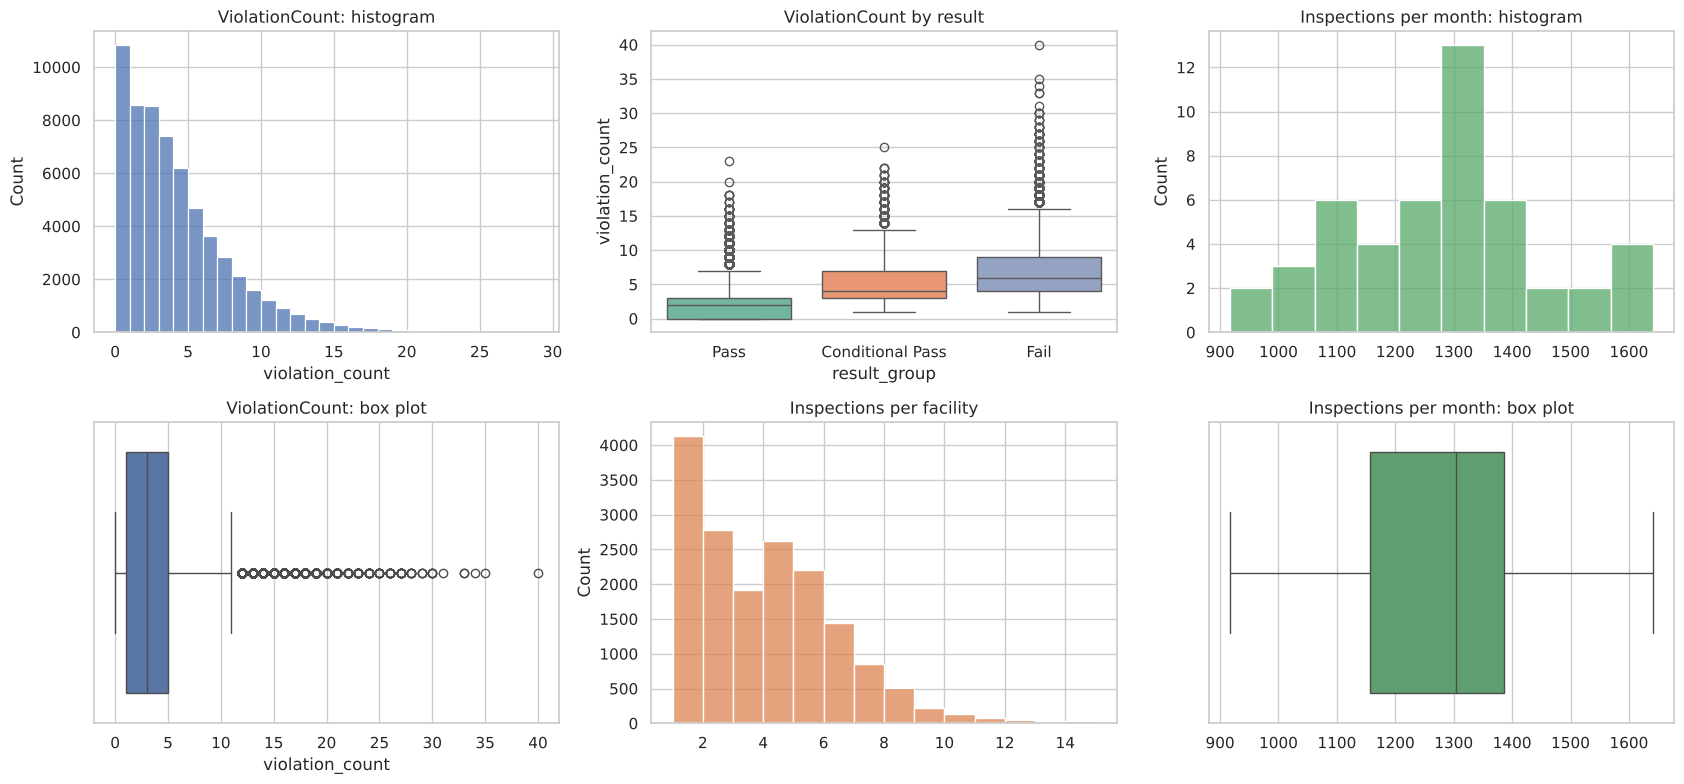

In [18]:
fig, ax = plt.subplots(2, 3, figsize=(17, 8))
sns.histplot(comp["violation_count"].dropna(), bins=range(0, 30), ax=ax[0, 0], color="#4C72B0")
ax[0, 0].set_title("ViolationCount: histogram")
sns.boxplot(x=comp["violation_count"].dropna(), ax=ax[1, 0], color="#4C72B0")
ax[1, 0].set_title("ViolationCount: box plot")
sns.boxplot(data=comp, x="result_group", y="violation_count", order=["Pass", "Conditional Pass", "Fail"], hue="result_group", hue_order=["Pass", "Conditional Pass", "Fail"], legend=False, ax=ax[0, 1], palette="Set2")
ax[0, 1].set_title("ViolationCount by result")
sns.histplot(per_facility, bins=range(1, 16), ax=ax[1, 1], color="#DD8452")
ax[1, 1].set_title("Inspections per facility")
sns.histplot(monthly.values, bins=10, ax=ax[0, 2], color="#55A868")
ax[0, 2].set_title("Inspections per month: histogram")
sns.boxplot(x=monthly.values, ax=ax[1, 2], color="#55A868")
ax[1, 2].set_title("Inspections per month: box plot")
plt.tight_layout(); plt.show()

**Inference (numerical analysis):**
- **ViolationCount** (61,185 inspections with a known count): mean 3.77, median 3, Q1 = 1, Q3 = 5, IQR = 4, standard deviation 3.70, maximum 40. The skewness of 1.64 and kurtosis of 4.03 show a long right tail: most inspections cite 0-5 violations, but a few cite more than 20, and the mean is above the median. The box plot marks everything above 11 as an outlier; these inspections are kept (see the data-quality report).
- By result the count rises clearly: mean 2.25 for *Pass*, 5.16 for *Pass w/ Conditions* and 6.94 for *Fail*.
- **Inspections per facility** (17,001 facilities with a licence): mean 3.6, median 3, maximum 25 over the four years, so repeat visits are normal. The long tail comes from facilities that are re-inspected many times.
- **Inspections per month:** mean 1,286 and median 1,304, with a skewness near 0 (0.05), so the monthly volume is roughly symmetric (minimum 917, maximum 1,641) and no month is an outlier.

## B. Categorical analysis

In [19]:
def freq(col, data=df, top=None):
    f = data[col].value_counts(dropna=False).rename("count").to_frame()
    f["percent"] = (f["count"] / f["count"].sum() * 100).round(2)
    return f.head(top) if top else f

for col in ["result_group", "risk_group", "facility_group", "inspection_type_group"]:
    print(f"--- {col}"); display(freq(col))

ft = freq("facility_type_clean")
print("Top 10 raw-derived facility types:"); display(ft.head(10))
rare = ft[ft["percent"] < 0.1]
print(f"Rare facility types (< 0.1% of rows): {len(rare)} of {len(ft)} categories, together {rare['count'].sum()} rows ({rare['percent'].sum():.2f}%)")

--- result_group


,count,percent
result_group,,
Pass,37734,51.27
Fail,14260,19.37
Not Completed,11864,16.12
Conditional Pass,9743,13.24


--- risk_group


,count,percent
risk_group,,
High,59151,80.37
Medium,10869,14.77
Low,3526,4.79
Unknown,55,0.07


--- facility_group


,count,percent
facility_group,,
Restaurant & Food Service,52217,70.95
Schools & Childcare,9193,12.49
Retail Food & Grocery,8626,11.72
"Mobile, Catering & Events",1822,2.48
Healthcare & Residential Care,1404,1.91
Unknown,320,0.43
Other,19,0.03


--- inspection_type_group


,count,percent
inspection_type_group,,
Routine (Canvass),36278,49.29
Re-inspection,14629,19.88
License,9772,13.28
Complaint / Illness,8701,11.82
Other,4221,5.73


Top 10 raw-derived facility types:


,count,percent
facility_type_clean,,
Restaurant,51991,70.64
Grocery Store,7062,9.59
School,4608,6.26
Children's Services Facility,2628,3.57
Daycare Above And Under 2 Years,1104,1.50
Bakery,1013,1.38
Long Term Care,773,1.05
Catering,476,0.65
Daycare (2 - 6 Years),470,0.64


Rare facility types (< 0.1% of rows): 184 of 203 categories, together 1337 rows (1.74%)


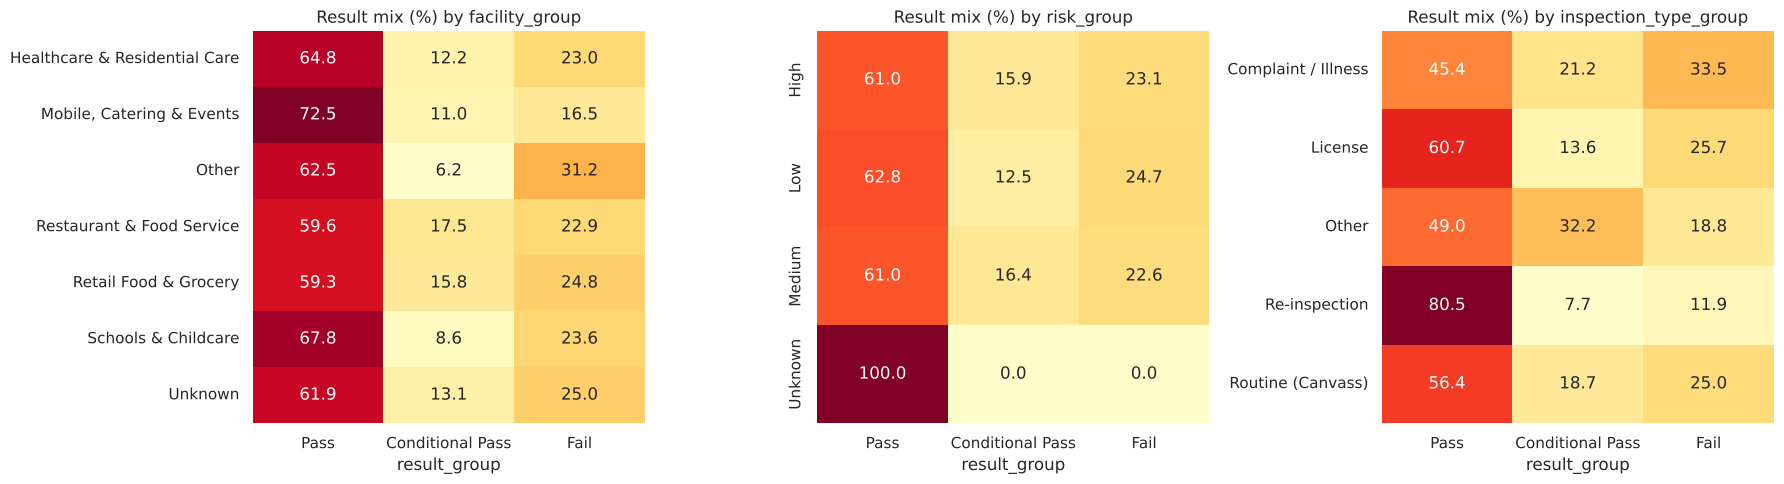

Counts behind the first heat map:


result_group,Conditional Pass,Fail,Pass,All
facility_group,,,,
Healthcare & Residential Care,159,299,843,1301
"Mobile, Catering & Events",167,249,1097,1513
Other,1,5,10,16
Restaurant & Food Service,7535,9878,25644,43057
Retail Food & Grocery,1129,1771,4229,7129
Schools & Childcare,741,2037,5859,8637
Unknown,11,21,52,84
All,9743,14260,37734,61737


In [20]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, col in zip(ax, ["facility_group", "risk_group", "inspection_type_group"]):
    ct = pd.crosstab(comp[col], comp["result_group"], normalize="index")[["Pass", "Conditional Pass", "Fail"]] * 100
    sns.heatmap(ct, annot=True, fmt=".1f", cmap="YlOrRd", ax=a, cbar=False)
    a.set_title(f"Result mix (%) by {col}"); a.set_ylabel("")
plt.tight_layout(); plt.show()
print("Counts behind the first heat map:")
pd.crosstab(comp["facility_group"], comp["result_group"], margins=True)

**Inference (categorical analysis):**
- Of all 73,601 curated rows, 51.3% are *Pass*, 19.4% *Fail*, 13.2% *Conditional Pass* and 16.1% *Not Completed*. Among the 61,737 **completed** inspections the shares are 61.1% Pass, 15.8% Conditional Pass and 23.1% Fail.
- 80.4% of the inspections are of **high-risk** facilities and 71% are of restaurants (Restaurant & Food Service). Schools and childcare (12.5%) and retail food and grocery (11.7%) are the next groups.
- **Rare categories:** the raw facility type has 203 spellings, and 184 of them each cover less than 0.1% of the rows (1.74% of rows in total). This is why the derived FacilityGroup is needed for analysis.
- **Cross-tabulation with the result:** the fail share is similar across the big groups (retail 24.8%, schools 23.6%, healthcare and residential care 23.0%, restaurants 22.9%) and lowest for mobile, catering and events (16.5%).
- **Risk and result:** the result mix is almost the same for High (23.1% fail), Medium (22.6%) and Low risk (24.7%). The risk category tells us how often a place is inspected, but not how likely it is to fail on a given visit.
- **Inspection type:** complaint and illness inspections fail most often (33.5%), then licence (25.8%) and routine canvass (25.0%). **Re-inspections** fail least (11.9%), which suggests most businesses fix their problems after a failed visit.

## C. Temporal analysis

,inspections,fail_rate
year,,
2022,14281,24.88
2023,15412,24.88
2024,15992,21.77
2025,16052,21.13


quarter,1,2,3,4
year,,,,
2022,3091,3760,3807,3623
2023,3708,3906,3818,3980
2024,3715,4187,4054,4036
2025,4269,4246,3890,3647


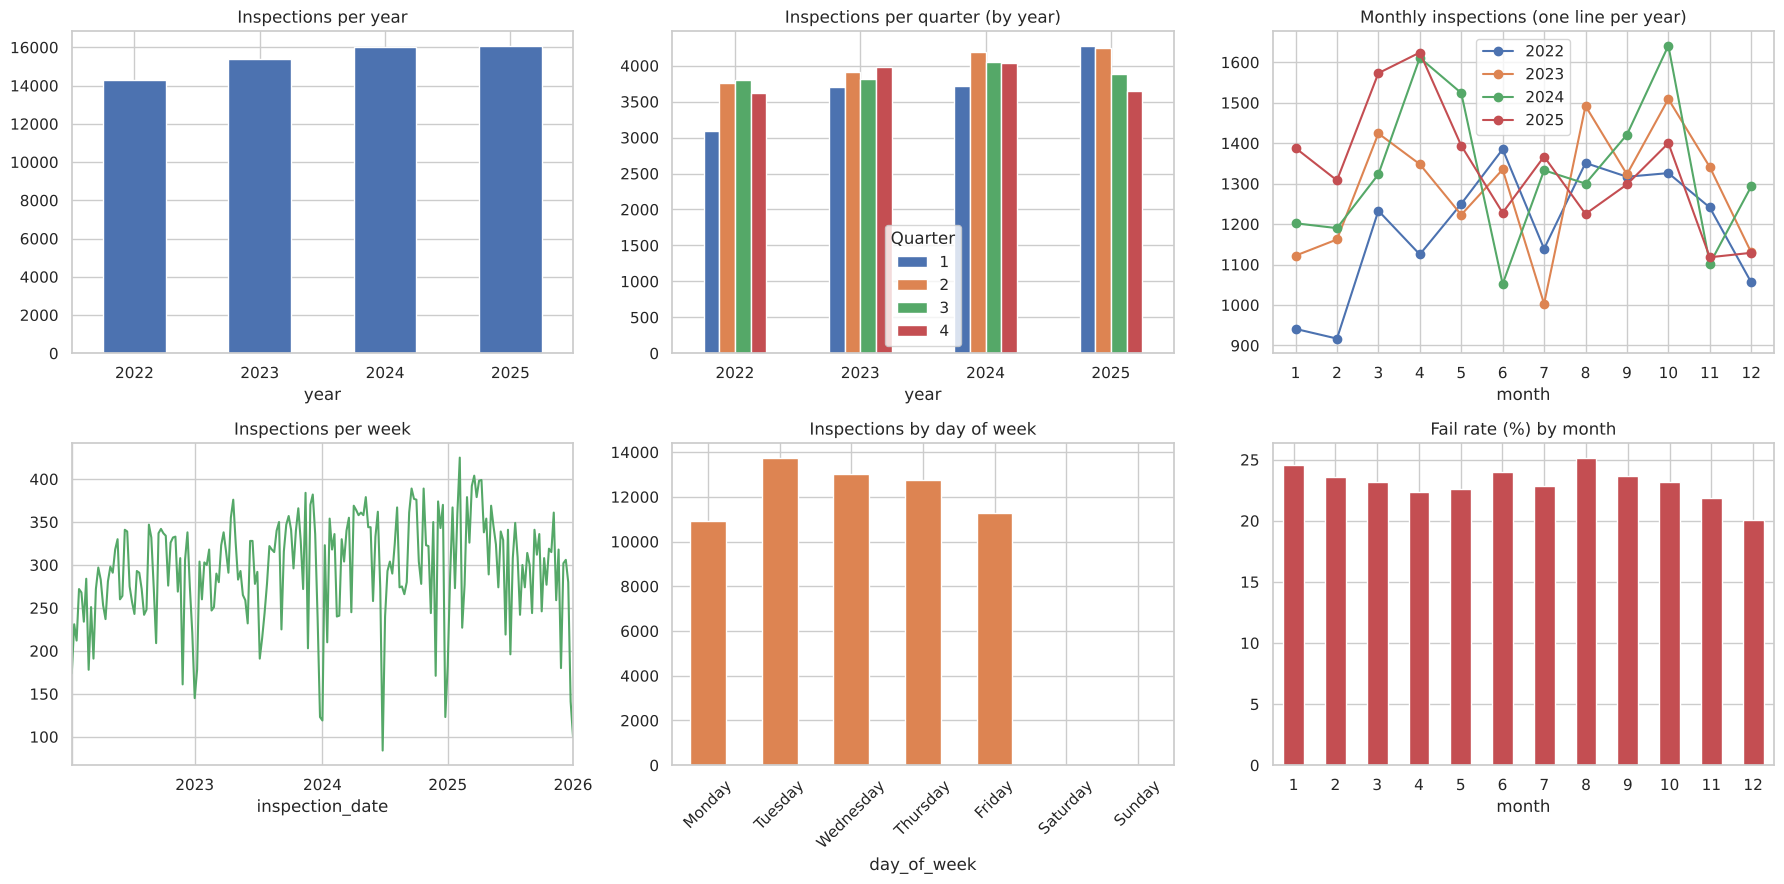

Busiest months : {Period('2024-10', 'M'): 1641, Period('2025-04', 'M'): 1624, Period('2024-04', 'M'): 1611}
Quietest months: {Period('2022-02', 'M'): 917, Period('2022-01', 'M'): 941, Period('2023-07', 'M'): 1003}
Hourly / time-band pattern: NOT AVAILABLE (every timestamp is 00:00:00 in the source).


In [21]:
yearly = comp.groupby("year").agg(inspections=("inspection_id", "size"), fail_rate=("is_failed_inspection", "mean"))
yearly["fail_rate"] = (yearly["fail_rate"] * 100).round(2)
quarterly = comp.groupby(["year", "quarter"]).size().unstack()
display(yearly); display(quarterly)

fig, ax = plt.subplots(2, 3, figsize=(18, 9))
yearly["inspections"].plot(kind="bar", ax=ax[0, 0], color="#4C72B0"); ax[0, 0].set_title("Inspections per year"); ax[0, 0].tick_params(axis="x", rotation=0)
quarterly.plot(kind="bar", ax=ax[0, 1]); ax[0, 1].set_title("Inspections per quarter (by year)"); ax[0, 1].tick_params(axis="x", rotation=0); ax[0, 1].legend(title="Quarter")
for y, g in comp.groupby("year"):
    g.groupby("month").size().plot(ax=ax[0, 2], marker="o", label=str(y))
ax[0, 2].set_title("Monthly inspections (one line per year)"); ax[0, 2].set_xticks(range(1, 13)); ax[0, 2].legend()
weekly = comp.set_index("inspection_date").resample("W").size()
weekly.plot(ax=ax[1, 0], color="#55A868"); ax[1, 0].set_title("Inspections per week")
dow = comp["day_of_week"].value_counts().reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
dow.plot(kind="bar", ax=ax[1, 1], color="#DD8452"); ax[1, 1].set_title("Inspections by day of week"); ax[1, 1].tick_params(axis="x", rotation=45)
comp.groupby("month")["is_failed_inspection"].mean().mul(100).plot(kind="bar", ax=ax[1, 2], color="#C44E52")
ax[1, 2].set_title("Fail rate (%) by month"); ax[1, 2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

by_month = comp.groupby(comp["inspection_date"].dt.to_period("M")).size()
print("Busiest months :", by_month.nlargest(3).to_dict())
print("Quietest months:", by_month.nsmallest(3).to_dict())
print("Hourly / time-band pattern: NOT AVAILABLE (every timestamp is 00:00:00 in the source).")

**Inference (temporal analysis):**
- **Yearly:** completed inspections grew from 14,281 (2022) to 15,412 (2023), 15,992 (2024) and 16,052 (2025), about 12% more in four years. The fail rate fell from 24.9% (2022 and 2023) to 21.8% (2024) and 21.1% (2025).
- **Quarterly:** Q1 2022 was the quietest quarter (3,091) and Q1 2025 the busiest (4,269). The busiest quarter changes every year (Q3 in 2022, Q4 in 2023, Q2 in 2024, Q1 in 2025), so there is no stable seasonal peak.
- **Monthly:** the busiest months were October 2024 (1,641), April 2025 (1,624) and April 2024 (1,611). The quietest were February 2022 (917), January 2022 (941) and July 2023 (1,003).
- **Day of week:** inspections happen on weekdays; Tuesday (13,725) and Wednesday (13,019) are busiest and Monday (10,936) the quietest weekday. Only 5 completed inspections took place on a Saturday and none on a Sunday.
- **Season:** the fail rate is highest in August (25.1%), January (24.5%) and June (24.0%) and lowest in December (20.1%) and November (21.8%).
- **Hourly pattern:** not available, because the source has no time of day.

## D. Geographic analysis

In [22]:
geo_ok = comp["latitude"].notna()
print("Coordinates available for %.2f%% of completed inspections; none lie outside the Chicago bounding box (validated in curation)." % (geo_ok.mean() * 100))

area = comp.groupby("geographic_area_group").agg(inspections=("inspection_id", "size"), fail_rate=("is_failed_inspection", "mean"))
area["fail_rate"] = (area["fail_rate"] * 100).round(2)
display(area)

zip_t = comp[comp["zip"] != "Unknown"].groupby("zip").agg(inspections=("inspection_id", "size"), fails=("is_failed_inspection", "sum"))
zip_t["fail_rate"] = (zip_t["fails"] / zip_t["inspections"] * 100).round(2)
big = zip_t[zip_t["inspections"] >= 200]
print("Top 8 ZIP codes by NUMBER of inspections:");   display(zip_t.nlargest(8, "inspections"))
print("Top 8 ZIP codes by FAIL RATE (at least 200 inspections):"); display(big.nlargest(8, "fail_rate"))

Coordinates available for 99.62% of completed inspections; none lie outside the Chicago bounding box (validated in curation).


,inspections,fail_rate
geographic_area_group,,
Northeast,2906,18.93
Northwest,32608,21.80
Southeast,7963,26.71
Southwest,18028,24.56
Unknown,232,19.40


Top 8 ZIP codes by NUMBER of inspections:


,inspections,fails,fail_rate
zip,,,
60647,2361,508,21.52
60614,2227,543,24.38
60611,2078,420,20.21
60622,2031,515,25.36
60607,1991,423,21.25
60618,1973,351,17.79
60608,1967,536,27.25
60616,1940,516,26.60


Top 8 ZIP codes by FAIL RATE (at least 200 inspections):


,inspections,fails,fail_rate
zip,,,
60617,1403,526,37.49
60620,1179,394,33.42
60628,1077,349,32.40
60619,1220,378,30.98
60636,687,210,30.57
60651,836,251,30.02
60621,438,131,29.91
60639,1701,508,29.86


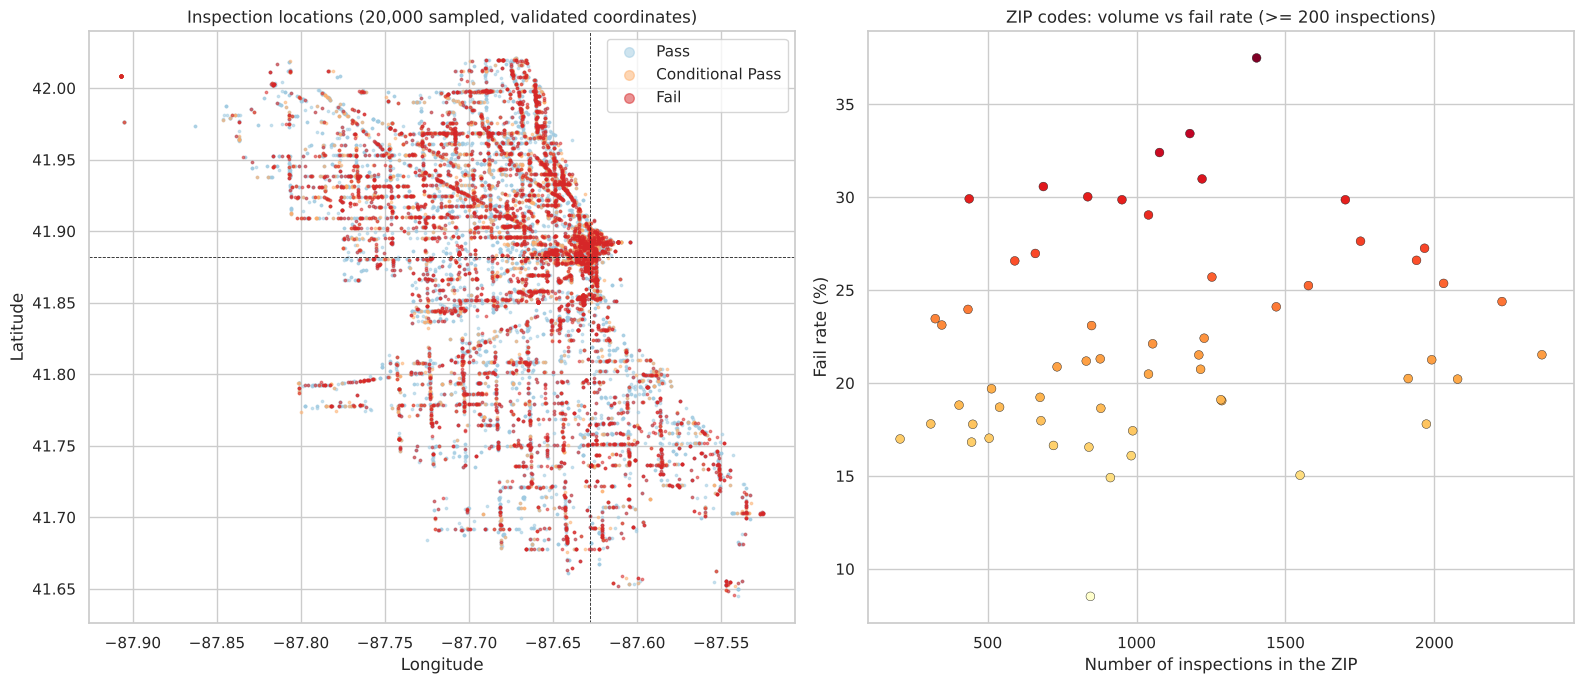

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(16, 7))
s = comp[geo_ok].sample(min(20000, geo_ok.sum()), random_state=1)
for res, colour in [("Pass", "#9ecae1"), ("Conditional Pass", "#fdae6b"), ("Fail", "#d62728")]:
    g = s[s["result_group"] == res]
    ax[0].scatter(g["longitude"], g["latitude"], s=3, alpha=0.5, c=colour, label=res)
ax[0].set_title("Inspection locations (20,000 sampled, validated coordinates)"); ax[0].set_xlabel("Longitude"); ax[0].set_ylabel("Latitude"); ax[0].legend(markerscale=4)
ax[0].axhline(41.8820, color="k", lw=0.6, ls="--"); ax[0].axvline(-87.6278, color="k", lw=0.6, ls="--")
sc = ax[1].scatter(big["inspections"], big["fail_rate"], s=40, c=big["fail_rate"], cmap="YlOrRd", edgecolor="k", linewidth=0.3)
ax[1].set_xlabel("Number of inspections in the ZIP"); ax[1].set_ylabel("Fail rate (%)"); ax[1].set_title("ZIP codes: volume vs fail rate (>= 200 inspections)")
plt.tight_layout(); plt.show()

**Inference (geographic analysis):**
- Coordinates exist for 99.62% of the completed inspections and all of them lie inside the Chicago box. The scatter plot draws the shape of the city and the street grid, which is a good visual check that the coordinates are valid. The dashed lines mark the origin of the street grid (State and Madison) used for the area groups.
- **Area groups:** the failure rate is highest in the Southeast (26.7%) and Southwest (24.6%) and lower in the Northwest (21.8%) and Northeast (18.9%).
- **Volume is not rate:** the ZIP codes with the most inspections (60647: 2,361, 60614: 2,227, 60611: 2,078) have fail rates between 20% and 24%. The highest fail rates are in 60617 (37.5%), 60620 (33.4%) and 60628 (32.4%), all ZIPs with fewer inspections. For example 60618 is 6th by volume but has the lowest fail rate (17.8%) of the eight busiest ZIP codes. Ranking areas by raw totals would point to the wrong places.
- The right-hand scatter plot shows that the fail rate does not depend on volume: high rates occur at both small and large volumes.

## E. Outcome / performance analysis (volume versus rate)

,inspections,fails,conditional,avg_violations,fail_rate_%,conditional_rate_%
facility_group,,,,,,
Restaurant & Food Service,43057,9878,7535,4.06,22.94,17.50
Schools & Childcare,8637,2037,741,2.44,23.58,8.58
Retail Food & Grocery,7129,1771,1129,4.14,24.84,15.84
"Mobile, Catering & Events",1513,249,167,2.14,16.46,11.04
Healthcare & Residential Care,1301,299,159,3.30,22.98,12.22
Unknown,84,21,11,2.79,25.00,13.10
Other,16,5,1,2.33,31.25,6.25


,inspections,fail_rate
inspection_type_group,,
Complaint / Illness,8121,33.47
License,8102,25.75
Routine (Canvass),30875,24.96
Other,149,18.79
Re-inspection,14490,11.88


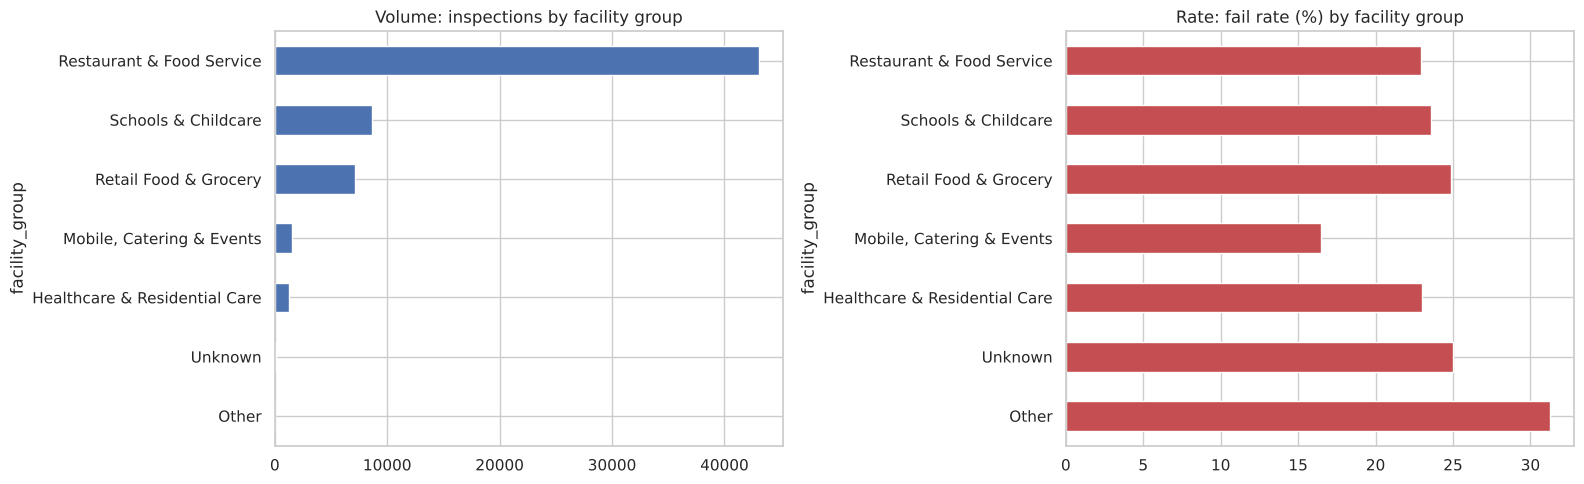

In [24]:
fg = comp.groupby("facility_group").agg(inspections=("inspection_id", "size"), fails=("is_failed_inspection", "sum"),
                                         conditional=("result_group", lambda s: (s == "Conditional Pass").sum()),
                                         avg_violations=("violation_count", "mean"))
fg["fail_rate_%"] = (fg["fails"] / fg["inspections"] * 100).round(2)
fg["conditional_rate_%"] = (fg["conditional"] / fg["inspections"] * 100).round(2)
fg["avg_violations"] = fg["avg_violations"].round(2)
fg = fg.sort_values("inspections", ascending=False)
display(fg)

it = comp.groupby("inspection_type_group").agg(inspections=("inspection_id", "size"), fail_rate=("is_failed_inspection", "mean"))
it["fail_rate"] = (it["fail_rate"] * 100).round(2)
display(it.sort_values("fail_rate", ascending=False))

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
fg["inspections"].plot(kind="barh", ax=ax[0], color="#4C72B0"); ax[0].set_title("Volume: inspections by facility group"); ax[0].invert_yaxis()
fg["fail_rate_%"].plot(kind="barh", ax=ax[1], color="#C44E52"); ax[1].set_title("Rate: fail rate (%) by facility group"); ax[1].invert_yaxis()
plt.tight_layout(); plt.show()

**Inference (outcome analysis, volume versus rate):**
- **Restaurants** make up 70% of all completed inspections and 69% of all failures (9,878 of 14,260), but their fail rate of 22.9% is close to the overall 23.1%. They are the biggest in volume, not the worst in rate.
- **Retail food and grocery** has the highest fail rate among the large groups (24.8%) and the highest average violation count (4.14).
- **Schools and childcare** fail 23.6% of the time with a low average violation count (2.44) and a low conditional-pass rate (8.6%), which means a school usually fails because of a few serious findings and not because of many small ones.
- **Mobile, catering and events** has the lowest fail rate (16.5%), but it has only 1,513 inspections.
- By inspection type, a complaint or illness inspection is almost three times as likely to fail as a re-inspection (33.5% vs 11.9%).
- The comparison of the two bar charts shows why both counts and rates are needed: the order of the groups is different in the volume chart and in the rate chart.

In [25]:
os.chdir(WORK)

# Parts B and C. Dimensional models and the PostgreSQL batch warehouse
Selected model: **fact constellation** (star schema + a facility-by-year fact). The snowflake is built too, to measure the comparison.

**`sql/01_schema.sql`**: staging tables, dimensions with Unknown members, the two fact tables, date dimension.

In [26]:
%%writefile Project/sql/01_schema.sql
-- Part C: PostgreSQL batch data warehouse (staging + dimensional model).
-- Selected model: FACT CONSTELLATION = star schema (FactInspection) + a second fact at Facility x Year grain
-- sharing the conformed DimFacility.  Grain of FactInspection: one completed inspection on one date.

DROP SCHEMA IF EXISTS staging CASCADE;
DROP SCHEMA IF EXISTS dw CASCADE;
CREATE SCHEMA staging;
CREATE SCHEMA dw;

-- ------------------------------------------------------------------ staging
CREATE TABLE staging.inspection_stg (
    inspection_id bigint, dba_name text, aka_name text, license_number text, facility_nk text, facility_id_source text,
    facility_type_clean text, facility_group text, risk_category text, risk_group text, address text, city text, state text, zip text,
    inspection_date date, inspection_type text, inspection_type_group text, results text, result_group text,
    is_completed boolean, is_failed_inspection int, violation_count numeric, has_violations numeric, high_violation_flag int,
    violation_band text, violation_codes text, latitude numeric, longitude numeric, latitude_band numeric, longitude_band numeric,
    geographic_area_group text, year int, quarter int, month int, day_of_week text, is_weekend boolean, season text,
    is_same_day_repeat boolean, is_extreme_violation_count boolean,
    batch_id int NOT NULL, reject_reason text, staged_at timestamptz DEFAULT now()
);

CREATE TABLE staging.load_audit (
    batch_id serial PRIMARY KEY, batch_label text, period_from date, period_to date,
    rows_staged int, rows_rejected int, rows_not_completed int, rows_loaded_fact int,
    new_facilities int, new_locations int, annual_rows_refreshed int,
    started_at timestamptz DEFAULT now(), finished_at timestamptz, status text DEFAULT 'running'
);

-- ------------------------------------------------------------------ dimensions
CREATE TABLE dw.dim_date (
    date_key int PRIMARY KEY, full_date date NOT NULL UNIQUE, day smallint, day_name text, month smallint, month_name text,
    quarter smallint, year smallint, is_weekend boolean, season text
);
CREATE TABLE dw.dim_facility (
    facility_key serial PRIMARY KEY, facility_nk text NOT NULL UNIQUE, license_number text, dba_name text,
    facility_type text, facility_group text, risk_category text, risk_group text, facility_id_source text,
    last_inspection_date date, created_batch int, updated_batch int
);
CREATE TABLE dw.dim_inspection_type (
    inspection_type_key serial PRIMARY KEY, inspection_type text NOT NULL UNIQUE, inspection_type_group text
);
CREATE TABLE dw.dim_result (
    result_key serial PRIMARY KEY, result text NOT NULL UNIQUE, result_group text, failure_flag smallint
);
CREATE TABLE dw.dim_location (
    location_key serial PRIMARY KEY, zip text, city text, latitude_band text, longitude_band text, geographic_area_group text,
    UNIQUE (zip, city, latitude_band, longitude_band, geographic_area_group)
);

-- explicit Unknown / Not Available members (key 0): used when a lookup finds nothing, so facts are never dropped
INSERT INTO dw.dim_facility (facility_key, facility_nk, dba_name, facility_type, facility_group, risk_category, risk_group, facility_id_source)
VALUES (0, 'UNKNOWN', 'Unknown', 'Unknown', 'Unknown', 'Unknown', 'Unknown', 'Unknown');
INSERT INTO dw.dim_inspection_type (inspection_type_key, inspection_type, inspection_type_group) VALUES (0, 'Unknown', 'Other');
INSERT INTO dw.dim_result (result_key, result, result_group, failure_flag) VALUES (0, 'Unknown', 'Not Completed', 0);
INSERT INTO dw.dim_location (location_key, zip, city, latitude_band, longitude_band, geographic_area_group)
VALUES (0, 'Unknown', 'UNKNOWN', 'Unknown', 'Unknown', 'Unknown');

INSERT INTO dw.dim_date
SELECT to_char(d, 'YYYYMMDD')::int, d::date, extract(day FROM d), trim(to_char(d, 'Day')), extract(month FROM d), trim(to_char(d, 'Month')),
       extract(quarter FROM d), extract(year FROM d), extract(isodow FROM d) >= 6,
       CASE WHEN extract(month FROM d) IN (12,1,2) THEN 'Winter' WHEN extract(month FROM d) IN (3,4,5) THEN 'Spring'
            WHEN extract(month FROM d) IN (6,7,8) THEN 'Summer' ELSE 'Autumn' END
FROM generate_series('2022-01-01'::date, '2026-12-31'::date, '1 day') AS d;

-- ------------------------------------------------------------------ facts
CREATE TABLE dw.fact_inspection (
    inspection_key bigserial PRIMARY KEY,
    inspection_id bigint NOT NULL UNIQUE,                       -- degenerate dimension (source id)
    date_key int NOT NULL REFERENCES dw.dim_date,
    facility_key int NOT NULL REFERENCES dw.dim_facility,
    inspection_type_key int NOT NULL REFERENCES dw.dim_inspection_type,
    result_key int NOT NULL REFERENCES dw.dim_result,
    location_key int NOT NULL REFERENCES dw.dim_location,
    inspection_count smallint NOT NULL DEFAULT 1,
    violation_count smallint,                                   -- NULL = unknown (see data-quality report)
    fail_count smallint NOT NULL, pass_count smallint NOT NULL, conditional_pass_count smallint NOT NULL,
    high_violation_flag smallint NOT NULL,
    batch_id int NOT NULL, loaded_at timestamptz NOT NULL DEFAULT now()
);

CREATE TABLE dw.fact_facility_annual_inspection_performance (
    facility_key int NOT NULL REFERENCES dw.dim_facility,
    reporting_year smallint NOT NULL,                           -- degenerate time attribute (grain: facility x year)
    inspection_count int NOT NULL, fail_count int NOT NULL, pass_count int NOT NULL, conditional_pass_count int NOT NULL,
    violation_count int,                                        -- sum over inspections with a known count
    inspections_with_known_violations int NOT NULL,
    average_violations numeric(8,3), failure_rate numeric(6,4),
    batch_id int NOT NULL, loaded_at timestamptz NOT NULL DEFAULT now(),
    PRIMARY KEY (facility_key, reporting_year)
);


Writing Project/sql/01_schema.sql


**`sql/02_load_batch.sql`**: the PL/pgSQL load procedure `dw.load_batch`: data-quality rules, dimension inserts, fact load, annual fact. Used for the initial and the incremental load.

In [27]:
%%writefile Project/sql/02_load_batch.sql
-- ETL: staging -> data-quality rules -> dimension lookups / inserts -> fact load -> annual fact -> validation counts.
-- The same procedure is used for the initial load and for the incremental load.
CREATE OR REPLACE PROCEDURE dw.load_batch(p_batch int)
LANGUAGE plpgsql AS $$
DECLARE
    v_staged int; v_rejected int; v_notcomp int; v_fact int; v_newfac int; v_newloc int; v_annual int; v_before int;
BEGIN
    SELECT count(*) INTO v_staged FROM staging.inspection_stg WHERE batch_id = p_batch;

    -- 1. data-quality rules
    UPDATE staging.inspection_stg SET reject_reason = 'missing inspection_id or inspection_date'
     WHERE batch_id = p_batch AND (inspection_id IS NULL OR inspection_date IS NULL);
    UPDATE staging.inspection_stg s SET reject_reason = 'date not in dim_date'
     WHERE batch_id = p_batch AND reject_reason IS NULL AND NOT EXISTS (SELECT 1 FROM dw.dim_date d WHERE d.full_date = s.inspection_date);
    UPDATE staging.inspection_stg s SET reject_reason = 'already loaded (inspection_id exists in fact)'
     WHERE batch_id = p_batch AND reject_reason IS NULL AND EXISTS (SELECT 1 FROM dw.fact_inspection f WHERE f.inspection_id = s.inspection_id);
    SELECT count(*) INTO v_rejected FROM staging.inspection_stg WHERE batch_id = p_batch AND reject_reason IS NOT NULL;
    SELECT count(*) INTO v_notcomp FROM staging.inspection_stg WHERE batch_id = p_batch AND reject_reason IS NULL AND NOT is_completed;

    -- 2. dimensions: insert new members (completed inspections only)
    INSERT INTO dw.dim_inspection_type (inspection_type, inspection_type_group)
    SELECT DISTINCT s.inspection_type, s.inspection_type_group FROM staging.inspection_stg s
     WHERE s.batch_id = p_batch AND s.reject_reason IS NULL AND s.is_completed
    ON CONFLICT (inspection_type) DO NOTHING;

    INSERT INTO dw.dim_result (result, result_group, failure_flag)
    SELECT DISTINCT s.results, s.result_group, s.is_failed_inspection FROM staging.inspection_stg s
     WHERE s.batch_id = p_batch AND s.reject_reason IS NULL AND s.is_completed
    ON CONFLICT (result) DO NOTHING;

    SELECT count(*) INTO v_before FROM dw.dim_location;
    INSERT INTO dw.dim_location (zip, city, latitude_band, longitude_band, geographic_area_group)
    SELECT DISTINCT coalesce(s.zip, 'Unknown'), coalesce(s.city, 'UNKNOWN'), coalesce(s.latitude_band::text, 'Unknown'),
           coalesce(s.longitude_band::text, 'Unknown'), s.geographic_area_group
      FROM staging.inspection_stg s WHERE s.batch_id = p_batch AND s.reject_reason IS NULL AND s.is_completed
    ON CONFLICT (zip, city, latitude_band, longitude_band, geographic_area_group) DO NOTHING;
    SELECT count(*) - v_before INTO v_newloc FROM dw.dim_location;

    SELECT count(*) INTO v_before FROM dw.dim_facility;
    INSERT INTO dw.dim_facility (facility_nk, license_number, dba_name, facility_type, facility_group, risk_category, risk_group,
                                 facility_id_source, last_inspection_date, created_batch, updated_batch)
    SELECT DISTINCT ON (s.facility_nk) s.facility_nk, s.license_number, s.dba_name, s.facility_type_clean, s.facility_group,
           s.risk_category, s.risk_group, s.facility_id_source, s.inspection_date, p_batch, p_batch
      FROM staging.inspection_stg s WHERE s.batch_id = p_batch AND s.reject_reason IS NULL AND s.is_completed
     ORDER BY s.facility_nk, s.inspection_date DESC, s.inspection_id DESC
    ON CONFLICT (facility_nk) DO NOTHING;
    SELECT count(*) - v_before INTO v_newfac FROM dw.dim_facility;

    -- existing facilities: Type-1 update (latest inspection wins) when an attribute changed
    UPDATE dw.dim_facility f SET dba_name = l.dba_name, facility_type = l.facility_type_clean, facility_group = l.facility_group,
           risk_category = l.risk_category, risk_group = l.risk_group, last_inspection_date = l.inspection_date, updated_batch = p_batch
      FROM (SELECT DISTINCT ON (facility_nk) * FROM staging.inspection_stg
             WHERE batch_id = p_batch AND reject_reason IS NULL AND is_completed
             ORDER BY facility_nk, inspection_date DESC, inspection_id DESC) l
     WHERE f.facility_nk = l.facility_nk AND l.inspection_date >= coalesce(f.last_inspection_date, '1900-01-01')
       AND (f.dba_name, f.facility_type, f.facility_group, f.risk_category) IS DISTINCT FROM
           (l.dba_name, l.facility_type_clean, l.facility_group, l.risk_category);

    -- 3. fact load (dimension lookups on natural keys; unknown member 0 when no match)
    INSERT INTO dw.fact_inspection (inspection_id, date_key, facility_key, inspection_type_key, result_key, location_key,
                                    violation_count, fail_count, pass_count, conditional_pass_count, high_violation_flag, batch_id)
    SELECT s.inspection_id, d.date_key, coalesce(f.facility_key, 0), coalesce(t.inspection_type_key, 0), coalesce(r.result_key, 0),
           coalesce(l.location_key, 0), s.violation_count::smallint,
           (s.results = 'Fail')::int, (s.results = 'Pass')::int, (s.results = 'Pass w/ Conditions')::int, s.high_violation_flag, p_batch
      FROM staging.inspection_stg s
      JOIN dw.dim_date d ON d.full_date = s.inspection_date
      LEFT JOIN dw.dim_facility f ON f.facility_nk = s.facility_nk
      LEFT JOIN dw.dim_inspection_type t ON t.inspection_type = s.inspection_type
      LEFT JOIN dw.dim_result r ON r.result = s.results
      LEFT JOIN dw.dim_location l ON l.zip = coalesce(s.zip, 'Unknown') AND l.city = coalesce(s.city, 'UNKNOWN')
           AND l.latitude_band = coalesce(s.latitude_band::text, 'Unknown') AND l.longitude_band = coalesce(s.longitude_band::text, 'Unknown')
           AND l.geographic_area_group = s.geographic_area_group
     WHERE s.batch_id = p_batch AND s.reject_reason IS NULL AND s.is_completed
    ON CONFLICT (inspection_id) DO NOTHING;
    GET DIAGNOSTICS v_fact = ROW_COUNT;

    -- 4. second fact (grain: facility x reporting year): rebuild the years touched by this batch
    DELETE FROM dw.fact_facility_annual_inspection_performance
     WHERE reporting_year IN (SELECT DISTINCT year FROM staging.inspection_stg WHERE batch_id = p_batch AND reject_reason IS NULL AND is_completed);
    INSERT INTO dw.fact_facility_annual_inspection_performance
    SELECT f.facility_key, d.year, sum(f.inspection_count), sum(f.fail_count), sum(f.pass_count), sum(f.conditional_pass_count),
           sum(f.violation_count), count(f.violation_count),
           round(avg(f.violation_count), 3), round(sum(f.fail_count)::numeric / sum(f.inspection_count), 4), p_batch, now()
      FROM dw.fact_inspection f JOIN dw.dim_date d USING (date_key)
     WHERE d.year IN (SELECT DISTINCT year FROM staging.inspection_stg WHERE batch_id = p_batch AND reject_reason IS NULL AND is_completed)
     GROUP BY f.facility_key, d.year;
    GET DIAGNOSTICS v_annual = ROW_COUNT;

    UPDATE staging.load_audit SET rows_staged = v_staged, rows_rejected = v_rejected, rows_not_completed = v_notcomp,
           rows_loaded_fact = v_fact, new_facilities = v_newfac, new_locations = v_newloc, annual_rows_refreshed = v_annual,
           finished_at = now(), status = 'loaded' WHERE batch_id = p_batch;
END $$;


Writing Project/sql/02_load_batch.sql


**`sql/03_indexes.sql`**: indexes on the fact table.

In [28]:
%%writefile Project/sql/03_indexes.sql
-- Indexes created after the initial bulk load (faster load, then faster analytics).
CREATE INDEX IF NOT EXISTS ix_fact_date        ON dw.fact_inspection (date_key);
CREATE INDEX IF NOT EXISTS ix_fact_facility    ON dw.fact_inspection (facility_key);
CREATE INDEX IF NOT EXISTS ix_fact_insptype    ON dw.fact_inspection (inspection_type_key);
CREATE INDEX IF NOT EXISTS ix_fact_result      ON dw.fact_inspection (result_key);
CREATE INDEX IF NOT EXISTS ix_fact_location    ON dw.fact_inspection (location_key);
CREATE INDEX IF NOT EXISTS ix_fact_batch       ON dw.fact_inspection (batch_id);
CREATE INDEX IF NOT EXISTS ix_dimdate_ym       ON dw.dim_date (year, month);
CREATE INDEX IF NOT EXISTS ix_dimfac_group     ON dw.dim_facility (facility_group, risk_group);
CREATE INDEX IF NOT EXISTS ix_dimloc_zip       ON dw.dim_location (zip);
CREATE INDEX IF NOT EXISTS ix_annual_year      ON dw.fact_facility_annual_inspection_performance (reporting_year);
ANALYZE;


Writing Project/sql/03_indexes.sql


**`sql/04_validation.sql`**: the integrity and reconciliation checks (all must return 0).

In [29]:
%%writefile Project/sql/04_validation.sql
-- Referential-integrity validation and row/measure reconciliation. Every check must return 0 (or TRUE).
-- name | value
SELECT 'orphan date_key'            AS check_name, count(*)::bigint AS value FROM dw.fact_inspection f LEFT JOIN dw.dim_date d USING (date_key) WHERE d.date_key IS NULL
UNION ALL SELECT 'orphan facility_key',        count(*) FROM dw.fact_inspection f LEFT JOIN dw.dim_facility d USING (facility_key) WHERE d.facility_key IS NULL
UNION ALL SELECT 'orphan inspection_type_key', count(*) FROM dw.fact_inspection f LEFT JOIN dw.dim_inspection_type d USING (inspection_type_key) WHERE d.inspection_type_key IS NULL
UNION ALL SELECT 'orphan result_key',          count(*) FROM dw.fact_inspection f LEFT JOIN dw.dim_result d USING (result_key) WHERE d.result_key IS NULL
UNION ALL SELECT 'orphan location_key',        count(*) FROM dw.fact_inspection f LEFT JOIN dw.dim_location d USING (location_key) WHERE d.location_key IS NULL
UNION ALL SELECT 'orphan annual facility_key', count(*) FROM dw.fact_facility_annual_inspection_performance a LEFT JOIN dw.dim_facility d USING (facility_key) WHERE d.facility_key IS NULL
UNION ALL SELECT 'duplicate inspection_id in fact', count(*) - count(DISTINCT inspection_id) FROM dw.fact_inspection
UNION ALL SELECT 'facts mapped to Unknown facility (key 0)', count(*) FROM dw.fact_inspection WHERE facility_key = 0
UNION ALL SELECT 'facts mapped to Unknown location (key 0)', count(*) FROM dw.fact_inspection WHERE location_key = 0
UNION ALL SELECT 'staging completed rows not in fact', count(*) FROM staging.inspection_stg s
        WHERE s.reject_reason IS NULL AND s.is_completed AND NOT EXISTS (SELECT 1 FROM dw.fact_inspection f WHERE f.inspection_id = s.inspection_id)
UNION ALL SELECT 'fact rows not in staging', count(*) FROM dw.fact_inspection f
        WHERE NOT EXISTS (SELECT 1 FROM staging.inspection_stg s WHERE s.inspection_id = f.inspection_id)
UNION ALL SELECT 'violation_count difference staging vs fact',
        (SELECT coalesce(sum(violation_count), 0) FROM staging.inspection_stg WHERE reject_reason IS NULL AND is_completed)::bigint
      - (SELECT coalesce(sum(violation_count), 0) FROM dw.fact_inspection)::bigint
UNION ALL SELECT 'fail_count difference staging vs fact',
        (SELECT coalesce(sum(is_failed_inspection), 0) FROM staging.inspection_stg WHERE reject_reason IS NULL AND is_completed)::bigint
      - (SELECT coalesce(sum(fail_count), 0) FROM dw.fact_inspection)::bigint
UNION ALL SELECT 'annual fact inspections - fact rows',
        (SELECT coalesce(sum(inspection_count), 0) FROM dw.fact_facility_annual_inspection_performance)::bigint - (SELECT count(*) FROM dw.fact_inspection)
UNION ALL SELECT 'annual fact violations - fact violations',
        (SELECT coalesce(sum(violation_count), 0) FROM dw.fact_facility_annual_inspection_performance)::bigint - (SELECT coalesce(sum(violation_count), 0) FROM dw.fact_inspection)::bigint
UNION ALL SELECT 'batches where staged <> loaded + not_completed + rejected', count(*)
        FROM staging.load_audit WHERE rows_staged <> rows_loaded_fact + rows_not_completed + rows_rejected;


Writing Project/sql/04_validation.sql


**`sql/05_snowflake_schema.sql`**: the snowflake copy of the model, used for the star / snowflake / constellation comparison.

In [30]:
%%writefile Project/sql/05_snowflake_schema.sql
-- Snowflake design: the star dimensions are normalised along their hierarchies
-- (time: year > quarter > month > day; facility: group > type > facility, risk; location: area group, ZIP > location;
--  inspection type group > type; result group > result).  Built from the star dimensions so that the keys are identical.
DROP SCHEMA IF EXISTS snow CASCADE;
CREATE SCHEMA snow;

CREATE TABLE snow.dim_year    (year smallint PRIMARY KEY);
CREATE TABLE snow.dim_quarter (quarter_key serial PRIMARY KEY, year smallint REFERENCES snow.dim_year, quarter smallint, UNIQUE (year, quarter));
CREATE TABLE snow.dim_month   (month_key serial PRIMARY KEY, quarter_key int REFERENCES snow.dim_quarter, month smallint, month_name text, season text, UNIQUE (quarter_key, month));
CREATE TABLE snow.dim_date    (date_key int PRIMARY KEY, full_date date UNIQUE, day smallint, day_name text, is_weekend boolean, month_key int REFERENCES snow.dim_month);

CREATE TABLE snow.dim_facility_group (group_key serial PRIMARY KEY, facility_group text UNIQUE);
CREATE TABLE snow.dim_facility_type  (type_key serial PRIMARY KEY, facility_type text, group_key int REFERENCES snow.dim_facility_group, UNIQUE (facility_type, group_key));
CREATE TABLE snow.dim_risk           (risk_key serial PRIMARY KEY, risk_category text, risk_group text, UNIQUE (risk_category, risk_group));
CREATE TABLE snow.dim_facility       (facility_key int PRIMARY KEY, facility_nk text UNIQUE, license_number text, dba_name text,
                                      facility_id_source text, type_key int REFERENCES snow.dim_facility_type, risk_key int REFERENCES snow.dim_risk);

CREATE TABLE snow.dim_inspection_type_group (group_key serial PRIMARY KEY, inspection_type_group text UNIQUE);
CREATE TABLE snow.dim_inspection_type (inspection_type_key int PRIMARY KEY, inspection_type text, group_key int REFERENCES snow.dim_inspection_type_group);
CREATE TABLE snow.dim_result_group (group_key serial PRIMARY KEY, result_group text UNIQUE);
CREATE TABLE snow.dim_result (result_key int PRIMARY KEY, result text, failure_flag smallint, group_key int REFERENCES snow.dim_result_group);

CREATE TABLE snow.dim_area_group (area_key serial PRIMARY KEY, geographic_area_group text UNIQUE);
CREATE TABLE snow.dim_zip        (zip_key serial PRIMARY KEY, zip text, city text, UNIQUE (zip, city));
CREATE TABLE snow.dim_location   (location_key int PRIMARY KEY, zip_key int REFERENCES snow.dim_zip, area_key int REFERENCES snow.dim_area_group, latitude_band text, longitude_band text);

CREATE TABLE snow.fact_inspection (
    inspection_key bigint PRIMARY KEY, inspection_id bigint UNIQUE, date_key int REFERENCES snow.dim_date, facility_key int REFERENCES snow.dim_facility,
    inspection_type_key int REFERENCES snow.dim_inspection_type, result_key int REFERENCES snow.dim_result, location_key int REFERENCES snow.dim_location,
    inspection_count smallint, violation_count smallint, fail_count smallint, pass_count smallint, conditional_pass_count smallint, high_violation_flag smallint);

-- ---- populate from the star schema
INSERT INTO snow.dim_year SELECT DISTINCT year FROM dw.dim_date;
INSERT INTO snow.dim_quarter (year, quarter) SELECT DISTINCT year, quarter FROM dw.dim_date;
INSERT INTO snow.dim_month (quarter_key, month, month_name, season)
    SELECT DISTINCT q.quarter_key, d.month, d.month_name, d.season FROM dw.dim_date d JOIN snow.dim_quarter q ON q.year = d.year AND q.quarter = d.quarter;
INSERT INTO snow.dim_date SELECT d.date_key, d.full_date, d.day, d.day_name, d.is_weekend, m.month_key
    FROM dw.dim_date d JOIN snow.dim_quarter q ON q.year = d.year AND q.quarter = d.quarter JOIN snow.dim_month m ON m.quarter_key = q.quarter_key AND m.month = d.month;

INSERT INTO snow.dim_facility_group (facility_group) SELECT DISTINCT facility_group FROM dw.dim_facility;
INSERT INTO snow.dim_facility_type (facility_type, group_key)
    SELECT DISTINCT f.facility_type, g.group_key FROM dw.dim_facility f JOIN snow.dim_facility_group g ON g.facility_group = f.facility_group;
INSERT INTO snow.dim_risk (risk_category, risk_group) SELECT DISTINCT risk_category, risk_group FROM dw.dim_facility;
INSERT INTO snow.dim_facility
    SELECT f.facility_key, f.facility_nk, f.license_number, f.dba_name, f.facility_id_source, t.type_key, r.risk_key
      FROM dw.dim_facility f JOIN snow.dim_facility_group g ON g.facility_group = f.facility_group
      JOIN snow.dim_facility_type t ON t.facility_type = f.facility_type AND t.group_key = g.group_key
      JOIN snow.dim_risk r ON r.risk_category = f.risk_category AND r.risk_group = f.risk_group;

INSERT INTO snow.dim_inspection_type_group (inspection_type_group) SELECT DISTINCT inspection_type_group FROM dw.dim_inspection_type;
INSERT INTO snow.dim_inspection_type SELECT t.inspection_type_key, t.inspection_type, g.group_key
    FROM dw.dim_inspection_type t JOIN snow.dim_inspection_type_group g ON g.inspection_type_group = t.inspection_type_group;
INSERT INTO snow.dim_result_group (result_group) SELECT DISTINCT result_group FROM dw.dim_result;
INSERT INTO snow.dim_result SELECT r.result_key, r.result, r.failure_flag, g.group_key FROM dw.dim_result r JOIN snow.dim_result_group g ON g.result_group = r.result_group;

INSERT INTO snow.dim_area_group (geographic_area_group) SELECT DISTINCT geographic_area_group FROM dw.dim_location;
INSERT INTO snow.dim_zip (zip, city) SELECT DISTINCT zip, city FROM dw.dim_location;
INSERT INTO snow.dim_location SELECT l.location_key, z.zip_key, a.area_key, l.latitude_band, l.longitude_band
    FROM dw.dim_location l JOIN snow.dim_zip z ON z.zip = l.zip AND z.city = l.city JOIN snow.dim_area_group a ON a.geographic_area_group = l.geographic_area_group;

INSERT INTO snow.fact_inspection
    SELECT inspection_key, inspection_id, date_key, facility_key, inspection_type_key, result_key, location_key,
           inspection_count, violation_count, fail_count, pass_count, conditional_pass_count, high_violation_flag FROM dw.fact_inspection;

CREATE INDEX ON snow.fact_inspection (date_key);  CREATE INDEX ON snow.fact_inspection (facility_key);
CREATE INDEX ON snow.fact_inspection (inspection_type_key);  CREATE INDEX ON snow.fact_inspection (result_key);  CREATE INDEX ON snow.fact_inspection (location_key);
ANALYZE;


Writing Project/sql/05_snowflake_schema.sql


**`etl/run_etl.py`**: the batch ETL driver: stage, load, validate, incremental load of the held-back month (Dec 2025), idempotency test.

In [31]:
%%writefile Project/etl/run_etl.py
"""Batch ETL driver:  Extract (curated CSV) -> Stage -> Data-quality rules -> Dimension lookups -> Fact load -> Validate.

  python etl/run_etl.py all          # create schema, initial load (Jan 2022-Nov 2025), indexes, validation,
                                     # then the incremental load of the held-back month (Dec 2025) and validation
  python etl/run_etl.py initial | incremental | validate
"""
import io, sys, time, csv
from pathlib import Path
import pandas as pd
import psycopg2

ROOT = Path(__file__).resolve().parents[1]
SQL = ROOT / "sql"
CURATED = ROOT / "data" / "curated" / "inspections_curated.csv"
RESULTS = ROOT / "results"
DSN = "host=localhost port=5432 dbname=foodsafety user=foodsafety password=foodsafety"
HOLD_BACK_FROM = "2025-12-01"          # the final month is loaded incrementally

STAGING_COLS = ["inspection_id", "dba_name", "aka_name", "license_number", "facility_nk", "facility_id_source", "facility_type_clean",
                "facility_group", "risk_category", "risk_group", "address", "city", "state", "zip", "inspection_date", "inspection_type",
                "inspection_type_group", "results", "result_group", "is_completed", "is_failed_inspection", "violation_count",
                "has_violations", "high_violation_flag", "violation_band", "violation_codes", "latitude", "longitude", "latitude_band",
                "longitude_band", "geographic_area_group", "year", "quarter", "month", "day_of_week", "is_weekend", "season",
                "is_same_day_repeat", "is_extreme_violation_count"]
timings = []


def connect():
    conn = psycopg2.connect(DSN)
    conn.autocommit = True
    return conn


def timed(step, fn):
    t0 = time.perf_counter()
    out = fn()
    dt = time.perf_counter() - t0
    timings.append({"step": step, "seconds": round(dt, 3)})
    print(f"  {step:<55s} {dt:8.3f} s")
    return out


def run_file(conn, name):
    with conn.cursor() as cur:
        cur.execute((SQL / name).read_text())


def load_curated():
    return pd.read_csv(CURATED, parse_dates=["inspection_date"], dtype={"zip": str, "license_number": str})


def stage(conn, df, batch_id):
    out = df[STAGING_COLS].copy()
    out["inspection_date"] = out["inspection_date"].dt.strftime("%Y-%m-%d")
    out["batch_id"] = batch_id
    buf = io.StringIO()
    out.to_csv(buf, index=False, header=False, quoting=csv.QUOTE_MINIMAL)
    buf.seek(0)
    cols = STAGING_COLS + ["batch_id"]
    with conn.cursor() as cur:
        cur.copy_expert(f"COPY staging.inspection_stg ({','.join(cols)}) FROM STDIN WITH (FORMAT csv, NULL '')", buf)


def new_batch(conn, label, d_from, d_to):
    with conn.cursor() as cur:
        cur.execute("INSERT INTO staging.load_audit (batch_label, period_from, period_to) VALUES (%s,%s,%s) RETURNING batch_id", (label, d_from, d_to))
        return cur.fetchone()[0]


def run_batch(conn, df, label, tag):
    d_from, d_to = df["inspection_date"].min().date(), df["inspection_date"].max().date()
    batch_id = timed(f"[{tag}] create audit record", lambda: new_batch(conn, label, d_from, d_to))
    timed(f"[{tag}] stage {len(df):,} rows (COPY)", lambda: stage(conn, df, batch_id))
    with conn.cursor() as cur:
        timed(f"[{tag}] DQ rules + dimensions + facts (CALL dw.load_batch)", lambda: cur.execute("CALL dw.load_batch(%s)", (batch_id,)))
    return batch_id


def validate(conn, tag):
    with conn.cursor() as cur:
        cur.execute((SQL / "04_validation.sql").read_text())
        rows = cur.fetchall()
    res = pd.DataFrame(rows, columns=["check_name", "value"])
    ri = res[~res["check_name"].str.startswith("facts mapped to Unknown")]
    print(f"  validation [{tag}]: {len(res)} checks, failures = {int((ri['value'] != 0).sum())}")
    res.insert(0, "stage", tag)
    return res


def counts(conn):
    q = {"fact_inspection": "dw.fact_inspection", "dim_facility": "dw.dim_facility", "dim_location": "dw.dim_location",
         "dim_inspection_type": "dw.dim_inspection_type", "dim_result": "dw.dim_result",
         "fact_facility_annual": "dw.fact_facility_annual_inspection_performance"}
    with conn.cursor() as cur:
        out = {}
        for k, t in q.items():
            cur.execute(f"SELECT count(*) FROM {t}")
            out[k] = cur.fetchone()[0]
        cur.execute("SELECT md5(string_agg(inspection_id::text || '|' || date_key || '|' || facility_key || '|' || coalesce(violation_count::text,'n'), ',' ORDER BY inspection_id)) FROM dw.fact_inspection WHERE batch_id = 1")
        out["checksum_batch1_rows"] = cur.fetchone()[0]
    return out


def main(mode):
    RESULTS.mkdir(exist_ok=True)
    conn = connect()
    df = load_curated()
    validations = []
    if mode in ("all", "initial"):
        print("Creating schemas, dimensions and fact tables")
        run_file(conn, "01_schema.sql")
        run_file(conn, "02_load_batch.sql")
        initial = df[df["inspection_date"] < HOLD_BACK_FROM]
        print(f"INITIAL LOAD: {len(initial):,} curated rows ({initial['inspection_date'].min().date()} .. {initial['inspection_date'].max().date()})")
        run_batch(conn, initial, "initial load Jan 2022 - Nov 2025", "initial")
        timed("[initial] create indexes + ANALYZE", lambda: run_file(conn, "03_indexes.sql"))
        validations.append(validate(conn, "after initial load"))
        before = counts(conn)
        print("  warehouse after initial load:", before)
    if mode in ("all", "incremental"):
        before = counts(conn)
        inc = df[df["inspection_date"] >= HOLD_BACK_FROM]
        print(f"INCREMENTAL LOAD: {len(inc):,} curated rows ({inc['inspection_date'].min().date()} .. {inc['inspection_date'].max().date()})")
        run_batch(conn, inc, "incremental load Dec 2025", "incremental")
        validations.append(validate(conn, "after incremental load"))
        after = counts(conn)
        print("  warehouse after incremental load:", after)
        print("  batch-1 rows untouched (checksum equal):", before["checksum_batch1_rows"] == after["checksum_batch1_rows"])
        pd.DataFrame([{"object": k, "before_incremental": before[k], "after_incremental": after[k]} for k in before]).to_csv(RESULTS / "incremental_load_demo.csv", index=False)
        # idempotency: loading the same month again must add nothing (duplicates rejected by the DQ rules)
        rerun = run_batch(conn, inc, "re-run of Dec 2025 (idempotency test)", "rerun")
        with conn.cursor() as cur:
            cur.execute("SELECT rows_staged, rows_rejected, rows_loaded_fact FROM staging.load_audit WHERE batch_id=%s", (rerun,))
            print("  re-run of the same month  (staged, rejected, loaded):", cur.fetchone())
    if validations:
        pd.concat(validations).to_csv(RESULTS / "validation_results.csv", index=False)
    with conn.cursor() as cur:
        cur.execute("SELECT * FROM staging.load_audit ORDER BY batch_id")
        cols = [c.name for c in cur.description]
        pd.DataFrame(cur.fetchall(), columns=cols).to_csv(RESULTS / "load_audit.csv", index=False)
    if timings:
        pd.DataFrame(timings).to_csv(RESULTS / f"batch_load_timing_{mode}.csv", index=False)


if __name__ == "__main__":
    main(sys.argv[1] if len(sys.argv) > 1 else "all")


Writing Project/etl/run_etl.py


In [32]:
!python Project/etl/run_etl.py all

Creating schemas, dimensions and fact tables


INITIAL LOAD: 72,130 curated rows (2022-01-03 .. 2025-11-28)
  [initial] create audit record                              0.002 s


  [initial] stage 72,130 rows (COPY)                         1.583 s


  [initial] DQ rules + dimensions + facts (CALL dw.load_batch)    9.695 s


  [initial] create indexes + ANALYZE                         6.418 s


  validation [after initial load]: 16 checks, failures = 0


... (4 outputs left out)

  validation [after incremental load]: 16 checks, failures = 0


  warehouse after incremental load: {'fact_inspection': 61737, 'dim_facility': 17084, 'dim_location': 253, 'dim_inspection_type': 15, 'dim_result': 4, 'fact_facility_annual': 42154, 'checksum_batch1_rows': 'b6de0058b871f24df482411546209e5d'}
  batch-1 rows untouched (checksum equal): True
  [rerun] create audit record                                0.001 s


  [rerun] stage 1,471 rows (COPY)                            0.036 s


  [rerun] DQ rules + dimensions + facts (CALL dw.load_batch)    0.296 s
  re-run of the same month  (staged, rejected, loaded): (1471, 1129, 0)


**`etl/model_comparison.py`**: measures star vs snowflake vs fact constellation (tables, joins, storage, query time).

In [33]:
%%writefile Project/etl/model_comparison.py
"""Builds the snowflake copy of the warehouse and compares Star, Snowflake and Fact Constellation with MEASURED values."""
import statistics, time
from pathlib import Path
import pandas as pd
import psycopg2

ROOT = Path(__file__).resolve().parents[1]
DSN = "host=localhost port=5432 dbname=foodsafety user=foodsafety password=foodsafety"
conn = psycopg2.connect(DSN); conn.autocommit = True
cur = conn.cursor()
cur.execute((ROOT / "sql" / "05_snowflake_schema.sql").read_text())

QUERIES = {
 "QA: fail rate by year, quarter, facility group and area group": (
  """SELECT d.year, d.quarter, f.facility_group, l.geographic_area_group, count(*) inspections, round(100.0*sum(x.fail_count)/count(*),2) fail_rate
       FROM dw.fact_inspection x JOIN dw.dim_date d USING (date_key) JOIN dw.dim_facility f USING (facility_key) JOIN dw.dim_location l USING (location_key)
      GROUP BY 1,2,3,4""",
  """SELECT y.year, q.quarter, g.facility_group, a.geographic_area_group, count(*) inspections, round(100.0*sum(x.fail_count)/count(*),2) fail_rate
       FROM snow.fact_inspection x JOIN snow.dim_date d USING (date_key) JOIN snow.dim_month m USING (month_key) JOIN snow.dim_quarter q USING (quarter_key)
       JOIN snow.dim_year y ON y.year = q.year JOIN snow.dim_facility f USING (facility_key) JOIN snow.dim_facility_type t ON t.type_key = f.type_key
       JOIN snow.dim_facility_group g ON g.group_key = t.group_key JOIN snow.dim_location l USING (location_key) JOIN snow.dim_area_group a ON a.area_key = l.area_key
      GROUP BY 1,2,3,4"""),
 "QB: inspections by facility type, risk group and result group": (
  """SELECT f.facility_type, f.risk_group, r.result_group, count(*) FROM dw.fact_inspection x JOIN dw.dim_facility f USING (facility_key)
       JOIN dw.dim_result r USING (result_key) GROUP BY 1,2,3""",
  """SELECT t.facility_type, k.risk_group, g.result_group, count(*) FROM snow.fact_inspection x JOIN snow.dim_facility f USING (facility_key)
       JOIN snow.dim_facility_type t ON t.type_key = f.type_key JOIN snow.dim_risk k ON k.risk_key = f.risk_key
       JOIN snow.dim_result r USING (result_key) JOIN snow.dim_result_group g ON g.group_key = r.group_key GROUP BY 1,2,3"""),
}
ANNUAL_STAR = """SELECT f.facility_key, d.year, count(*) n, round(100.0*sum(x.fail_count)/count(*),1) fr, round(avg(x.violation_count),2) av
                   FROM dw.fact_inspection x JOIN dw.dim_date d USING (date_key) JOIN dw.dim_facility f USING (facility_key)
                  WHERE d.year = 2025 GROUP BY 1,2 HAVING count(*) >= 3 AND sum(x.fail_count)::numeric/count(*) >= 0.5"""
ANNUAL_CONST = """SELECT facility_key, reporting_year, inspection_count, failure_rate, average_violations
                    FROM dw.fact_facility_annual_inspection_performance WHERE reporting_year = 2025 AND inspection_count >= 3 AND failure_rate >= 0.5"""


def bench(sql, runs=9):
    ts = []
    for _ in range(runs):
        t0 = time.perf_counter(); cur.execute(sql); cur.fetchall(); ts.append((time.perf_counter() - t0) * 1000)
    return round(statistics.median(ts), 1)


def size(schema):
    cur.execute("SELECT count(*), pg_size_pretty(sum(pg_total_relation_size(c.oid))), sum(pg_total_relation_size(c.oid)) FROM pg_class c JOIN pg_namespace n ON n.oid=c.relnamespace WHERE n.nspname=%s AND c.relkind='r'", (schema,))
    return cur.fetchone()


def dim_bytes(schema):
    cur.execute("SELECT sum(pg_total_relation_size(c.oid)) FROM pg_class c JOIN pg_namespace n ON n.oid=c.relnamespace WHERE n.nspname=%s AND c.relkind='r' AND c.relname LIKE 'dim_%%'", (schema,))
    return cur.fetchone()[0]

star_tables, star_size, star_bytes = size("dw")           # dw includes the second fact (constellation)
snow_tables, snow_size, snow_bytes = size("snow")
rows = []
for name, (q_star, q_snow) in QUERIES.items():
    j_star, j_snow = q_star.upper().count(" JOIN "), q_snow.upper().count(" JOIN ")
    rows.append({"query": name, "star_joins": j_star, "snowflake_joins": j_snow, "star_ms": bench(q_star), "snowflake_ms": bench(q_snow)})
perf = pd.DataFrame(rows)
annual = {"star: facility x year from FactInspection (ms)": bench(ANNUAL_STAR), "constellation: from FactFacilityAnnual (ms)": bench(ANNUAL_CONST)}
cur.execute("SELECT count(*) FROM dw.fact_inspection"); n_fact = cur.fetchone()[0]
cur.execute("SELECT count(*) FROM dw.fact_facility_annual_inspection_performance"); n_ann = cur.fetchone()[0]
cur.execute("SELECT count(*) FROM dw.dim_facility"); n_dimfac = cur.fetchone()[0]

summary = pd.DataFrame([
    {"criterion": "Number of tables", "star": 6, "snowflake": snow_tables, "fact_constellation": 7},
    {"criterion": "Joins for QA (year/quarter x facility group x area)", "star": int(perf.loc[0, "star_joins"]), "snowflake": int(perf.loc[0, "snowflake_joins"]), "fact_constellation": int(perf.loc[0, "star_joins"])},
    {"criterion": "QA median time (ms)", "star": perf.loc[0, "star_ms"], "snowflake": perf.loc[0, "snowflake_ms"], "fact_constellation": perf.loc[0, "star_ms"]},
    {"criterion": "QB median time (ms)", "star": perf.loc[1, "star_ms"], "snowflake": perf.loc[1, "snowflake_ms"], "fact_constellation": perf.loc[1, "star_ms"]},
    {"criterion": "Facility x year question: median time (ms)", "star": annual["star: facility x year from FactInspection (ms)"], "snowflake": annual["star: facility x year from FactInspection (ms)"], "fact_constellation": annual["constellation: from FactFacilityAnnual (ms)"]},
])
summary.to_csv(ROOT / "results" / "model_comparison.csv", index=False)
perf.to_csv(ROOT / "results" / "model_comparison_queries.csv", index=False)
print(summary.to_string(index=False)); print(perf.to_string(index=False))
print("star+constellation schema (dw):", star_tables, "tables,", star_size, "| snowflake (snow):", snow_tables, "tables,", snow_size)
print("dimension bytes: dw", dim_bytes("dw"), " snow", dim_bytes("snow"))
print("rows: fact", n_fact, "annual fact", n_ann, "dim_facility", n_dimfac)
cur.execute("""SELECT 'dw.dim_facility' t, count(*) FROM dw.dim_facility UNION ALL SELECT 'snow.dim_facility', count(*) FROM snow.dim_facility
               UNION ALL SELECT 'snow.dim_facility_type', count(*) FROM snow.dim_facility_type UNION ALL SELECT 'snow.dim_facility_group', count(*) FROM snow.dim_facility_group
               UNION ALL SELECT 'dw.dim_date', count(*) FROM dw.dim_date UNION ALL SELECT 'snow.dim_date', count(*) FROM snow.dim_date UNION ALL SELECT 'snow.dim_month', count(*) FROM snow.dim_month
               UNION ALL SELECT 'dw.dim_location', count(*) FROM dw.dim_location UNION ALL SELECT 'snow.dim_location', count(*) FROM snow.dim_location UNION ALL SELECT 'snow.dim_zip', count(*) FROM snow.dim_zip""")
print(cur.fetchall())
pd.DataFrame([{"schema": "dw (star + 2nd fact)", "tables": star_tables, "total_bytes": star_bytes, "dimension_bytes": dim_bytes("dw")},
              {"schema": "snow (snowflake)", "tables": snow_tables, "total_bytes": snow_bytes, "dimension_bytes": dim_bytes("snow")}]).to_csv(ROOT / "results" / "model_storage.csv", index=False)


Writing Project/etl/model_comparison.py


In [34]:
!python Project/etl/model_comparison.py

                                          criterion  star  snowflake  fact_constellation
                                   Number of tables   6.0       16.0                 7.0
Joins for QA (year/quarter x facility group x area)   3.0        9.0                 3.0
                                QA median time (ms)  38.4       85.0                38.4
                                QB median time (ms)  30.0       40.5                30.0
         Facility x year question: median time (ms)  16.1       16.1                 2.5
                                                        query  star_joins  snowflake_joins  star_ms  snowflake_ms
QA: fail rate by year, quarter, facility group and area group           3                9     38.4          85.0
QB: inspections by facility type, risk group and result group           2                5     30.0          40.5
star+constellation schema (dw): 7 tables, 22 MB | snowflake (snow): 16 tables, 13 MB
dimension bytes: dw 4251648  snow 33669

**`etl/fault_test.py`**: forces a failing load and proves that it leaves no partial data (atomic load).

In [35]:
%%writefile Project/etl/fault_test.py
"""Fault test of the batch load: a batch that fails in the middle must leave NO partial data in the warehouse."""
from pathlib import Path
import pandas as pd
import psycopg2

ROOT = Path(__file__).resolve().parents[1]
conn = psycopg2.connect("host=localhost dbname=foodsafety user=foodsafety password=foodsafety"); conn.autocommit = True; cur = conn.cursor()
tables = ["dw.fact_inspection", "dw.dim_facility", "dw.dim_location", "dw.fact_facility_annual_inspection_performance"]
snap = lambda: {t: (cur.execute(f"SELECT count(*) FROM {t}"), cur.fetchone()[0])[1] for t in tables}
before = snap()
cur.execute("INSERT INTO staging.load_audit (batch_label, period_from, period_to) VALUES ('FAULT TEST: one row has a violation_count that cannot be stored', '2025-12-31', '2025-12-31') RETURNING batch_id")
bid = cur.fetchone()[0]
# 3 valid, new completed inspections + 1 row whose violation_count (99999) overflows the smallint fact column AFTER the dimensions have been loaded
cur.execute("""INSERT INTO staging.inspection_stg (inspection_id, dba_name, license_number, facility_nk, facility_id_source, facility_type_clean, facility_group, risk_category, risk_group, zip, city, inspection_date,
                 inspection_type, inspection_type_group, results, result_group, is_completed, is_failed_inspection, violation_count, high_violation_flag, geographic_area_group, year, batch_id)
               SELECT 900000000 + g, 'FAULT TEST FACILITY ' || g, '9990' || g, 'L9990' || g, 'License', 'Restaurant', 'Restaurant & Food Service', 'Risk 1 (High)', 'High', '60601', 'CHICAGO', DATE '2025-12-31',
                      'Canvass', 'Routine (Canvass)', 'Pass', 'Pass', true, 0, CASE WHEN g = 4 THEN 99999 ELSE 1 END, 0, 'Northwest', 2025, %s FROM generate_series(1, 4) g""", (bid,))
try:
    cur.execute("CALL dw.load_batch(%s)", (bid,)); outcome = "load succeeded (unexpected)"
except Exception as e:
    outcome = "load FAILED as intended: " + str(e).splitlines()[0]
after = snap()
cur.execute("DELETE FROM staging.inspection_stg WHERE batch_id = %s", (bid,))
cur.execute("DELETE FROM staging.load_audit WHERE batch_id = %s", (bid,))
rows = [{"object": t, "before": before[t], "after_failed_load": after[t], "unchanged": before[t] == after[t]} for t in tables]
res = pd.DataFrame(rows); res.to_csv(ROOT / "results" / "fault_test.csv", index=False)
print(outcome); print(res.to_string(index=False))


Writing Project/etl/fault_test.py


In [36]:
!python Project/etl/fault_test.py

load FAILED as intended: smallint out of range
                                        object  before  after_failed_load  unchanged
                            dw.fact_inspection   61737              61737       True
                               dw.dim_facility   17084              17084       True
                               dw.dim_location     253                253       True
dw.fact_facility_annual_inspection_performance   42154              42154       True


**`sql/06_analytical_queries.sql`**: the eight analytical queries for the mandatory business questions.

In [37]:
%%writefile Project/sql/06_analytical_queries.sql
-- Historical analytical SQL for the mandatory business questions 1-8 (questions 9 and 10 are answered by the mining notebooks).

-- name: Q1a Annual inspection volume
SELECT d.year, count(*) AS inspections FROM dw.fact_inspection f JOIN dw.dim_date d USING (date_key) GROUP BY d.year ORDER BY d.year;

-- name: Q1b Monthly inspection volume
SELECT d.year, d.month, d.month_name, count(*) AS inspections FROM dw.fact_inspection f JOIN dw.dim_date d USING (date_key)
 GROUP BY d.year, d.month, d.month_name ORDER BY d.year, d.month;

-- name: Q2 Facility types receiving the most inspections
SELECT fa.facility_type, fa.facility_group, count(*) AS inspections, round(100.0 * count(*) / sum(count(*)) OVER (), 2) AS pct_of_all
  FROM dw.fact_inspection f JOIN dw.dim_facility fa USING (facility_key) GROUP BY 1, 2 ORDER BY inspections DESC LIMIT 15;

-- name: Q3 Pass, conditional-pass and fail rates by year
SELECT d.year, count(*) AS inspections, round(100.0 * sum(f.pass_count) / count(*), 2) AS pass_rate,
       round(100.0 * sum(f.conditional_pass_count) / count(*), 2) AS conditional_rate, round(100.0 * sum(f.fail_count) / count(*), 2) AS fail_rate
  FROM dw.fact_inspection f JOIN dw.dim_date d USING (date_key) GROUP BY d.year ORDER BY d.year;

-- name: Q4 Results across risk categories
SELECT fa.risk_group, count(*) AS inspections, round(100.0 * sum(f.pass_count) / count(*), 2) AS pass_rate,
       round(100.0 * sum(f.conditional_pass_count) / count(*), 2) AS conditional_rate, round(100.0 * sum(f.fail_count) / count(*), 2) AS fail_rate,
       round(avg(f.violation_count), 2) AS avg_violations
  FROM dw.fact_inspection f JOIN dw.dim_facility fa USING (facility_key) GROUP BY fa.risk_group ORDER BY inspections DESC;

-- name: Q5 Inspection types associated with higher failure rates
SELECT t.inspection_type, t.inspection_type_group, count(*) AS inspections, sum(f.fail_count) AS fails,
       round(100.0 * sum(f.fail_count) / count(*), 2) AS fail_rate
  FROM dw.fact_inspection f JOIN dw.dim_inspection_type t USING (inspection_type_key) GROUP BY 1, 2 HAVING count(*) >= 100 ORDER BY fail_rate DESC;

-- name: Q6a Violation counts by result group
SELECT r.result_group, count(f.violation_count) AS inspections_with_known_count, round(avg(f.violation_count), 2) AS avg_violations,
       percentile_cont(0.5) WITHIN GROUP (ORDER BY f.violation_count) AS median_violations, max(f.violation_count) AS max_violations,
       sum(f.high_violation_flag) AS high_violation_inspections
  FROM dw.fact_inspection f JOIN dw.dim_result r USING (result_key) GROUP BY r.result_group ORDER BY avg_violations DESC;

-- name: Q6b Most common violation rule numbers (rule-level detail is kept in staging, not in the star schema)
SELECT v.rule AS rule_number, count(*) AS inspections_citing_rule, round(100.0 * count(*) / (SELECT count(*) FROM staging.inspection_stg WHERE is_completed AND reject_reason IS NULL AND batch_id IN (1,2)), 2) AS pct_of_inspections
  FROM (SELECT unnest(string_to_array(violation_codes, ',')) AS rule FROM staging.inspection_stg
         WHERE is_completed AND reject_reason IS NULL AND batch_id IN (1,2) AND violation_codes <> '') v
 GROUP BY v.rule ORDER BY inspections_citing_rule DESC LIMIT 15;

-- name: Q7a Geographic area groups: failures and failure rate
SELECT l.geographic_area_group, count(*) AS inspections, sum(f.fail_count) AS fails, round(100.0 * sum(f.fail_count) / count(*), 2) AS fail_rate
  FROM dw.fact_inspection f JOIN dw.dim_location l USING (location_key) GROUP BY 1 ORDER BY fail_rate DESC;

-- name: Q7b ZIP codes with the highest failure rate (at least 200 inspections)
SELECT l.zip, count(*) AS inspections, sum(f.fail_count) AS fails, round(100.0 * sum(f.fail_count) / count(*), 2) AS fail_rate
  FROM dw.fact_inspection f JOIN dw.dim_location l USING (location_key) WHERE l.zip <> 'Unknown' GROUP BY l.zip HAVING count(*) >= 200
 ORDER BY fail_rate DESC LIMIT 10;

-- name: Q7c ZIP codes with the most failures (counts, not rates)
SELECT l.zip, count(*) AS inspections, sum(f.fail_count) AS fails, round(100.0 * sum(f.fail_count) / count(*), 2) AS fail_rate
  FROM dw.fact_inspection f JOIN dw.dim_location l USING (location_key) WHERE l.zip <> 'Unknown' GROUP BY l.zip ORDER BY fails DESC LIMIT 10;

-- name: Q8a Repeat inspections: fail rate by the position of the inspection in the facility's history (licensed facilities only)
WITH seq AS (
  SELECT f.facility_key, f.fail_count, f.date_key, row_number() OVER (PARTITION BY f.facility_key ORDER BY f.date_key, f.inspection_id) AS n
    FROM dw.fact_inspection f JOIN dw.dim_facility fa USING (facility_key) WHERE fa.facility_id_source = 'License')
SELECT CASE WHEN n >= 4 THEN '4th or later' WHEN n = 3 THEN '3rd' WHEN n = 2 THEN '2nd' ELSE '1st' END AS inspection_number,
       count(*) AS inspections, round(100.0 * sum(fail_count) / count(*), 2) AS fail_rate FROM seq GROUP BY 1 ORDER BY 1;

-- name: Q8b Repeat inspections: what happens at the next inspection after a failed one
WITH seq AS (
  SELECT f.facility_key, f.fail_count, f.pass_count, f.date_key, f.inspection_id,
         lead(f.fail_count) OVER w AS next_fail, lead(f.pass_count) OVER w AS next_pass, lead(f.date_key) OVER w AS next_date
    FROM dw.fact_inspection f JOIN dw.dim_facility fa USING (facility_key) WHERE fa.facility_id_source = 'License'
  WINDOW w AS (PARTITION BY f.facility_key ORDER BY f.date_key, f.inspection_id))
SELECT count(*) AS failed_inspections_with_a_next_inspection, round(100.0 * sum(next_pass) / count(*), 2) AS next_is_pass_pct,
       round(100.0 * sum(next_fail) / count(*), 2) AS next_is_fail_pct,
       round(avg(to_date(next_date::text, 'YYYYMMDD') - to_date(date_key::text, 'YYYYMMDD'))) AS avg_days_to_next
  FROM seq WHERE fail_count = 1 AND next_date IS NOT NULL;

-- name: Q8c Facilities with the most inspections in the period
SELECT fa.dba_name, fa.facility_group, count(*) AS inspections, sum(f.fail_count) AS fails
  FROM dw.fact_inspection f JOIN dw.dim_facility fa USING (facility_key) WHERE fa.facility_id_source = 'License' GROUP BY fa.facility_key, 1, 2
 ORDER BY inspections DESC LIMIT 10;


Writing Project/sql/06_analytical_queries.sql


**`etl/run_queries.py`**: runs and times the analytical queries and the indexing experiment.

In [38]:
%%writefile Project/etl/run_queries.py
"""Runs the analytical SQL, records execution time (median of 7 runs) and saves the result sets.
Also demonstrates the effect of indexing on two selective queries."""
import re, statistics, time
from pathlib import Path
import pandas as pd
import psycopg2

ROOT = Path(__file__).resolve().parents[1]
DSN = "host=localhost port=5432 dbname=foodsafety user=foodsafety password=foodsafety"
out_dir = ROOT / "results" / "analytical_query_results"; out_dir.mkdir(parents=True, exist_ok=True)
conn = psycopg2.connect(DSN); conn.autocommit = True; cur = conn.cursor()
text = (ROOT / "sql" / "06_analytical_queries.sql").read_text()
blocks = re.split(r"^-- name: ", text, flags=re.M)[1:]
rows = []
for b in blocks:
    title, sql = b.split("\n", 1)
    key = title.split()[0]
    times = []
    for _ in range(7):
        t0 = time.perf_counter(); cur.execute(sql); res = cur.fetchall(); times.append((time.perf_counter() - t0) * 1000)
    cols = [c.name for c in cur.description]
    pd.DataFrame(res, columns=cols).to_csv(out_dir / f"{key}.csv", index=False)
    rows.append({"query": key, "description": title[len(key):].strip(), "result_rows": len(res), "median_ms": round(statistics.median(times), 1)})
    print(f"{key:5s} {len(res):5d} rows  {statistics.median(times):8.1f} ms  {title}")
pd.DataFrame(rows).to_csv(ROOT / "results" / "batch_query_timing.csv", index=False)

# ---- effect of indexing (selective queries on the fact table)
cur.execute("SELECT facility_key FROM dw.fact_inspection GROUP BY facility_key ORDER BY count(*) DESC LIMIT 1")
fk = cur.fetchone()[0]
tests = {"history of one facility (WHERE facility_key = x)": f"SELECT count(*), sum(fail_count) FROM dw.fact_inspection WHERE facility_key = {fk}",
         "one month of inspections (date_key range)": "SELECT count(*), sum(fail_count) FROM dw.fact_inspection WHERE date_key BETWEEN 20250601 AND 20250630",
         "one batch (WHERE batch_id = 2)": "SELECT count(*) FROM dw.fact_inspection WHERE batch_id = 2"}
cur.execute("SET max_parallel_workers_per_gather = 0")
idx_rows = []
for name, sql in tests.items():
    for stage in ("without index", "with index"):
        if stage == "without index":
            cur.execute("DROP INDEX IF EXISTS dw.ix_fact_facility, dw.ix_fact_date, dw.ix_fact_batch")
        else:
            cur.execute("CREATE INDEX ix_fact_facility ON dw.fact_inspection (facility_key); CREATE INDEX ix_fact_date ON dw.fact_inspection (date_key); CREATE INDEX ix_fact_batch ON dw.fact_inspection (batch_id); ANALYZE dw.fact_inspection")
        ts = []
        for _ in range(9):
            t0 = time.perf_counter(); cur.execute(sql); cur.fetchall(); ts.append((time.perf_counter() - t0) * 1000)
        cur.execute("EXPLAIN " + sql); plan = cur.fetchall()[0][0]
        idx_rows.append({"query": name, "stage": stage, "median_ms": round(statistics.median(ts), 2), "plan_top": plan[:60]})
pd.DataFrame(idx_rows).to_csv(ROOT / "results" / "indexing_effect.csv", index=False)
print(pd.DataFrame(idx_rows).to_string(index=False))


Writing Project/etl/run_queries.py


In [39]:
!python Project/etl/run_queries.py
import pandas as pd
pd.read_csv('Project/results/batch_query_timing.csv')

Q1a       4 rows      12.0 ms  Q1a Annual inspection volume


Q1b      48 rows      19.6 ms  Q1b Monthly inspection volume


Q2       15 rows      22.5 ms  Q2 Facility types receiving the most inspections


Q3        4 rows      14.4 ms  Q3 Pass, conditional-pass and fail rates by year


Q4        4 rows      21.0 ms  Q4 Results across risk categories


Q5        8 rows      18.6 ms  Q5 Inspection types associated with higher failure rates


... (6 outputs left out)

Q8b       1 rows      73.3 ms  Q8b Repeat inspections: what happens at the next inspection after a failed one


Q8c      10 rows      32.0 ms  Q8c Facilities with the most inspections in the period


                                           query         stage  median_ms                                           plan_top
history of one facility (WHERE facility_key = x) without index       3.30 Aggregate  (cost=1473.81..1473.82 rows=1 width=16)
history of one facility (WHERE facility_key = x)    with index       0.16     Aggregate  (cost=97.09..97.10 rows=1 width=16)
       one month of inspections (date_key range) without index       3.29 Aggregate  (cost=1631.99..1632.00 rows=1 width=16)
       one month of inspections (date_key range)    with index       0.51     Aggregate  (cost=54.42..54.43 rows=1 width=16)
                  one batch (WHERE batch_id = 2) without index       7.56  Aggregate  (cost=1476.65..1476.66 rows=1 width=8)
                  one batch (WHERE batch_id = 2)    with index       0.23      Aggregate  (cost=42.85..42.86 rows=1 width=8)


,query,description,result_rows,median_ms
0,Q1a,Annual inspection volume,4,12.0
1,Q1b,Monthly inspection volume,48,19.6
2,Q2,Facility types receiving the most inspections,15,22.5
3,Q3,"Pass, conditional-pass and fail rates by year",4,14.4
4,Q4,Results across risk categories,4,21.0
5,Q5,Inspection types associated with higher failure rates,8,18.6
6,Q6a,Violation counts by result group,3,26.3
7,Q6b,Most common violation rule numbers (rule-level detail is kept in s...,15,57.9
8,Q7a,Geographic area groups: failures and failure rate,5,15.4
9,Q7b,ZIP codes with the highest failure rate (at least 200 inspections),10,19.4


In [40]:
import pandas as pd
for f in ["load_audit", "validation_results", "model_comparison", "indexing_effect", "fault_test"]:
    print("=====", f); display(pd.read_csv(f"Project/results/{f}.csv"))

===== load_audit


,batch_id,batch_label,period_from,period_to,rows_staged,rows_rejected,rows_not_completed,rows_loaded_fact,new_facilities,new_locations,annual_rows_refreshed,started_at,finished_at,status
0,1,initial load Jan 2022 - Nov 2025,2022-01-03,2025-11-28,72130,0,11522,60608,16901,252,41546,2026-11-17 01:58:38.675596+00:00,2026-11-17 01:58:40.260237+00:00,loaded
1,2,incremental load Dec 2025,2025-12-01,2025-12-31,1471,0,342,1129,182,0,10957,2026-11-17 01:58:56.630036+00:00,2026-11-17 01:58:56.663279+00:00,loaded
2,3,re-run of Dec 2025 (idempotency test),2025-12-01,2025-12-31,1471,1129,342,0,0,0,0,2026-11-17 01:58:57.340864+00:00,2026-11-17 01:58:57.377839+00:00,loaded


===== validation_results


,stage,check_name,value
0,after initial load,annual fact violations - fact violations,0
1,after initial load,annual fact inspections - fact rows,0
2,after initial load,fail_count difference staging vs fact,0
3,after initial load,violation_count difference staging vs fact,0
4,after initial load,batches where staged <> loaded + not_completed + rejected,0
5,after initial load,facts mapped to Unknown facility (key 0),0
6,after initial load,facts mapped to Unknown location (key 0),0
7,after initial load,orphan result_key,0
8,after initial load,orphan inspection_type_key,0
9,after initial load,orphan location_key,0


===== model_comparison


,criterion,star,snowflake,fact_constellation
0,Number of tables,6.0,16.0,7.0
1,Joins for QA (year/quarter x facility group x area),3.0,9.0,3.0
2,QA median time (ms),38.4,85.0,38.4
3,QB median time (ms),30.0,40.5,30.0
4,Facility x year question: median time (ms),16.1,16.1,2.5


===== indexing_effect


,query,stage,median_ms,plan_top
0,history of one facility (WHERE facility_key = x),without index,3.30,Aggregate (cost=1473.81..1473.82 rows=1 width=16)
1,history of one facility (WHERE facility_key = x),with index,0.16,Aggregate (cost=97.09..97.10 rows=1 width=16)
2,one month of inspections (date_key range),without index,3.29,Aggregate (cost=1631.99..1632.00 rows=1 width=16)
3,one month of inspections (date_key range),with index,0.51,Aggregate (cost=54.42..54.43 rows=1 width=16)
4,one batch (WHERE batch_id = 2),without index,7.56,Aggregate (cost=1476.65..1476.66 rows=1 width=8)
5,one batch (WHERE batch_id = 2),with index,0.23,Aggregate (cost=42.85..42.86 rows=1 width=8)


===== fault_test


,object,before,after_failed_load,unchanged
0,dw.fact_inspection,61737,61737,True
1,dw.dim_facility,17084,17084,True
2,dw.dim_location,253,253,True
3,dw.fact_facility_annual_inspection_performance,42154,42154,True


# Part F. OLAP and dashboard
Roll-up, drill-down, slice, dice, pivot, CUBE and GROUPING SETS. Each block in the SQL file is documented as question, dimensions, measures, operation, DAX, SQL and interpretation. (DAX is written for Power BI but was not executed.)

**`sql/07_olap_queries.sql`**: the OLAP operations.

In [41]:
%%writefile Project/sql/07_olap_queries.sql
-- OLAP operations on the dw star schema (PostgreSQL). Cube hierarchies used in the dimensions:
--   Time: Year > Quarter > Month > Day        Location: Geographic Area Group / ZIP > Facility        Facility: Facility Group/Type > Risk Category > Establishment
-- Each block: question / dimensions / measures / operation / dax / sql / interpretation (filled in after the run).

-- ##### R1 Roll-up
-- question: How do the inspections and the failure rate of 2025 add up from month to quarter to year?
-- dimensions: DimDate (Month > Quarter > Year)
-- measures: InspectionCount, FailCount, FailureRate
-- operation: Roll-up (GROUP BY ROLLUP moves from the detailed level to the total)
-- dax: EVALUATE SUMMARIZECOLUMNS(DimDate[year], DimDate[quarter], DimDate[month], FILTER(ALL(DimDate[year]), DimDate[year] = 2025), "Inspections", [InspectionCount], "FailureRate", [FailureRate])
-- interpretation: The 16,052 inspections of 2025 roll up from 12 months into 4 quarters and one year (the grand total equals the year because the slice is 2025). Q1 was the busiest quarter (4,269) and Q4 the quietest (3,647). The failure rate is 21.13% for the year; quarters range from 20.4% to 22.2% and months from 18.6% (November) to 23.1% (August). Rolling up hides the monthly swings, which is why the monthly level is kept for monitoring.
SELECT d.year, d.quarter, d.month,
       CASE WHEN GROUPING(d.month) = 0 THEN 'month' WHEN GROUPING(d.quarter) = 0 THEN 'quarter' WHEN GROUPING(d.year) = 0 THEN 'year' ELSE 'grand total' END AS level,
       count(*) AS inspection_count, sum(f.fail_count) AS fail_count, round(100.0 * sum(f.fail_count) / count(*), 2) AS failure_rate_pct
  FROM dw.fact_inspection f JOIN dw.dim_date d USING (date_key)
 WHERE d.year = 2025
 GROUP BY ROLLUP (d.year, d.quarter, d.month)
 ORDER BY d.year, d.quarter, d.month;

-- ##### D1 Drill-down, step 1: facility group
-- question: Which facility groups have the most failures? (top of the hierarchy)
-- dimensions: DimFacility (Facility Group)
-- measures: InspectionCount, FailCount, FailureRate
-- operation: Drill-down, level 1 (Facility Group)
-- dax: EVALUATE SUMMARIZECOLUMNS(DimFacility[facility_group], "Inspections", [InspectionCount], "Fails", [FailCount], "FailureRate", [FailureRate])
-- interpretation: Restaurants and food service have the most failures (9,876) simply because they have 43,080 of the 61,737 inspections. Their failure rate (22.9%) is lower than retail food and grocery (24.9%) and schools and childcare (23.7%). Mobile, catering and events has the lowest rate (16.5%). Counts and rates give different rankings, so the next drill-down follows the higher rate (retail).
SELECT fa.facility_group, count(*) AS inspection_count, sum(f.fail_count) AS fail_count, round(100.0 * sum(f.fail_count) / count(*), 2) AS failure_rate_pct
  FROM dw.fact_inspection f JOIN dw.dim_facility fa USING (facility_key)
 GROUP BY fa.facility_group ORDER BY fail_count DESC;

-- ##### D2 Drill-down, step 2: facility types inside Retail Food & Grocery
-- question: Inside "Retail Food & Grocery" (the group with the highest failure rate among the large groups), which facility types fail most?
-- dimensions: DimFacility (Facility Group > Facility Type)
-- measures: InspectionCount, FailCount, FailureRate
-- operation: Drill-down, level 2 (Facility Type), filtered to the group chosen in step 1 (Retail Food & Grocery: highest rate among the large groups)
-- dax: EVALUATE SUMMARIZECOLUMNS(DimFacility[facility_type], FILTER(ALL(DimFacility[facility_group]), DimFacility[facility_group] = "Retail Food & Grocery"), "Inspections", [InspectionCount], "FailureRate", [FailureRate])
-- interpretation: Inside retail food, Grocery Stores produce most failures (1,445 of 5,857 inspections, 24.7%), Bakeries fail 23.9% of the time, and Liquor stores have the highest rate (32.3%) on a smaller base of 226 inspections.
SELECT fa.facility_type, count(*) AS inspection_count, sum(f.fail_count) AS fail_count, round(100.0 * sum(f.fail_count) / count(*), 2) AS failure_rate_pct
  FROM dw.fact_inspection f JOIN dw.dim_facility fa USING (facility_key)
 WHERE fa.facility_group = 'Retail Food & Grocery'
 GROUP BY fa.facility_type HAVING count(*) >= 50 ORDER BY fail_count DESC LIMIT 8;

-- ##### D3 Drill-down, step 3: grocery stores (establishments)
-- question: Which individual grocery stores had the most failed inspections in 2025?
-- dimensions: DimFacility (Facility Type > Risk Category > Establishment), DimDate (Year)
-- measures: InspectionCount, FailCount, AverageViolations
-- operation: Drill-down, level 3 (Establishment)
-- dax: EVALUATE TOPN(10, SUMMARIZECOLUMNS(DimFacility[dba_name], DimFacility[license_number], FILTER(ALL(DimDate[year]), DimDate[year] = 2025), FILTER(ALL(DimFacility[facility_type]), DimFacility[facility_type] = "Grocery Store"), "Fails", [FailCount], "Inspections", [InspectionCount]), [Fails], DESC)
-- interpretation: Among licensed grocery stores in 2025 the most-failed establishment failed 5 of its 11 inspections. Several stores failed 3 times. Establishment level is useful to pick repeat offenders for follow-up, but these counts are small, so a store should be reviewed rather than ranked on this alone.
SELECT fa.dba_name, fa.license_number, fa.risk_group, count(*) AS inspection_count, sum(f.fail_count) AS fail_count, round(avg(f.violation_count), 1) AS avg_violations
  FROM dw.fact_inspection f JOIN dw.dim_facility fa USING (facility_key) JOIN dw.dim_date d USING (date_key)
 WHERE d.year = 2025 AND fa.facility_type = 'Grocery Store' AND fa.facility_id_source = 'License'
 GROUP BY fa.facility_key, fa.dba_name, fa.license_number, fa.risk_group ORDER BY fail_count DESC, inspection_count DESC LIMIT 10;

-- ##### S1 Slice
-- question: In 2025 only, how do the results differ between the facility groups?
-- dimensions: DimDate fixed to Year = 2025; DimFacility (Facility Group); DimResult (Result Group)
-- measures: InspectionCount, FailureRate
-- operation: Slice (one dimension fixed to a single value)
-- dax: EVALUATE SUMMARIZECOLUMNS(DimFacility[facility_group], DimResult[result_group], FILTER(ALL(DimDate[year]), DimDate[year] = 2025), "Inspections", [InspectionCount])
-- interpretation: Fixing the year to 2025: restaurants pass 63.0%, get a conditional pass 15.8% and fail 21.2%; retail food fails 23.3%; schools pass most often (71.7%) and fail 20.2%, with only 8.2% conditional passes.
SELECT fa.facility_group, r.result_group, count(*) AS inspection_count, round(100.0 * count(*) / sum(count(*)) OVER (PARTITION BY fa.facility_group), 1) AS pct_of_group
  FROM dw.fact_inspection f JOIN dw.dim_date d USING (date_key) JOIN dw.dim_facility fa USING (facility_key) JOIN dw.dim_result r USING (result_key)
 WHERE d.year = 2025 AND fa.facility_group IN ('Restaurant & Food Service', 'Retail Food & Grocery', 'Schools & Childcare')
 GROUP BY fa.facility_group, r.result_group ORDER BY fa.facility_group, r.result_group;

-- ##### C1 Dice
-- question: For restaurants and retail food in the southern areas during 2024-2025, how does the failure rate change by quarter?
-- dimensions: DimDate (Year in 2024, 2025; Quarter), DimFacility (2 groups), DimLocation (Southeast, Southwest)
-- measures: InspectionCount, FailureRate
-- operation: Dice (several dimensions restricted to sets of values)
-- dax: EVALUATE SUMMARIZECOLUMNS(DimDate[year], DimDate[quarter], DimFacility[facility_group], FILTER(ALL(DimDate[year]), DimDate[year] IN {2024, 2025}), FILTER(ALL(DimFacility[facility_group]), DimFacility[facility_group] IN {"Restaurant & Food Service", "Retail Food & Grocery"}), FILTER(ALL(DimLocation[geographic_area_group]), DimLocation[geographic_area_group] IN {"Southeast", "Southwest"}), "Inspections", [InspectionCount], "FailureRate", [FailureRate])
-- interpretation: For restaurants and retail food in the Southeast and Southwest in 2024-2025, the restaurant failure rate moved from 24.4% (Q1 2024) to 18.8% (Q4 2025). Retail food is higher than restaurants in 7 of the 8 quarters (for example 28.7% against 17.5% in Q2 2025), but its quarterly bases are small (146 to 316 inspections), so single quarters should be read with care.
SELECT d.year, d.quarter, fa.facility_group, count(*) AS inspection_count, round(100.0 * sum(f.fail_count) / count(*), 2) AS failure_rate_pct
  FROM dw.fact_inspection f JOIN dw.dim_date d USING (date_key) JOIN dw.dim_facility fa USING (facility_key) JOIN dw.dim_location l USING (location_key)
 WHERE d.year IN (2024, 2025) AND fa.facility_group IN ('Restaurant & Food Service', 'Retail Food & Grocery') AND l.geographic_area_group IN ('Southeast', 'Southwest')
 GROUP BY d.year, d.quarter, fa.facility_group ORDER BY d.year, d.quarter, fa.facility_group;

-- ##### P1 Pivot
-- question: How are the three results distributed in each year (years as rows, results as columns)?
-- dimensions: DimDate (Year) on rows, DimResult (Result Group) on columns
-- measures: InspectionCount
-- operation: Pivot (rotate the result values into columns)
-- dax: a Matrix visual with DimDate[year] on Rows, DimResult[result_group] on Columns and [InspectionCount] as Values
-- interpretation: Pivoting the results into columns shows the trend by year: passes grew from 8,225 (2022) to 10,380 (2025), conditional passes stayed between 2,281 and 2,605 and failures fell from 3,553 to 3,391, so the failure rate dropped from 24.88% to 21.13%.
SELECT d.year,
       count(*) FILTER (WHERE r.result_group = 'Pass') AS pass,
       count(*) FILTER (WHERE r.result_group = 'Conditional Pass') AS conditional_pass,
       count(*) FILTER (WHERE r.result_group = 'Fail') AS fail,
       count(*) AS total,
       round(100.0 * count(*) FILTER (WHERE r.result_group = 'Fail') / count(*), 2) AS fail_rate_pct
  FROM dw.fact_inspection f JOIN dw.dim_date d USING (date_key) JOIN dw.dim_result r USING (result_key)
 GROUP BY d.year ORDER BY d.year;

-- ##### G1 SQL CUBE
-- question: What are the inspection counts for every combination of Month, Facility Group and Result Group, including all sub-totals?
-- dimensions: DimDate (Month), DimFacility (Facility Group), DimResult (Result Group)
-- measures: InspectionCount
-- operation: SQL CUBE (all 8 grouping combinations of the three dimensions). Only the rows that aggregate over all months are shown.
-- dax: not available as one statement; the same numbers come from a Matrix visual with the three fields and "show subtotals" turned on
-- interpretation: The CUBE gives every sub-total in one query: 61,737 inspections in total (grouping id 7). Restaurants and food service have 25,668 passes, 7,536 conditional passes and 9,876 fails (43,080 in total, id 5 and 4 rows); schools and childcare have 5,832, 741 and 2,036 (8,609). The same statement also produces the month-level rows (not shown here).
SELECT coalesce(d.month::text, 'ALL months') AS month, coalesce(fa.facility_group, 'ALL groups') AS facility_group, coalesce(r.result_group, 'ALL results') AS result_group,
       count(*) AS inspection_count, GROUPING(d.month, fa.facility_group, r.result_group) AS grouping_id
  FROM dw.fact_inspection f JOIN dw.dim_date d USING (date_key) JOIN dw.dim_facility fa USING (facility_key) JOIN dw.dim_result r USING (result_key)
 GROUP BY CUBE (d.month, fa.facility_group, r.result_group)
HAVING GROUPING(d.month) = 1 AND fa.facility_group IN ('Restaurant & Food Service', 'Schools & Childcare') OR GROUPING(d.month, fa.facility_group, r.result_group) = 7
 ORDER BY grouping_id, facility_group, result_group;

-- ##### G2 GROUPING SETS
-- question: Give one report with the total, the total per year, the total per facility group and the total per year and facility group.
-- dimensions: DimDate (Year), DimFacility (Facility Group)
-- measures: InspectionCount, FailureRate
-- operation: GROUPING SETS (only the chosen groupings, no full cube)
-- dax: not available as one statement; use a Matrix visual with subtotals
-- interpretation: One report with four levels of totals. For the three selected groups the all-years failure rate is 22.92% (restaurants), 24.86% (retail) and 23.65% (schools), and 23.27% together (58,821 inspections). Retail food jumped to 27.96% in 2023, and schools were the lowest in 2025 (20.16%).
SELECT coalesce(d.year::text, 'ALL years') AS year, coalesce(fa.facility_group, 'ALL 3 selected groups') AS facility_group, count(*) AS inspection_count,
       round(100.0 * sum(f.fail_count) / count(*), 2) AS failure_rate_pct
  FROM dw.fact_inspection f JOIN dw.dim_date d USING (date_key) JOIN dw.dim_facility fa USING (facility_key)
 WHERE fa.facility_group IN ('Restaurant & Food Service', 'Schools & Childcare', 'Retail Food & Grocery')
 GROUP BY GROUPING SETS ((d.year, fa.facility_group), (d.year), (fa.facility_group), ())
 ORDER BY d.year NULLS LAST, fa.facility_group NULLS LAST;


Writing Project/sql/07_olap_queries.sql


**`etl/run_olap.py`**: runs each OLAP block and writes `docs/olap_operations.md`.

In [42]:
%%writefile Project/etl/run_olap.py
"""Executes sql/07_olap_queries.sql and writes docs/olap_operations.md in the required format:
Business Question > Dimensions > Measure > OLAP Operation > SQL/DAX Query > Output > Interpretation."""
import re
from pathlib import Path
import pandas as pd
import psycopg2

ROOT = Path(__file__).resolve().parents[1]
text = (ROOT / "sql" / "07_olap_queries.sql").read_text()
conn = psycopg2.connect("host=localhost dbname=foodsafety user=foodsafety password=foodsafety"); cur = conn.cursor()


def md_table(df):
    df = df.copy()
    for c in df.columns:
        if pd.api.types.is_float_dtype(df[c]) and (df[c].dropna() % 1 == 0).all():
            df[c] = df[c].map(lambda v: "" if pd.isna(v) else str(int(v)))
    cols = list(df.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "|".join("---" for _ in cols) + "|"]
    for _, r in df.iterrows():
        lines.append("| " + " | ".join("" if (not isinstance(v, str) and pd.isna(v)) else str(v) for v in r.values) + " |")
    return "\n".join(lines)


doc = ["# Part F: OLAP Cube Operations (PostgreSQL)", "",
       "The OLAP layer is the dimensional model in schema `dw`. Hierarchies: **Time** Year > Quarter > Month > Day; **Location** Geographic Area Group / ZIP > Facility; **Facility** Facility Type > Risk Category > Establishment. "
       "Every SQL query below was executed and its output is shown. The DAX versions are given for Power BI; Power BI Desktop is not available in this environment, so **the DAX was not executed**.", "",
       "Core measures (SQL and DAX):", "",
       "| Measure | SQL | DAX |", "|---|---|---|",
       "| InspectionCount | `sum(inspection_count)` | `SUM(FactInspection[inspection_count])` |",
       "| ViolationCount | `sum(violation_count)` | `SUM(FactInspection[violation_count])` |",
       "| FailCount / PassCount / ConditionalPassCount | `sum(fail_count)` etc. | `SUM(FactInspection[fail_count])` etc. |",
       "| HighViolationFlag (count of high-violation inspections) | `sum(high_violation_flag)` | `SUM(FactInspection[high_violation_flag])` |",
       "| AverageViolations | `avg(violation_count)` | `AVERAGE(FactInspection[violation_count])` |",
       "| FailureRate | `sum(fail_count) / sum(inspection_count)` | `DIVIDE([FailCount], [InspectionCount])` |", "",
       "Note: the warehouse uses the **latest** attributes of each facility (Type-1 dimension), so group totals differ slightly from the EDA, which used the attributes recorded at each inspection (for example 43,080 against 43,057 restaurant inspections).", ""]
for b in re.split(r"^-- ##### ", text, flags=re.M)[1:]:
    lines = b.split("\n")
    head = lines[0]
    meta = {k: " ".join(l.split(": ", 1)[1] for l in lines if l.startswith(f"-- {k}:")) for k in ["question", "dimensions", "measures", "operation", "dax", "interpretation"]}
    sql = "\n".join(l for l in lines[1:] if not l.startswith("--")).strip()
    cur.execute(sql.rstrip(";")); cols = [c.name for c in cur.description]
    out = pd.DataFrame(cur.fetchall(), columns=cols)
    doc += [f"## {head}", "", f"* **Business question:** {meta['question']}", f"* **Dimensions:** {meta['dimensions']}", f"* **Measure:** {meta['measures']}",
            f"* **OLAP operation:** {meta['operation']}", "", "**SQL:**", "```sql", sql, "```", "", "**DAX:**", "```", meta["dax"], "```", "", "**Output:**", "", md_table(out), "",
            f"**Interpretation:** {meta['interpretation']}", ""]
(ROOT / "docs" / "olap_operations.md").write_text("\n".join(doc))
print("written docs/olap_operations.md with", len(re.split(r"^-- ##### ", text, flags=re.M)) - 1, "operations")


Writing Project/etl/run_olap.py


In [43]:
!python Project/etl/run_olap.py
print(open('Project/docs/olap_operations.md').read()[:6000])

written docs/olap_operations.md with 9 operations


# Part F: OLAP Cube Operations (PostgreSQL)

The OLAP layer is the dimensional model in schema `dw`. Hierarchies: **Time** Year > Quarter > Month > Day; **Location** Geographic Area Group / ZIP > Facility; **Facility** Facility Type > Risk Category > Establishment. Every SQL query below was executed and its output is shown. The DAX versions are given for Power BI; Power BI Desktop is not available in this environment, so **the DAX was not executed**.

Core measures (SQL and DAX):

| Measure | SQL | DAX |
|---|---|---|
| InspectionCount | `sum(inspection_count)` | `SUM(FactInspection[inspection_count])` |
| ViolationCount | `sum(violation_count)` | `SUM(FactInspection[violation_count])` |
| FailCount / PassCount / ConditionalPassCount | `sum(fail_count)` etc. | `SUM(FactInspection[fail_count])` etc. |
| HighViolationFlag (count of high-violation inspections) | `sum(high_violation_flag)` | `SUM(FactInspection[high_violation_flag])` |
| AverageViolations | `avg(violation_count)` | `AVERAG

**`dashboard/build_dashboard.py`**: builds the self-contained HTML dashboard (4 sections) from the warehouse.

In [44]:
%%writefile Project/dashboard/build_dashboard.py
"""Builds the batch food-safety dashboard (self-contained HTML, Plotly) directly from the PostgreSQL warehouse (schema dw).

Four sections as required by the project document: Executive, Facility and Risk, Geographic, Inspection and Violation.
Output: dashboard/food_safety_dashboard.html
"""
from pathlib import Path
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from plotly.offline import get_plotlyjs
from plotly.subplots import make_subplots
import psycopg2

ROOT = Path(__file__).resolve().parents[1]
conn = psycopg2.connect("host=localhost dbname=foodsafety user=foodsafety password=foodsafety")
def q(sql):
    cur = conn.cursor(); cur.execute(sql)
    df = pd.DataFrame(cur.fetchall(), columns=[c.name for c in cur.description])
    for c in df.columns:                      # Decimal -> float, text stays text
        if c in ("zip", "license_number"):
            continue
        try:
            df[c] = pd.to_numeric(df[c])
        except (ValueError, TypeError):
            pass
    return df
GREEN, ORANGE, RED, BLUE, GREY = "#2e8b57", "#f0a030", "#d64545", "#3b6fb6", "#8c96a3"
RES_COLORS = {"Pass": GREEN, "Conditional Pass": ORANGE, "Fail": RED}
BASE = dict(template="plotly_white", font=dict(family="Inter, Arial, sans-serif", size=12), margin=dict(l=50, r=20, t=50, b=45), height=380)

# ------------------------------------------------------------------ data
kpi = q("""SELECT count(*) inspections, sum(pass_count) passes, sum(conditional_pass_count) conditional, sum(fail_count) fails,
                  sum(violation_count) violations, sum(high_violation_flag) high_violation, count(*) FILTER (WHERE violation_count IS NULL) unknown_viol
             FROM dw.fact_inspection""").iloc[0]
yearly = q("""SELECT d.year, count(*) inspections, 100.0*sum(f.fail_count)/count(*) fail_rate FROM dw.fact_inspection f JOIN dw.dim_date d USING (date_key) GROUP BY 1 ORDER BY 1""")
ftypes = q("""SELECT fa.facility_type, count(*) inspections, 100.0*sum(f.fail_count)/count(*) fail_rate FROM dw.fact_inspection f JOIN dw.dim_facility fa USING (facility_key)
               GROUP BY 1 ORDER BY 2 DESC LIMIT 10""")
fgroups = q("""SELECT fa.facility_group, count(*) inspections, 100.0*sum(f.fail_count)/count(*) fail_rate FROM dw.fact_inspection f JOIN dw.dim_facility fa USING (facility_key) GROUP BY 1 ORDER BY 2 DESC""")
risk = q("""SELECT fa.risk_group, r.result_group, count(*) n FROM dw.fact_inspection f JOIN dw.dim_facility fa USING (facility_key) JOIN dw.dim_result r USING (result_key) GROUP BY 1, 2""")
bands = q("""SELECT CASE WHEN violation_count IS NULL THEN 'Unknown' WHEN violation_count = 0 THEN 'None (0)' WHEN violation_count <= 2 THEN 'Low (1-2)' WHEN violation_count <= 5 THEN 'Medium (3-5)'
                       WHEN violation_count <= 9 THEN 'High (6-9)' ELSE 'Very High (10+)' END AS band, count(*) n FROM dw.fact_inspection GROUP BY 1""")
repeat = q("""WITH seq AS (SELECT f.fail_count, row_number() OVER (PARTITION BY f.facility_key ORDER BY f.date_key, f.inspection_id) n
                FROM dw.fact_inspection f JOIN dw.dim_facility fa USING (facility_key) WHERE fa.facility_id_source = 'License')
             SELECT CASE WHEN n >= 4 THEN '4th or later' WHEN n = 3 THEN '3rd' WHEN n = 2 THEN '2nd' ELSE '1st' END AS inspection_number, count(*) inspections,
                    100.0*sum(fail_count)/count(*) fail_rate FROM seq GROUP BY 1 ORDER BY 1""")
area = q("""SELECT l.geographic_area_group area, count(*) inspections, sum(f.fail_count) fails, 100.0*sum(f.fail_count)/count(*) fail_rate FROM dw.fact_inspection f JOIN dw.dim_location l USING (location_key) GROUP BY 1 ORDER BY 2 DESC""")
zips = q("""SELECT l.zip, count(*) inspections, sum(f.fail_count) fails, 100.0*sum(f.fail_count)/count(*) fail_rate, avg(f.violation_count) avg_violations
              FROM dw.fact_inspection f JOIN dw.dim_location l USING (location_key) WHERE l.zip <> 'Unknown' GROUP BY 1""")
cells = q("""SELECT round(s.latitude / 0.01) * 0.01 AS lat, round(s.longitude / 0.01) * 0.01 AS lon, count(*) inspections, 100.0*sum(f.fail_count)/count(*) fail_rate, avg(f.violation_count) avg_violations
               FROM dw.fact_inspection f JOIN staging.inspection_stg s ON s.inspection_id = f.inspection_id AND s.reject_reason IS NULL
              WHERE s.latitude IS NOT NULL GROUP BY 1, 2 HAVING count(*) >= 5""")
itype = q("""SELECT t.inspection_type_group grp, count(*) inspections, 100.0*sum(f.fail_count)/count(*) fail_rate FROM dw.fact_inspection f JOIN dw.dim_inspection_type t USING (inspection_type_key) GROUP BY 1 ORDER BY 2 DESC""")
results = q("""SELECT r.result_group, count(*) n FROM dw.fact_inspection f JOIN dw.dim_result r USING (result_key) GROUP BY 1""")
monthly = q("""SELECT d.year, d.month, count(*) inspections, 100.0*sum(f.fail_count)/count(*) fail_rate, avg(f.violation_count) avg_viol FROM dw.fact_inspection f JOIN dw.dim_date d USING (date_key) GROUP BY 1, 2 ORDER BY 1, 2""")
heat_fg = q("""SELECT fa.facility_group, d.quarter, d.year, 100.0*sum(f.fail_count)/count(*) fail_rate, count(*) n FROM dw.fact_inspection f JOIN dw.dim_date d USING (date_key) JOIN dw.dim_facility fa USING (facility_key)
                WHERE fa.facility_group IN ('Restaurant & Food Service','Retail Food & Grocery','Schools & Childcare') GROUP BY 1, 2, 3""")


def fig_html(fig, height=None):
    if height:
        fig.update_layout(height=height)
    return pio.to_html(fig, full_html=False, include_plotlyjs=False, config={"displayModeBar": False, "responsive": True})


def bar(x, y, title, color=BLUE, orient="v", text=None, fmt=None):
    f = go.Figure(go.Bar(x=x if orient == "v" else y, y=y if orient == "v" else x, orientation=orient, marker_color=color, text=text, texttemplate=fmt, textposition="outside"))
    f.update_layout(title=title, **BASE)
    f.update_yaxes(type="category") if orient == "h" else f.update_xaxes(type="category")
    return f


sections = {}
# ---------------- executive
n = kpi["inspections"]
cards = [("Total inspections", f"{n:,.0f}", "completed inspections 2022-2025"), ("Pass rate", f"{100 * kpi.passes / n:.1f}%", f"{kpi.passes:,.0f} passes"),
         ("Fail rate", f"{100 * kpi.fails / n:.1f}%", f"{kpi.fails:,.0f} fails"), ("Conditional pass rate", f"{100 * kpi.conditional / n:.1f}%", f"{kpi.conditional:,.0f} conditional passes"),
         ("Total violations", f"{kpi.violations:,.0f}", f"{n - kpi.unknown_viol:,.0f} inspections with a known count"), ("High-violation inspections", f"{kpi.high_violation:,.0f}", f"6 or more violations ({100 * kpi.high_violation / n:.1f}%)")]
card_html = "".join(f'<div class="card"><div class="k">{a}</div><div class="v">{b}</div><div class="s">{c}</div></div>' for a, b, c in cards)
f1 = make_subplots(specs=[[{"secondary_y": True}]])
f1.add_bar(x=yearly["year"].astype(str), y=yearly["inspections"], name="Inspections", marker_color=BLUE, secondary_y=False)
f1.add_scatter(x=yearly["year"].astype(str), y=yearly["fail_rate"], name="Fail rate %", mode="lines+markers", line=dict(color=RED, width=3), secondary_y=True)
f1.update_layout(title="Inspections and fail rate by year", **BASE); f1.update_yaxes(title_text="Inspections", secondary_y=False); f1.update_yaxes(title_text="Fail rate %", range=[0, 30], dtick=5, showgrid=False, secondary_y=True)
f2 = go.Figure(go.Pie(labels=results["result_group"], values=results["n"], hole=0.55, marker_colors=[RES_COLORS[r] for r in results["result_group"]], sort=False))
f2.update_layout(title="Result mix (completed inspections)", **BASE)
sections["exec"] = f'<div class="cards">{card_html}</div><div class="row"><div class="col">{fig_html(f1)}</div><div class="col">{fig_html(f2)}</div></div>'

# ---------------- facility and risk
f3 = bar(ftypes["facility_type"][::-1], ftypes["inspections"][::-1], "Facility types: number of inspections (top 10)", BLUE, "h", ftypes["inspections"][::-1], "%{text:,}")
f3.update_layout(margin=dict(l=190, r=40, t=50, b=40)); f3.update_xaxes(range=[0, 50000])
f4 = go.Figure(go.Bar(x=fgroups["facility_group"], y=fgroups["fail_rate"], marker_color=[RED if v > 23.3 else GREY for v in fgroups["fail_rate"]], text=fgroups["fail_rate"].round(1), textposition="outside"))
f4.update_layout(title="Fail rate % by facility group (red = above the overall 23.1%)", **BASE); f4.update_xaxes(tickangle=-20); f4.update_layout(margin=dict(l=50, r=20, t=50, b=110))
rk = risk.pivot(index="risk_group", columns="result_group", values="n").fillna(0)
rk = rk.loc[[r for r in ["High", "Medium", "Low", "Unknown"] if r in rk.index]]
f5 = go.Figure([go.Bar(name=c, x=rk.index, y=100 * rk[c] / rk.sum(axis=1), marker_color=RES_COLORS[c], text=(100 * rk[c] / rk.sum(axis=1)).round(1), textposition="inside") for c in ["Pass", "Conditional Pass", "Fail"]])
f5.update_layout(barmode="stack", title="Result by risk category (%)", yaxis_title="% of inspections", **BASE)
order = ["None (0)", "Low (1-2)", "Medium (3-5)", "High (6-9)", "Very High (10+)", "Unknown"]
bands = bands.set_index("band").reindex(order).dropna().reset_index()
f6 = go.Figure(go.Bar(x=bands["band"], y=bands["n"], marker_color=[GREEN, "#8fbc8f", ORANGE, RED, "#8b1a1a", GREY][:len(bands)], text=bands["n"], texttemplate="%{text:,}", textposition="outside"))
f6.update_layout(title="Violation count: bands (Unknown = Fail / Conditional with no violation text)", **BASE)
f7 = make_subplots(specs=[[{"secondary_y": True}]])
f7.add_bar(x=repeat["inspection_number"], y=repeat["inspections"], name="Inspections", marker_color=BLUE, secondary_y=False)
f7.add_scatter(x=repeat["inspection_number"], y=repeat["fail_rate"], name="Fail rate %", mode="lines+markers", line=dict(color=RED, width=3), secondary_y=True)
f7.update_layout(title="Repeat inspections: position in the facility's history (licensed facilities)", **BASE); f7.update_yaxes(title_text="Fail rate %", range=[0, 35], dtick=5, showgrid=False, secondary_y=True)
sections["facility"] = (f'<div class="row"><div class="col">{fig_html(f3)}</div><div class="col">{fig_html(f4)}</div></div>'
                        f'<div class="row"><div class="col">{fig_html(f5)}</div><div class="col">{fig_html(f6)}</div></div><div class="row"><div class="col">{fig_html(f7)}</div></div>')

# ---------------- geographic
f8 = make_subplots(specs=[[{"secondary_y": True}]])
f8.add_bar(x=area["area"], y=area["inspections"], name="Inspections", marker_color=BLUE, secondary_y=False)
f8.add_scatter(x=area["area"], y=area["fail_rate"], name="Fail rate %", mode="lines+markers", line=dict(color=RED, width=3), secondary_y=True)
f8.update_layout(title="Inspections and fail rate by area group (street-grid quadrants)", **BASE); f8.update_yaxes(title_text="Fail rate %", range=[0, 35], dtick=5, showgrid=False, secondary_y=True)
big = zips[zips["inspections"] >= 200].sort_values("fail_rate", ascending=False).head(12)[::-1]
f9 = bar(big["zip"], big["fail_rate"], "ZIP codes with the highest fail rate (at least 200 inspections)", RED, "h", big["fail_rate"].round(1), "%{text}%"); f9.update_xaxes(title="Fail rate %")
sc = zips[zips["inspections"] >= 200]
f10 = go.Figure(go.Scatter(x=sc["inspections"], y=sc["fail_rate"], mode="markers+text", text=sc["zip"], textposition="top center", textfont=dict(size=8),
                           marker=dict(size=10, color=sc["fail_rate"], colorscale="YlOrRd", showscale=True, colorbar=dict(title="Fail %"))))
f10.update_layout(title="ZIP comparison: volume versus failure rate", xaxis_title="Inspections in the ZIP", yaxis_title="Fail rate %", **BASE)
f11 = go.Figure(go.Scatter(x=cells["lon"], y=cells["lat"], mode="markers", marker=dict(size=(cells["inspections"] ** 0.5).clip(upper=34) / 1.6 + 3, color=cells["fail_rate"], colorscale="YlOrRd", cmin=10, cmax=40, showscale=True,
                           colorbar=dict(title="Fail %"), line=dict(width=0.5, color="#555")), text=[f"{n:,} inspections, {r:.1f}% fail, {v:.1f} violations" for n, r, v in zip(cells.inspections, cells.fail_rate, cells.avg_violations)], hoverinfo="text"))
f11.update_layout(title="Map: 0.01-degree cells of validated coordinates (bubble = inspections, colour = fail rate)", xaxis_title="Longitude", yaxis_title="Latitude", **BASE, )
f11.update_yaxes(scaleanchor="x", scaleratio=1.35); f11.update_layout(height=640)
top_v = zips[zips["inspections"] >= 200].sort_values("avg_violations", ascending=False).head(10)[::-1]
f12 = bar(top_v["zip"], top_v["avg_violations"], "Violation concentration: average violations per inspection (top 10 ZIPs, 200+ inspections)", ORANGE, "h", top_v["avg_violations"].round(2), "%{text}")
sections["geo"] = (f'<div class="row"><div class="col">{fig_html(f8)}</div><div class="col">{fig_html(f9)}</div></div><div class="row"><div class="col">{fig_html(f10)}</div><div class="col">{fig_html(f12)}</div></div>'
                   f'<div class="row"><div class="col wide">{fig_html(f11)}</div></div>')

# ---------------- inspection and violation
f13 = go.Figure(go.Bar(x=itype["grp"], y=itype["fail_rate"], marker_color=[RED if v > 23.3 else GREY for v in itype["fail_rate"]], text=itype["fail_rate"].round(1), textposition="outside"))
f13.update_layout(title="Fail rate % by inspection type group", **BASE)
f14 = go.Figure(go.Bar(x=itype["grp"], y=itype["inspections"], marker_color=BLUE, text=itype["inspections"], texttemplate="%{text:,}", textposition="outside")); f14.update_layout(title="Inspections by inspection type group", **BASE)
monthly["period"] = pd.to_datetime(dict(year=monthly.year, month=monthly.month, day=1))
f15 = make_subplots(specs=[[{"secondary_y": True}]])
f15.add_bar(x=monthly["period"], y=monthly["inspections"], name="Inspections", marker_color=BLUE, secondary_y=False)
f15.add_scatter(x=monthly["period"], y=monthly["fail_rate"], name="Fail rate %", mode="lines+markers", line=dict(color=RED, width=2), secondary_y=True)
f15.update_layout(title="Monthly trend: inspections and fail rate", **BASE); f15.update_yaxes(title_text="Fail rate %", range=[0, 35], dtick=5, showgrid=False, secondary_y=True)
hm = monthly.pivot(index="year", columns="month", values="fail_rate")
f16 = go.Figure(go.Heatmap(z=hm.values, x=[pd.Timestamp(2000, m, 1).strftime("%b") for m in hm.columns], y=hm.index.astype(str), colorscale="YlOrRd", text=hm.round(1).values, texttemplate="%{text}", colorbar=dict(title="Fail %")))
f16.update_layout(title="Failure heat map: fail rate % by year and month", **BASE)
hf = heat_fg.assign(period=lambda d: d["year"].astype(str) + " Q" + d["quarter"].astype(str)).pivot(index="facility_group", columns="period", values="fail_rate")
f17 = go.Figure(go.Heatmap(z=hf.values, x=hf.columns, y=hf.index, colorscale="YlOrRd", text=hf.round(1).values, texttemplate="%{text}", colorbar=dict(title="Fail %")))
f17.update_layout(title="Failure heat map: fail rate % by facility group and quarter", **BASE); f17.update_layout(margin=dict(l=190, r=20, t=50, b=60))
sections["insp"] = (f'<div class="row"><div class="col">{fig_html(f14)}</div><div class="col">{fig_html(f13)}</div></div><div class="row"><div class="col wide">{fig_html(f15)}</div></div>'
                    f'<div class="row"><div class="col">{fig_html(f16)}</div><div class="col">{fig_html(f17)}</div></div>')

page = f"""<!doctype html><html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1">
<title>Food Safety Dashboard</title><script>{get_plotlyjs()}</script>
<style>
:root {{ --bg:#f4f6f9; --card:#fff; --ink:#1f2933; --mute:#5f6b7a; --line:#dde3ea; --accent:#3b6fb6; }}
@media (prefers-color-scheme: dark) {{ :root {{ --bg:#10151b; --card:#1a222c; --ink:#e8edf2; --mute:#9aa7b5; --line:#2b3644; }} }}
* {{ box-sizing:border-box }} body {{ margin:0; font-family:Inter,Arial,sans-serif; background:var(--bg); color:var(--ink); }}
header {{ padding:18px 24px 8px; }} h1 {{ margin:0; font-size:22px; }} .sub {{ color:var(--mute); font-size:13px; margin-top:4px; }}
nav {{ display:flex; gap:8px; padding:8px 24px 0; flex-wrap:wrap; }} nav button {{ border:1px solid var(--line); background:var(--card); color:var(--ink); padding:9px 16px; border-radius:8px; font-size:14px; cursor:pointer; }}
nav button.on {{ background:var(--accent); color:#fff; border-color:var(--accent); }}
section {{ display:none; padding:16px 24px 30px; }} section.on {{ display:block; }}
.cards {{ display:grid; grid-template-columns:repeat(auto-fit,minmax(170px,1fr)); gap:12px; margin-bottom:14px; }}
.card {{ background:var(--card); border:1px solid var(--line); border-radius:10px; padding:14px 16px; }} .card .k {{ color:var(--mute); font-size:12px; text-transform:uppercase; letter-spacing:.04em; }}
.card .v {{ font-size:28px; font-weight:700; margin:4px 0; }} .card .s {{ color:var(--mute); font-size:12px; }}
.row {{ display:flex; gap:12px; margin-bottom:12px; flex-wrap:wrap; }} .col {{ flex:1 1 440px; min-width:0; background:var(--card); border:1px solid var(--line); border-radius:10px; padding:6px; }} .col.wide {{ flex-basis:100%; }}
footer {{ padding:0 24px 24px; color:var(--mute); font-size:12px; }}
@media (max-width:640px) {{ header, nav, section, footer {{ padding-left:16px; padding-right:16px; }} }}
</style></head><body>
<header><h1>Food Safety and Restaurant Inspection Analytics</h1>
<div class="sub">City of Chicago food inspections, 1 Jan 2022 to 31 Dec 2025 &middot; {n:,.0f} completed inspections &middot; read from the PostgreSQL warehouse (fact constellation, schema dw)</div></header>
<nav id="tabs"><button data-t="exec" class="on">Executive</button><button data-t="facility">Facility and risk</button><button data-t="geo">Geographic</button><button data-t="insp">Inspection and violations</button></nav>
<section id="exec" class="on">{sections['exec']}</section><section id="facility">{sections['facility']}</section><section id="geo">{sections['geo']}</section><section id="insp">{sections['insp']}</section>
<footer>Fail rate = fails / completed inspections. High violation = 6 or more violations. Facility attributes are the latest known per facility (Type-1 dimension). Area groups are quadrants of the Chicago street grid, not official community areas.</footer>
<script>
function show(t){{document.querySelectorAll('section').forEach(s=>s.classList.toggle('on',s.id===t));document.querySelectorAll('nav button').forEach(b=>b.classList.toggle('on',b.dataset.t===t));
 setTimeout(()=>document.querySelectorAll('#'+t+' .js-plotly-plot').forEach(p=>Plotly.Plots.resize(p)),50);}}
document.querySelectorAll('nav button').forEach(b=>b.onclick=()=>{{show(b.dataset.t);history.replaceState(null,'','#'+b.dataset.t);}});
if(location.hash){{const t=location.hash.slice(1); if(document.getElementById(t)) show(t);}}
</script></body></html>"""
out = ROOT / "dashboard" / "food_safety_dashboard.html"
out.write_text(page)
print("written", out, f"{out.stat().st_size / 1e6:.1f} MB")


Writing Project/dashboard/build_dashboard.py


In [45]:
!python Project/dashboard/build_dashboard.py
if IN_COLAB:
    from google.colab import files
    files.download("Project/dashboard/food_safety_dashboard.html")
else:
    print("dashboard written to Project/dashboard/food_safety_dashboard.html")

written /tmp/claude-0/-home-user-academics-6th/da020520-4181-591c-b5b1-bc79cf26c93a/scratchpad/colabtest/Project/dashboard/food_safety_dashboard.html 5.0 MB


dashboard written to Project/dashboard/food_safety_dashboard.html


# Analytical mart (input of Parts G, H, I)
One flat table with one row per completed inspection, **generated from the warehouse**. Prior-history features use only strictly earlier inspections of the same facility, so there is no leakage.

**`sql/08_analytics_mart.sql`**: creates `mart.food_inspection_analytics_mart` with window functions (`lag`, running count).

In [46]:
%%writefile Project/sql/08_analytics_mart.sql
-- FoodInspectionAnalyticsMart: generated from the curated warehouse (fact + dimensions), NOT rebuilt from the raw file.
-- One row per completed inspection. Prior-history features use ONLY strictly earlier inspections of the same licensed facility (no leakage).
DROP SCHEMA IF EXISTS mart CASCADE;
CREATE SCHEMA mart;
CREATE TABLE mart.food_inspection_analytics_mart AS
WITH base AS (
    SELECT f.inspection_key, f.inspection_id, d.full_date AS inspection_date, d.year, d.quarter, d.month, d.day_name AS day_of_week, d.season,
           f.facility_key, fa.facility_nk, fa.dba_name AS facility, fa.facility_id_source, fa.facility_type, fa.facility_group, fa.risk_category, fa.risk_group,
           t.inspection_type, t.inspection_type_group, r.result, r.result_group, f.fail_count AS is_failed_inspection, f.high_violation_flag,
           f.violation_count, l.zip, l.geographic_area_group AS area, f.date_key
      FROM dw.fact_inspection f JOIN dw.dim_date d USING (date_key) JOIN dw.dim_facility fa USING (facility_key)
      JOIN dw.dim_inspection_type t USING (inspection_type_key) JOIN dw.dim_result r USING (result_key) JOIN dw.dim_location l USING (location_key)),
hist AS (
    SELECT b.*,
           CASE WHEN facility_id_source = 'License' THEN lag(result_group) OVER w END AS prior_result_raw,
           CASE WHEN facility_id_source = 'License' THEN lag(violation_count) OVER w END AS prior_violation_count_raw,
           CASE WHEN facility_id_source = 'License' THEN lag(date_key) OVER w END AS prior_date_key,
           CASE WHEN facility_id_source = 'License' THEN count(*) OVER (PARTITION BY facility_key ORDER BY date_key, inspection_id ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING) END AS prior_inspection_count
      FROM base b WINDOW w AS (PARTITION BY facility_key ORDER BY date_key, inspection_id))
SELECT inspection_key, inspection_id, inspection_date, year, quarter, month, day_of_week, season, facility_key, facility, facility_type, facility_group, risk_category, risk_group,
       inspection_type, inspection_type_group, result, result_group, is_failed_inspection, violation_count, high_violation_flag,
       CASE WHEN violation_count IS NULL THEN 'Unknown' WHEN violation_count = 0 THEN 'None (0)' WHEN violation_count <= 2 THEN 'Low (1-2)' WHEN violation_count <= 5 THEN 'Medium (3-5)'
            WHEN violation_count <= 9 THEN 'High (6-9)' ELSE 'Very High (10+)' END AS violation_band,
       zip, area,
       -- history: strictly earlier inspection only (a same-day earlier inspection is ignored to stay leakage-safe)
       CASE WHEN prior_date_key IS NULL OR prior_date_key = date_key THEN 'None' ELSE prior_result_raw END AS prior_inspection_result,
       CASE WHEN prior_date_key IS NULL OR prior_date_key = date_key THEN NULL ELSE prior_violation_count_raw END AS prior_violation_count,
       CASE WHEN prior_date_key IS NULL OR prior_date_key = date_key THEN NULL
            ELSE to_date(date_key::text, 'YYYYMMDD') - to_date(prior_date_key::text, 'YYYYMMDD') END AS days_since_prior_inspection,
       CASE WHEN prior_date_key IS NULL OR prior_date_key = date_key THEN 0 ELSE coalesce(prior_inspection_count, 0) END AS prior_inspection_count,
       (prior_date_key IS NOT NULL AND prior_date_key <> date_key) AS has_prior_inspection
  FROM hist;
CREATE INDEX ON mart.food_inspection_analytics_mart (inspection_date);
ANALYZE mart.food_inspection_analytics_mart;


Writing Project/sql/08_analytics_mart.sql


In [47]:
import psycopg2
conn = psycopg2.connect("host=localhost port=5432 dbname=foodsafety user=foodsafety password=foodsafety"); conn.autocommit = True
cur = conn.cursor(); cur.execute(open("Project/sql/08_analytics_mart.sql").read())
cur.execute("select count(*), min(inspection_date), max(inspection_date) from mart.food_inspection_analytics_mart"); print(cur.fetchone())

(61737, datetime.date(2022, 1, 4), datetime.date(2025, 12, 31))


In [48]:
os.chdir(WORK / "Project" / "notebooks")

# Part G. Regression: predicting the number of violations

# Part G: Regression-Based Prediction of the Number of Violations
**Project:** Food Safety and Restaurant Inspection Analytics &nbsp;|&nbsp; **Student:** Rushikesh Maddewad &nbsp;|&nbsp; PRN 202502040037 &nbsp;|&nbsp; Roll No 353

**Prediction problem:** predict the number of violations recorded in an inspection (**ViolationCount**) from the establishment, risk, inspection type, temporal, area and prior-history features.

**Data lineage:** Raw data > profiling > curation > staging > dimensional warehouse > analytical mart `mart.food_inspection_analytics_mart` > this notebook. The mart is generated from the warehouse (`sql/08_analytics_mart.sql`), not rebuilt from the raw file.

In [49]:
import numpy as np, pandas as pd, psycopg2
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import OneHotEncoder
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

pd.set_option("display.width", 150); pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")
conn = psycopg2.connect("host=localhost dbname=foodsafety user=foodsafety password=foodsafety")
cur = conn.cursor(); cur.execute("SELECT * FROM mart.food_inspection_analytics_mart")
mart = pd.DataFrame(cur.fetchall(), columns=[c.name for c in cur.description])
mart["violation_count"] = pd.to_numeric(mart["violation_count"])
print("Mart rows:", f"{len(mart):,}", "| columns:", len(mart.columns))
mart[["inspection_date", "facility_type", "risk_category", "inspection_type", "result_group", "violation_count", "prior_inspection_result", "prior_violation_count", "zip", "area"]].head()

Mart rows: 61,737 | columns: 29


,inspection_date,facility_type,risk_category,inspection_type,result_group,violation_count,prior_inspection_result,prior_violation_count,zip,area
0,2022-04-08,Grocery Store,Risk 1 (High),Complaint,Pass,5.0,None,NaN,60649,Southeast
1,2022-08-25,Grocery Store,Risk 1 (High),Complaint,Pass,3.0,Pass,5.0,60649,Southeast
2,2022-11-07,Grocery Store,Risk 1 (High),Short Form Complaint,Pass,3.0,Pass,3.0,60649,Southeast
3,2023-02-21,Grocery Store,Risk 1 (High),Complaint,Pass,4.0,Pass,3.0,60649,Southeast
4,2023-12-01,Grocery Store,Risk 1 (High),Complaint,Conditional Pass,6.0,Pass,4.0,60649,Southeast


## 1. Target, predictors and leakage control
* **Target:** `violation_count`, available for **61,185** completed inspections. The 552 *Fail* / *Pass w/ Conditions* inspections without violation text have an unknown count (NULL) and are excluded from this model.
* **Predictors:** FacilityType, RiskCategory, InspectionType, Month, DayOfWeek, ZIP, PriorInspectionResult, PriorViolationCount.
* **Not used as predictors:** the current inspection's *result*, *ViolationBand*, *HighViolationFlag* and *IsFailedInspection*. They are known only after the inspection and are calculated from (or decided together with) the target, so using them would be data leakage.
* **Prior-history features** come only from a **strictly earlier** inspection of the same licensed facility (`sql/08_analytics_mart.sql`). When there is no earlier inspection in the 2022-2025 data, the prior result is `None` and the prior count is set to 0. The history starts in January 2022, so early inspections look like first visits even if the facility was inspected before 2022.
* `has_prior_inspection` is not a separate predictor: it is identical to `PriorInspectionResult != None` and would be perfectly collinear.

In [50]:
df = mart[mart["violation_count"].notna()].copy()
df["month"] = df["month"].astype(str)
df["prior_violation_count"] = df["prior_violation_count"].astype(float).fillna(0)
df["inspection_date"] = pd.to_datetime(df["inspection_date"])
CAT = ["facility_type", "risk_category", "inspection_type", "month", "day_of_week", "zip", "prior_inspection_result"]
NUM = ["prior_violation_count"]

# chronological split: train 2022-2024, test 2025 (no shuffling, no future data in training)
train = df[df["inspection_date"] < "2025-01-01"]; test = df[df["inspection_date"] >= "2025-01-01"]
print("Train:", len(train), "inspections (2022-2024) | Test:", len(test), "inspections (2025)")
print("Mean violations: train %.3f | test %.3f" % (train["violation_count"].mean(), test["violation_count"].mean()))
print("Share of inspections with a prior inspection: train %.1f%% | test %.1f%%" % (100 * (train["prior_inspection_result"] != "None").mean(), 100 * (test["prior_inspection_result"] != "None").mean()))

Train: 45266 inspections (2022-2024) | Test: 15919 inspections (2025)
Mean violations: train 3.850 | test 3.558
Share of inspections with a prior inspection: train 67.2% | test 87.8%


## 2. Feature engineering and categorical encoding
* **One-hot encoding** for all categorical predictors, because they have no natural order. `drop="first"` removes the redundant dummy (dummy-variable trap).
* **Rare categories** (fewer than 100 training rows) are grouped into one *infrequent* category (`min_frequency=100`). This matters for facility type (about 200 spellings) and ZIP (about 100 codes) and keeps the model stable.
* ViolationCount is a count with a long right tail (see EDA). Ordinary least squares is used as the project document requires; the effect of the tail is examined in the outlier section.

Simple linear regression: ViolationCount = 2.737 + 0.209 x PriorViolationCount   (trained on 30436 inspections with a prior inspection)


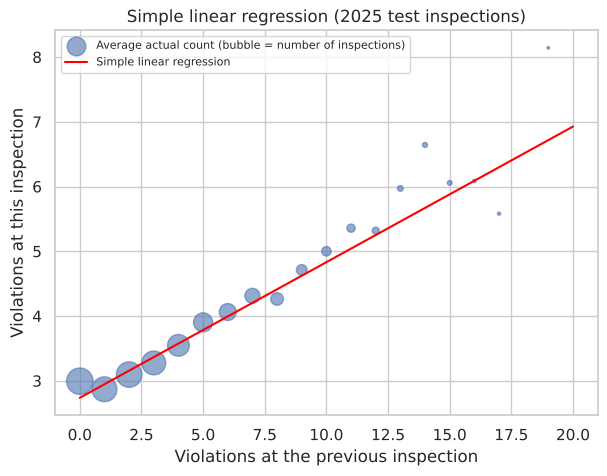

In [51]:
def make_encoder(cat, num):
    return ColumnTransformer([("cat", OneHotEncoder(drop="first", handle_unknown="infrequent_if_exist", min_frequency=100, sparse_output=False), cat), ("num", "passthrough", num)])

def metrics(name, y, pred):
    mse = mean_squared_error(y, pred)
    return {"Model": name, "Rows": len(y), "MAE": mean_absolute_error(y, pred), "MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(y, pred)}

y_tr, y_te = train["violation_count"].values, test["violation_count"].values
baseline = metrics("Baseline: predict the training mean", y_te, np.full(len(y_te), y_tr.mean()))

# ---- 1. Simple linear regression: one meaningful predictor = PriorViolationCount (only inspections that HAVE a prior inspection)
tr_p, te_p = train[train["prior_inspection_result"] != "None"], test[test["prior_inspection_result"] != "None"]
simple = LinearRegression().fit(tr_p[["prior_violation_count"]], tr_p["violation_count"])
print("Simple linear regression: ViolationCount = %.3f + %.3f x PriorViolationCount   (trained on %d inspections with a prior inspection)" % (simple.intercept_, simple.coef_[0], len(tr_p)))
base_p = metrics("Baseline (training mean), inspections with a prior", te_p["violation_count"], np.full(len(te_p), tr_p["violation_count"].mean()))
res_simple = metrics("Simple LR: PriorViolationCount", te_p["violation_count"], simple.predict(te_p[["prior_violation_count"]]))
train_simple = metrics("Simple LR (train)", tr_p["violation_count"], simple.predict(tr_p[["prior_violation_count"]]))

plt.figure(figsize=(7, 5))
g = te_p.groupby("prior_violation_count")["violation_count"].agg(["mean", "count"]); g = g[g["count"] >= 20]
plt.scatter(g.index, g["mean"], s=g["count"] / 6, alpha=0.6, label="Average actual count (bubble = number of inspections)")
xs = np.arange(0, 21); plt.plot(xs, simple.predict(pd.DataFrame({"prior_violation_count": xs})), color="red", label="Simple linear regression")
plt.xlabel("Violations at the previous inspection"); plt.ylabel("Violations at this inspection"); plt.title("Simple linear regression (2025 test inspections)"); plt.legend(fontsize=8); plt.show()

In [52]:
# ---- 2. Multiple linear regression: all predictors
enc = make_encoder(CAT, NUM)
X_tr = enc.fit_transform(train[CAT + NUM]); X_te = enc.transform(test[CAT + NUM])
names = list(enc.get_feature_names_out())
multi = LinearRegression().fit(X_tr, y_tr)
pred_tr, pred_te = multi.predict(X_tr), multi.predict(X_te)
mask_p = (test["prior_inspection_result"] != "None").values
rows = [baseline, base_p, res_simple, metrics("Multiple LR: all test inspections", y_te, pred_te),
        metrics("Multiple LR: test inspections with a prior", y_te[mask_p], pred_te[mask_p]), metrics("Multiple LR (train, 2022-2024)", y_tr, pred_tr), train_simple]
results = pd.DataFrame(rows).set_index("Model")
print("Number of encoded features in the multiple model:", X_tr.shape[1])
results.to_csv("../results/regression_metrics.csv")
results.round(3)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0, 5] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Number of encoded features in the multiple model: 102


,Rows,MAE,MSE,RMSE,R2
Model,,,,,
Baseline: predict the training mean,15919,2.713,12.286,3.505,-0.007
"Baseline (training mean), inspections with a prior",13983,2.642,11.951,3.457,-0.000
Simple LR: PriorViolationCount,13983,2.499,11.313,3.363,0.053
Multiple LR: all test inspections,15919,2.447,10.730,3.276,0.121
Multiple LR: test inspections with a prior,13983,2.407,10.415,3.227,0.128
"Multiple LR (train, 2022-2024)",45266,2.414,10.703,3.272,0.248
Simple LR (train),30436,2.611,12.458,3.530,0.054


**Inference (model results):**
- **Design:** the models were trained on 45,266 inspections from 2022-2024 and tested on the 15,919 inspections of 2025 (chronological split, no shuffling).
- **Baseline:** always predicting the training mean (3.85) gives MAE 2.713, RMSE 3.505 and R² ≈ 0 on the test year.
- **Simple linear regression:** ViolationCount = 2.737 + 0.209 x PriorViolationCount. One more violation at the previous visit adds only 0.21 violations to the expectation. On the 13,983 test inspections that have a prior inspection it reaches R² = 0.053 and MAE 2.50 (baseline 2.64), so a facility's last count is a weak but real signal.
- **Multiple linear regression** (102 encoded features): test R² = **0.121**, MAE **2.447**, RMSE **3.276**. That is about 10% lower MAE and 6.5% lower RMSE than the baseline. On inspections with a prior inspection R² is 0.128.
- **Overfitting and drift:** training R² (0.248) is twice the test R² (0.121). Two reasons are visible in the data: the model has 102 features, many of them ZIP and facility-type dummies, and 2025 differs from the training years (mean violations 3.56 against 3.85, and 87.8% of the 2025 inspections have a prior inspection against 67.2% in training, because the history only starts in 2022).
- **Limit of OLS:** it predicted a negative violation count for 304 of the 15,919 test inspections (1.9%), which is impossible for a count.

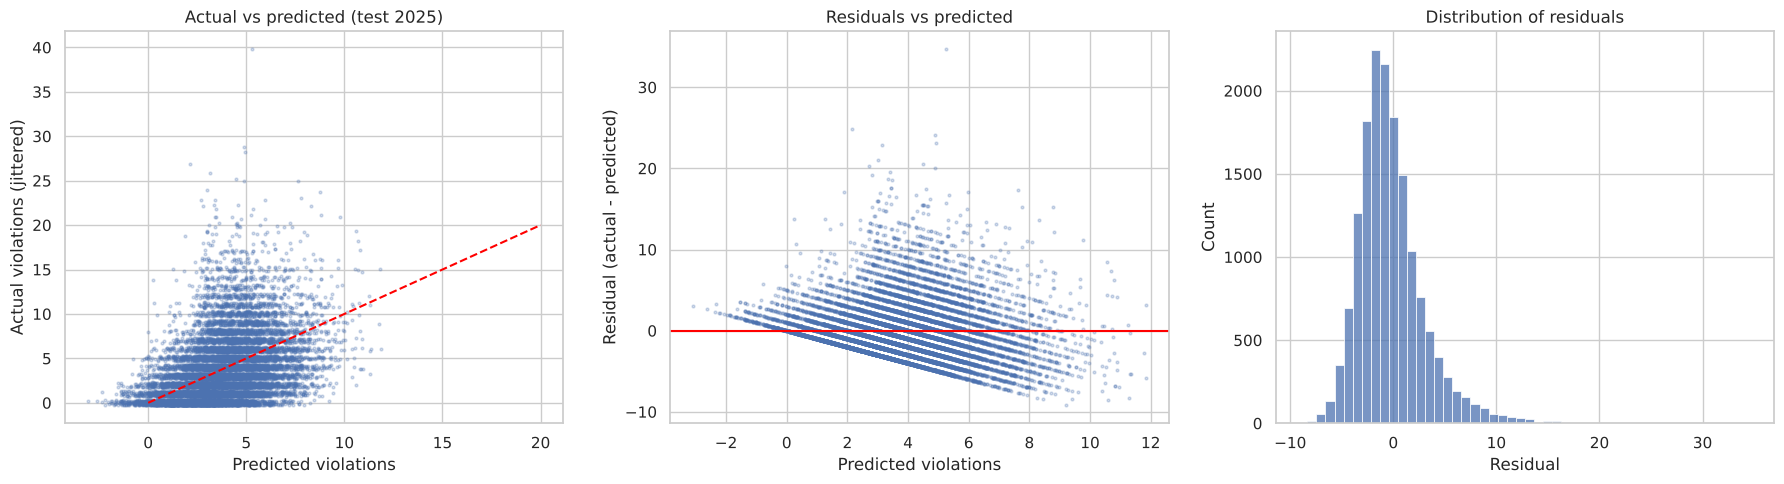

Residual mean -0.233 | std 3.267 | skewness 1.42


In [53]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
resid = y_te - pred_te
ax[0].scatter(pred_te, y_te + np.random.default_rng(0).uniform(-0.3, 0.3, len(y_te)), s=4, alpha=0.25)
ax[0].plot([0, 20], [0, 20], color="red", ls="--"); ax[0].set_xlabel("Predicted violations"); ax[0].set_ylabel("Actual violations (jittered)"); ax[0].set_title("Actual vs predicted (test 2025)")
ax[1].scatter(pred_te, resid, s=4, alpha=0.25); ax[1].axhline(0, color="red"); ax[1].set_xlabel("Predicted violations"); ax[1].set_ylabel("Residual (actual - predicted)"); ax[1].set_title("Residuals vs predicted")
sns.histplot(resid, bins=50, ax=ax[2], color="#4C72B0"); ax[2].set_title("Distribution of residuals"); ax[2].set_xlabel("Residual")
plt.tight_layout(); plt.show()
print("Residual mean %.3f | std %.3f | skewness %.2f" % (resid.mean(), resid.std(), pd.Series(resid).skew()))

Multiple linear regression: intercept = 2.302

Largest effects (change in expected violations versus the reference category):


,feature,coefficient
0,cat__zip_60617,4.597
1,cat__zip_60633,4.543
2,cat__zip_60620,4.533
3,cat__facility_type_Shared Kitchen User (Long Term),-3.910
4,cat__zip_60636,3.881
5,cat__zip_60628,3.761
6,cat__zip_infrequent_sklearn,3.505
7,cat__zip_60660,3.157
8,cat__facility_type_Golden Diner,-3.108
9,cat__zip_60651,3.090


Prior-history and risk coefficients:


,feature,coefficient
0,cat__inspection_type_License Re-Inspection,-2.370
1,cat__inspection_type_Complaint Re-Inspection,-2.356
2,cat__risk_category_Risk 3 (Low),-1.326
3,cat__risk_category_infrequent_sklearn,-1.321
4,cat__prior_inspection_result_None,1.262
5,cat__inspection_type_Complaint,1.240
6,cat__inspection_type_License,-0.863
7,cat__risk_category_Risk 2 (Medium),-0.775
8,cat__prior_inspection_result_Fail,-0.557
9,num__prior_violation_count,0.263


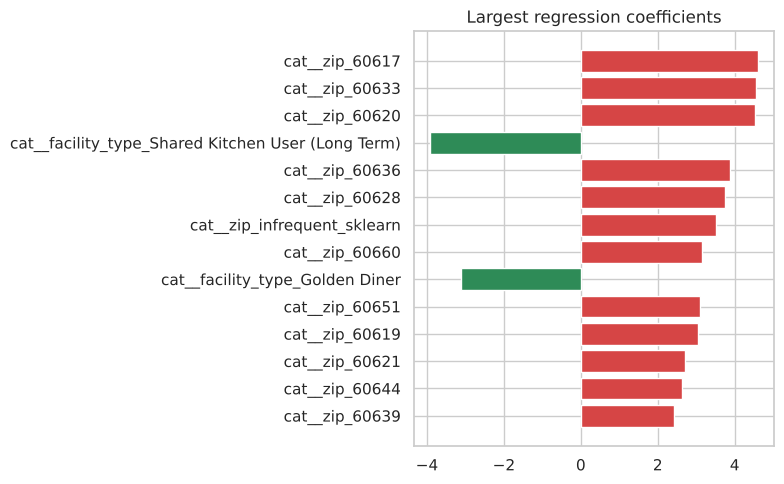

In [54]:
coef = pd.DataFrame({"feature": names, "coefficient": multi.coef_})
coef["abs"] = coef["coefficient"].abs()
coef.sort_values("abs", ascending=False).head(15)[["feature", "coefficient"]].to_csv("../results/regression_top_coefficients.csv", index=False)
print("Multiple linear regression: intercept = %.3f" % multi.intercept_)
print("\nLargest effects (change in expected violations versus the reference category):")
display(coef.sort_values("abs", ascending=False).head(14)[["feature", "coefficient"]].round(3).reset_index(drop=True))
print("Prior-history and risk coefficients:")
display(coef[coef["feature"].str.contains("prior|risk|inspection_type_Complaint|inspection_type_License")].sort_values("abs", ascending=False).head(10)[["feature", "coefficient"]].round(3).reset_index(drop=True))
fig, ax = plt.subplots(figsize=(8, 5)); top = coef.sort_values("abs", ascending=False).head(14)[::-1]
ax.barh(top["feature"], top["coefficient"], color=["#d64545" if v > 0 else "#2e8b57" for v in top["coefficient"]]); ax.set_title("Largest regression coefficients"); plt.tight_layout(); plt.show()

**Inference (regression coefficients):** the reference categories are the first level of each feature (for example Risk 1 (High), the Canvass inspection type and a prior result of Conditional Pass), so a coefficient is the change in the expected number of violations compared with that reference, with the other features fixed.
- **Location matters most.** Inspections in ZIP codes 60617, 60633 and 60620 record about 4.5 more violations than the reference ZIP, and 60636 and 60628 about 3.8. The rare-ZIP group has +3.5. A very few types go the other way: Shared Kitchen User (Long Term) -3.9 and Golden Diner -3.1.
- **Inspection type:** re-inspections have about 2.4 fewer violations (License Re-Inspection -2.37, Complaint Re-Inspection -2.36), because the problems were already found at the previous visit. Complaint inspections have 1.2 more than a routine canvass.
- **Risk:** Risk 3 (Low) facilities record 1.3 fewer violations than Risk 1 (High) ones, and Risk 2 about 0.8 fewer.
- **History:** every violation at the previous inspection adds 0.26 violations in the multiple model. A facility with no earlier inspection in the data has 1.26 more than one whose previous result was a conditional pass.
- These are associations in 2022-2024, not causes. Coefficients of rare dummies (at least 100 rows each) are less certain than those of common categories.

## 3. Regression diagnostics

In [55]:
# ---- multicollinearity (variance inflation factor) on the training design matrix
Xd = pd.DataFrame(X_tr, columns=names)
Xd = Xd.loc[:, Xd.std() > 0]
Xc = sm.add_constant(Xd, has_constant="add")
vif = pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])], index=Xd.columns).sort_values(ascending=False)
print("Highest variance inflation factors (VIF > 5 suggests collinearity; > 10 is serious):")
display(vif.head(8).round(2).to_frame("VIF"))
print("Number of features with VIF > 5: %d of %d" % ((vif > 5).sum(), len(vif)))

# ---- heteroscedasticity: Breusch-Pagan test on the training residuals
ols = sm.OLS(y_tr, Xc).fit()
lm, lm_p, fval, f_p = het_breuschpagan(ols.resid, Xc)
print("\nBreusch-Pagan test for heteroscedasticity: LM = %.1f, p-value = %.2e" % (lm, lm_p))
bins = pd.qcut(pd.Series(pred_te), 5, duplicates="drop")
spread = pd.DataFrame({"fitted_quintile": bins, "residual": resid}).groupby("fitted_quintile", observed=True)["residual"].agg(["count", "mean", "std"]).round(3)
display(spread)

Highest variance inflation factors (VIF > 5 suggests collinearity; > 10 is serious):


,VIF
cat__facility_type_Restaurant,16.59
cat__prior_inspection_result_Fail,10.32
cat__facility_type_Grocery Store,7.76
cat__inspection_type_Canvass Re-Inspection,7.72
cat__facility_type_School,6.40
cat__prior_inspection_result_None,4.13
cat__facility_type_Children's Services Facility,3.96
cat__inspection_type_Complaint Re-Inspection,3.62


Number of features with VIF > 5: 5 of 102



Breusch-Pagan test for heteroscedasticity: LM = 3502.1, p-value = 0.00e+00


,count,mean,std
fitted_quintile,,,
"(-3.094, 2.307]",3184,0.305,2.051
"(2.307, 3.298]",3184,-0.015,3.103
"(3.298, 4.171]",3183,-0.076,3.282
"(4.171, 5.243]",3184,-0.265,3.640
"(5.243, 11.844]",3184,-1.115,3.794


In [56]:
# ---- outliers: how much do extreme counts matter?
q1, q3 = np.percentile(y_tr, [25, 75]); fence = q3 + 1.5 * (q3 - q1)
ext = y_te > fence
print("Outlier fence (Q3 + 1.5 x IQR) = %.0f violations; %.1f%% of 2025 inspections are above it" % (fence, 100 * ext.mean()))
print("Test RMSE: all inspections %.3f | without the outliers %.3f" % (np.sqrt(mean_squared_error(y_te, pred_te)), np.sqrt(mean_squared_error(y_te[~ext], pred_te[~ext]))))
print("Share of the total squared error that comes from the outliers: %.1f%%" % (100 * (resid[ext] ** 2).sum() / (resid ** 2).sum()))
# sensitivity: train on a target capped at the 99th percentile
cap = np.percentile(y_tr, 99)
capped = LinearRegression().fit(X_tr, np.minimum(y_tr, cap))
print("Model trained on a capped target (cap = %.0f): test MAE %.3f, RMSE %.3f, R2 %.3f  (uncapped: MAE %.3f, RMSE %.3f, R2 %.3f)" % (
      cap, mean_absolute_error(y_te, capped.predict(X_te)), np.sqrt(mean_squared_error(y_te, capped.predict(X_te))), r2_score(y_te, capped.predict(X_te)),
      mean_absolute_error(y_te, pred_te), np.sqrt(mean_squared_error(y_te, pred_te)), r2_score(y_te, pred_te)))
print("\nNegative predictions on the test data: %d of %d" % ((pred_te < 0).sum(), len(pred_te)))

Outlier fence (Q3 + 1.5 x IQR) = 14 violations; 1.9% of 2025 inspections are above it
Test RMSE: all inspections 3.276 | without the outliers 2.865
Share of the total squared error that comes from the outliers: 24.9%
Model trained on a capped target (cap = 17): test MAE 2.432, RMSE 3.261, R2 0.128  (uncapped: MAE 2.447, RMSE 3.276, R2 0.121)

Negative predictions on the test data: 304 of 15919


**Inference (diagnostics):**
- **Multicollinearity:** only 5 of the 102 features have a VIF above 5: Restaurant (16.6), prior result Fail (10.3), Grocery Store (7.8), Canvass Re-Inspection (7.7) and School (6.4). Restaurant is 70% of all rows, so its dummy is naturally correlated with the others. No feature is perfectly collinear (the redundant `has_prior_inspection` flag was left out). Collinearity makes the individual coefficients less stable but does not hurt the predictions.
- **Heteroscedasticity:** the Breusch-Pagan test is highly significant (LM = 3,502, p < 0.001). The spread of the residuals grows with the predicted value: the standard deviation is 2.05 in the lowest fifth of the predictions and 3.79 in the highest fifth. In the highest fifth the mean residual is -1.1, so the model over-predicts the inspections it expects to be bad. The usual OLS confidence intervals would be unreliable here.
- **Residuals:** mean -0.23, standard deviation 3.27 and skewness 1.42. They are right-skewed because a few inspections have many more violations than predicted.
- **Outliers:** only 1.9% of the 2025 inspections have more than 14 violations (the training Q3 + 1.5 x IQR), but they cause 24.9% of the total squared error; RMSE falls from 3.276 to 2.865 without them. Training on a target capped at 17 violations changes the test R² only from 0.121 to 0.128, so the result is not very sensitive to the extreme counts.

## Conclusion and limitations
1. The number of violations is **hard to predict from information known before the inspection**: the best model explains about 12% of the variation in the test year (R² 0.121, MAE 2.45 against 2.71 for the baseline).
2. The signals that help are **where** the facility is (ZIP), **what kind** of inspection it is (re-inspections have far fewer violations, complaints more), the facility's **risk category** and its **previous violation count**.
3. **Data leakage was avoided:** the result, violation band and failure flag of the current inspection were not used, and the prior-history features use only earlier inspections. The split is chronological.
4. **Limitations:** OLS is not an ideal model for a count (negative predictions, non-constant variance); a Poisson or negative-binomial model would be the next step. The history is cut at January 2022, 2025 behaves differently from 2022-2024, and important causes (kitchen size, staff training, equipment) are not in the data. The model is too weak to schedule inspections on its own; it can only support screening together with other information.

# Part H. Association-rule mining: Apriori and FP-Growth

# Part H: Association-Rule Mining of Food Inspection Patterns
**Project:** Food Safety and Restaurant Inspection Analytics &nbsp;|&nbsp; **Student:** Rushikesh Maddewad &nbsp;|&nbsp; PRN 202502040037 &nbsp;|&nbsp; Roll No 353

**Problem:** which combinations of facility type, risk category, inspection type, season, area, violation band and result occur together? Each completed inspection from the analytical mart (`mart.food_inspection_analytics_mart`, built from the warehouse) becomes one transaction of categorical items.

**Algorithms:** Apriori (mandatory) and FP-Growth (recommended extension). **Metrics:** support, confidence, lift.

In [57]:
import time
import numpy as np, pandas as pd, psycopg2
import matplotlib.pyplot as plt, seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 90); pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")
conn = psycopg2.connect("host=localhost dbname=foodsafety user=foodsafety password=foodsafety")
cur = conn.cursor(); cur.execute("SELECT facility_type, risk_group, inspection_type_group, result_group, violation_band, area, season, inspection_date FROM mart.food_inspection_analytics_mart")
mart = pd.DataFrame(cur.fetchall(), columns=[c.name for c in cur.description])
print("Mart rows (completed inspections):", f"{len(mart):,}")

Mart rows (completed inspections): 61,737


## 1. Building the transactions
The items follow the project document: **FacilityType, RiskCategory, InspectionTypeGroup, ResultGroup, ViolationBand, AreaGroup and Season**.

**Discretisation of the continuous variable (ViolationCount):** the bands come from the distribution of the count (Q1 = 1, median = 3, Q3 = 5): *None (0)*, *Low (1-2)*, *Medium (3-5)*, *High (6-9)*, *Very High (10+)*. **Season** comes from the calendar month (Dec-Feb Winter, Mar-May Spring, Jun-Aug Summer, Sep-Nov Autumn).

Other choices: the 8 most frequent facility types are kept and the rest become *Other* (about 200 raw spellings would give itemsets with no support). The 552 inspections whose violation count is unknown (Fail or conditional pass without text) are left out, because the item *ViolationBand* would be meaningless for them.

In [58]:
data = mart[mart["violation_band"] != "Unknown"].copy()
top_types = data["facility_type"].value_counts().index[:8]
data["facility_type"] = data["facility_type"].where(data["facility_type"].isin(top_types), "Other")
print("Transactions used:", f"{len(data):,}", "| top facility types kept:", list(top_types))

item_cols = {"facility_type": "FacilityType", "risk_group": "Risk", "inspection_type_group": "InspType", "result_group": "Result", "violation_band": "Violations", "area": "Area", "season": "Season"}
onehot = pd.concat([pd.get_dummies(data[c], prefix=name, prefix_sep="=").astype(bool) for c, name in item_cols.items()], axis=1)
print("Items:", onehot.shape[1], "| average items per transaction:", onehot.sum(axis=1).mean())
onehot.iloc[:5, :6]

Transactions used: 61,185 | top facility types kept: ['Restaurant', 'Grocery Store', 'School', "Children's Services Facility", 'Daycare Above And Under 2 Years', 'Bakery', 'Long Term Care', 'Daycare (2 - 6 Years)']
Items: 35 | average items per transaction: 7.0


,FacilityType=Bakery,FacilityType=Children's Services Facility,FacilityType=Daycare (2 - 6 Years),FacilityType=Daycare Above And Under 2 Years,FacilityType=Grocery Store,FacilityType=Long Term Care
0,False,False,False,False,True,False
1,False,False,False,False,True,False
2,False,False,False,False,True,False
3,False,False,False,False,True,False
4,False,False,False,False,True,False


Most frequent items (support):
Risk=High                     0.816
FacilityType=Restaurant       0.694
Result=Pass                   0.617
Area=Northwest                0.527
InspType=Routine (Canvass)    0.504
Violations=Medium (3-5)       0.298
Area=Southwest                0.293
Violations=Low (1-2)          0.280
Season=Spring                 0.270
Season=Autumn                 0.260
Season=Summer                 0.246
InspType=Re-inspection        0.236


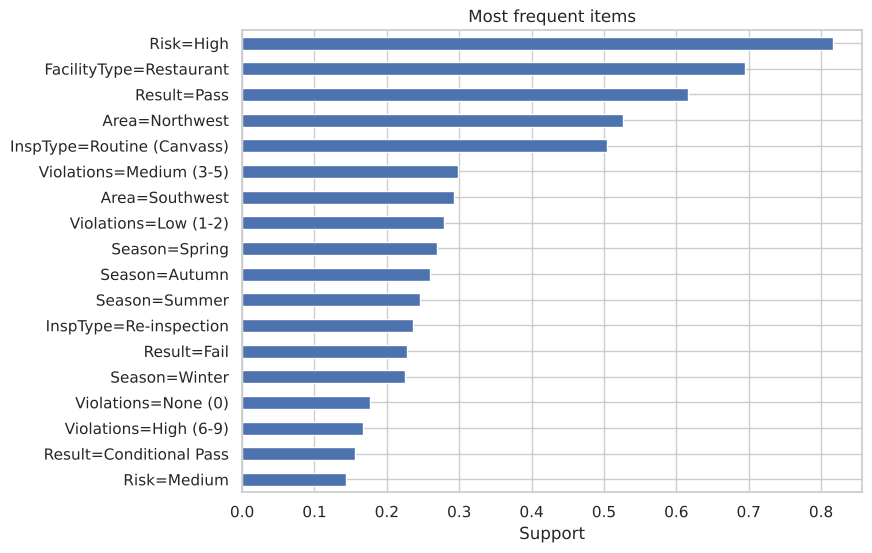

In [59]:
freq = onehot.mean().sort_values(ascending=False)
print("Most frequent items (support):"); print(freq.head(12).round(3).to_string())
plt.figure(figsize=(8, 6)); freq.head(18)[::-1].plot(kind="barh", color="#4C72B0"); plt.title("Most frequent items"); plt.xlabel("Support"); plt.show()

**Inference:** there are **61,185 transactions** and 35 items; every transaction has exactly 7 items (one per attribute). The most frequent items are *Risk=High* (81.6%), *Restaurant* (69.4%), *Result=Pass* (61.7%), *Area=Northwest* (52.7%) and *Routine (Canvass)* (50.4%). Among the violation bands, *Medium (3-5)* is 29.8% and *Low (1-2)* 28.0%. A frequent item on its own is not a finding; a rule is interesting only when its lift is clearly above 1.

## 2. Apriori (mandatory)
Minimum support **0.02** (an itemset must appear in at least 2% of the 61,185 inspections, i.e. about 1,200 inspections), so that no rule rests on a handful of cases. Minimum confidence **0.30**: single outcomes such as *Fail* are only 23% of all inspections, so a rule with 33% confidence and lift 1.5 is already informative.

In [60]:
MIN_SUP, MIN_CONF = 0.02, 0.30
t0 = time.time(); ap = apriori(onehot, min_support=MIN_SUP, use_colnames=True); t_ap = time.time() - t0
ap["size"] = ap["itemsets"].map(len)
print("Apriori: %d frequent itemsets in %.2f s" % (len(ap), t_ap)); print(ap["size"].value_counts().sort_index().to_string())
rules = association_rules(ap, metric="confidence", min_threshold=MIN_CONF)
rules["antecedent_text"] = rules["antecedents"].map(lambda s: " & ".join(sorted(s))); rules["consequent_text"] = rules["consequents"].map(lambda s: " & ".join(sorted(s)))
print("\nRules with confidence >= %.2f: %d  (with lift > 1.2: %d)" % (MIN_CONF, len(rules), (rules["lift"] > 1.2).sum()))

Apriori: 1198 frequent itemsets in 0.28 s
size
1     28
2    223
3    441
4    372
5    126
6      8

Rules with confidence >= 0.30: 3949  (with lift > 1.2: 982)


## 3. FP-Growth (recommended extension) and comparison

In [61]:
t0 = time.time(); fp = fpgrowth(onehot, min_support=MIN_SUP, use_colnames=True); t_fp = time.time() - t0
same = {s: round(v, 10) for s, v in zip(ap["itemsets"], ap["support"])} == {s: round(v, 10) for s, v in zip(fp["itemsets"], fp["support"])}
print("FP-Growth: %d frequent itemsets in %.2f s | identical to Apriori: %s" % (len(fp), t_fp, same))
rows = []
for ms in [0.10, 0.05, 0.03, 0.02, 0.01]:
    t0 = time.time(); a = apriori(onehot, min_support=ms, use_colnames=True); ta = time.time() - t0
    t0 = time.time(); f = fpgrowth(onehot, min_support=ms, use_colnames=True); tf = time.time() - t0
    rows.append({"min_support": ms, "itemsets": len(a), "Apriori (s)": round(ta, 2), "FP-Growth (s)": round(tf, 2)})
pd.DataFrame(rows)

FP-Growth: 1198 frequent itemsets in 0.38 s | identical to Apriori: True


,min_support,itemsets,Apriori (s),FP-Growth (s)
0,0.10,153,0.03,0.29
1,0.05,396,0.08,0.31
2,0.03,761,0.16,0.32
3,0.02,1198,0.24,0.63
4,0.01,2333,0.54,0.37


**Inference:** Apriori and FP-Growth find exactly the **same 1,198 frequent itemsets** at minimum support 0.02 (28 single items, 223 pairs, 441 triples, 372 itemsets of four, 126 of five and 8 of six), so the choice of algorithm does not change the result. In the speed comparison In the speed comparison Apriori is clearly faster at high support (for example at 0.10) because the FP-tree has a start-up cost, the two are about equal near 0.05, and FP-Growth is roughly two to three times faster when the support is low (at 0.01, with 2,333 itemsets). The Apriori rules at confidence 0.30 are 3,949, of which 982 have a lift above 1.2; most of these are redundant or definitional, which is why the selection step is needed.

## 4. Rule evaluation and selection of meaningful rules
* **Support** = share of all inspections that contain the whole rule; **confidence** = P(consequent | antecedent); **lift** = confidence / support(consequent) (above 1 means the items occur together more than by chance).
* A rule is kept as *meaningful* when **support >= 0.02** (so a high lift cannot come from a tiny group), **confidence >= 0.30** and **lift >= 1.30**.
* Only rules with one item on the right-hand side are listed.
* Two kinds of rules are removed: (1) *definitional* rules, `Violations=None (0) => Result=Pass`, which are true by construction (only a *Pass* can have a recorded count of 0, see the curation notebook); (2) *redundant* rules, where a simpler rule (a subset of the antecedent) for the same consequent already has the same confidence (within 0.02).
* For every consequent the strongest remaining rules are shown, so the list is not ten versions of the same rule.

In [62]:
cand = rules[(rules["support"] >= 0.02) & (rules["confidence"] >= MIN_CONF) & (rules["lift"] >= 1.3) & (rules["consequents"].map(len) == 1)].copy()
cand["consequent_item"] = cand["consequents"].map(lambda s: list(s)[0])
n0 = len(cand)
cand = cand[~(cand["antecedent_text"].str.contains("Violations=None") & (cand["consequent_item"] == "Result=Pass"))]       # definitional
cand = cand.reset_index(drop=True)
redundant = []
for i, x in cand.iterrows():
    simpler = cand[(cand["consequent_item"] == x["consequent_item"]) & cand["antecedents"].map(lambda a: a < x["antecedents"])]
    redundant.append(bool((simpler["confidence"] >= x["confidence"] - 0.02).any()))
cand = cand[~np.array(redundant)].sort_values(["lift", "confidence"], ascending=False)
print("Rules before filtering: %d | after removing definitional and redundant rules: %d" % (n0, len(cand)))

chosen = []                                   # up to 2 non-overlapping rules per consequent
for item, g in cand.groupby("consequent_item"):
    taken = []
    for _, x in g.iterrows():
        if all(not (x["antecedents"] <= t or t <= x["antecedents"]) for t in taken):
            taken.append(x["antecedents"]); chosen.append(x)
        if len(taken) == 2:
            break
best = pd.DataFrame(chosen).sort_values("lift", ascending=False)
show = best.head(14)[["antecedent_text", "consequent_text", "support", "confidence", "lift"]].reset_index(drop=True)
show.round(3)

Rules before filtering: 275 | after removing definitional and redundant rules: 41


,antecedent_text,consequent_text,support,confidence,lift
0,Risk=Low,FacilityType=Grocery Store,0.025,0.618,6.516
1,Violations=Very High (10+),Result=Fail,0.054,0.688,3.019
2,FacilityType=Restaurant & InspType=License & Result=Pass,Violations=None (0),0.022,0.492,2.779
3,Area=Northwest & InspType=License & Result=Pass,Violations=None (0),0.021,0.479,2.707
4,FacilityType=Restaurant & Risk=High & Violations=None (0),InspType=Re-inspection,0.043,0.495,2.095
5,Area=Southwest & Violations=None (0),InspType=Re-inspection,0.020,0.447,1.892
6,Result=Fail,Violations=High (6-9),0.071,0.313,1.879
7,Violations=High (6-9),Result=Fail,0.071,0.428,1.879
8,FacilityType=Restaurant & Result=Conditional Pass & Risk=High,Violations=High (6-9),0.031,0.307,1.841
9,FacilityType=School & Result=Pass,Violations=Low (1-2),0.021,0.452,1.616


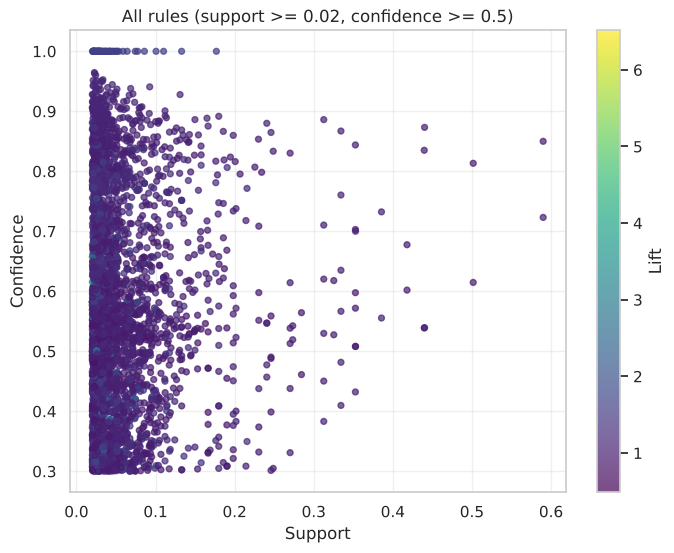

In [63]:
plt.figure(figsize=(8, 6))
sc = plt.scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="viridis", s=18, alpha=0.7)
plt.colorbar(sc, label="Lift"); plt.xlabel("Support"); plt.ylabel("Confidence"); plt.title("All rules (support >= 0.02, confidence >= 0.5)"); plt.grid(alpha=0.3); plt.show()

## 5. The ten (or more) meaningful rules with interpretation

In [64]:
INTERPRETATION = {'Risk=Low  =>  FacilityType=Grocery Store': '61.8% of the low-risk inspections are of grocery stores, 6.5 times more than their share in the whole data. The low-risk category is mostly grocery stores. Use: plan the low-risk inspection routes around grocery stores.', 'Violations=Very High (10+)  =>  Result=Fail': '69% of the inspections with 10 or more violations end in a fail (3.0 times the normal 23%). Use: treat 10+ violations as a trigger for an early re-inspection. The other 31% still passed or passed with conditions, so the count alone does not decide the result.', 'FacilityType=Restaurant & InspType=License & Result=Pass  =>  Violations=None (0)': 'Almost half (49%) of the restaurants that pass a licence inspection have no violation at all (lift 2.8). A licence inspection is usually either clean or a fail, with few small findings. Use: a fast-track for licence checks of businesses that were already prepared.', 'Area=Northwest & InspType=License & Result=Pass  =>  Violations=None (0)': 'The same pattern in the Northwest: 48% of passed licence inspections are clean (lift 2.7).', 'FacilityType=Restaurant & Risk=High & Violations=None (0)  =>  InspType=Re-inspection': 'Half (49.5%) of the clean inspections of high-risk restaurants are re-inspections (lift 2.1). Use: this shows that follow-up visits do work, because the problems found earlier have been fixed.', 'Area=Southwest & Violations=None (0)  =>  InspType=Re-inspection': 'In the Southwest 44.7% of the clean inspections are re-inspections (lift 1.9), the same follow-up effect as in the rule above.', 'Result=Fail  =>  Violations=High (6-9)': '31% of the failed inspections are in the High band (6-9 violations), 1.9 times more than in all inspections; support 7.1% is large enough to be reliable.', 'Violations=High (6-9)  =>  Result=Fail': '43% of the inspections with 6-9 violations fail. Together with the 69% for 10+ violations this shows that the chance of failing rises step by step with the violation band.', 'FacilityType=Restaurant & Result=Conditional Pass & Risk=High  =>  Violations=High (6-9)': '31% of the conditional passes of high-risk restaurants have 6-9 violations (lift 1.8). Use: a follow-up list of restaurants that pass with conditions and have 6 or more violations.', 'FacilityType=School & Result=Pass  =>  Violations=Low (1-2)': 'A school that passes usually has 1-2 minor violations (45%, lift 1.6), and a clean pass is less common. Use: school checklists can focus on minor housekeeping items.', 'FacilityType=School  =>  InspType=Routine (Canvass)': '73% of the school inspections are routine canvass inspections (lift 1.4). Schools are inspected on a regular schedule rather than because of complaints.', 'InspType=Routine (Canvass) & Result=Pass  =>  Violations=Low (1-2)': 'The rule with the highest support (11.4%): 40% of the routine inspections that pass cite 1-2 violations. This is the typical pass.', 'FacilityType=School  =>  Area=Southwest': '42% of the school inspections are in the Southwest quadrant (lift 1.4). Use: school inspection capacity should be planned for the Southwest. The areas are street-grid quadrants, not official community areas.', 'Result=Conditional Pass  =>  Violations=Medium (3-5)': '41% of the conditional passes have 3-5 violations (lift 1.4); this is the typical conditional pass.'}
final = show.copy()
final["Rule"] = final["antecedent_text"] + "  =>  " + final["consequent_text"]
final["Interpretation / possible use"] = final["Rule"].map(INTERPRETATION).fillna("")
final[["Rule", "support", "confidence", "lift", "Interpretation / possible use"]].to_csv("../results/association_rules_selected.csv", index=False)
final[["Rule", "support", "confidence", "lift", "Interpretation / possible use"]].rename(columns={"support": "Support", "confidence": "Confidence", "lift": "Lift"}).round(3)

,Rule,Support,Confidence,Lift,Interpretation / possible use
0,Risk=Low => FacilityType=Grocery Store,0.025,0.618,6.516,"61.8% of the low-risk inspections are of grocery stores, 6.5 times more than their sha..."
1,Violations=Very High (10+) => Result=Fail,0.054,0.688,3.019,69% of the inspections with 10 or more violations end in a fail (3.0 times the normal ...
2,FacilityType=Restaurant & InspType=License & Result=Pass => Violations=None (0),0.022,0.492,2.779,Almost half (49%) of the restaurants that pass a licence inspection have no violation ...
3,Area=Northwest & InspType=License & Result=Pass => Violations=None (0),0.021,0.479,2.707,The same pattern in the Northwest: 48% of passed licence inspections are clean (lift 2...
4,FacilityType=Restaurant & Risk=High & Violations=None (0) => InspType=Re-inspection,0.043,0.495,2.095,Half (49.5%) of the clean inspections of high-risk restaurants are re-inspections (lif...
5,Area=Southwest & Violations=None (0) => InspType=Re-inspection,0.020,0.447,1.892,"In the Southwest 44.7% of the clean inspections are re-inspections (lift 1.9), the sam..."
6,Result=Fail => Violations=High (6-9),0.071,0.313,1.879,"31% of the failed inspections are in the High band (6-9 violations), 1.9 times more th..."
7,Violations=High (6-9) => Result=Fail,0.071,0.428,1.879,43% of the inspections with 6-9 violations fail. Together with the 69% for 10+ violati...
8,FacilityType=Restaurant & Result=Conditional Pass & Risk=High => Violations=High (6-9),0.031,0.307,1.841,31% of the conditional passes of high-risk restaurants have 6-9 violations (lift 1.8)....
9,FacilityType=School & Result=Pass => Violations=Low (1-2),0.021,0.452,1.616,"A school that passes usually has 1-2 minor violations (45%, lift 1.6), and a clean pas..."


**Inference (what the rules say):**
- The selection started with 275 rules (support >= 0.02, confidence >= 0.30, lift >= 1.3). After removing definitional and redundant rules 41 remained, and the table shows the 14 strongest, at most two per consequent. All of them have a support of at least 2.0%, so none rests on a tiny group.
- **Severity:** the chance of failing rises with the violation band: 43% for 6-9 violations and 69% for 10 or more. Failed inspections are mostly in these bands.
- **Follow-up and licence visits are clean visits:** re-inspections (up to 50% of the clean high-risk restaurant visits) and passed licence inspections (about 48% with no violation) are where zero violations are most common. This supports the idea that businesses fix their problems after a failed visit.
- **Schools:** they are inspected on a routine schedule (73%), usually pass with 1-2 minor violations and are concentrated in the Southwest.
- **Low risk means grocery stores** (62%, lift 6.5).
- None of the selected rules contains the season, so no strong seasonal association was found at this threshold, which agrees with the weak seasonal pattern in the EDA.
- Rules show co-occurrence, not cause and effect, and *lift* is only reported for rules with enough support.

## Conclusion
1. Each completed inspection was turned into 7 categorical items (facility type, risk, inspection type group, result, violation band, area, season) and mined with **Apriori** and **FP-Growth** (identical results: 1,198 itemsets at support 0.02).
2. **14 meaningful rules** (support >= 2%, confidence >= 30%, lift >= 1.3, definitional and redundant rules removed) are listed with their interpretation and a possible use.
3. The clearest operational messages are that **10 or more violations means a 69% chance of a fail**, that **follow-up and licence inspections are mostly clean**, and that low-risk inspections are mostly grocery stores.
4. Limitations: the discretisation (violation bands, 8 facility types, quadrants as areas) changes the rules; rules show association and not cause; the 552 inspections with an unknown violation count are excluded; and each inspection is treated as independent although the same facility appears several times.

# Part I. Decision tree: predicting a failed inspection

# Part I: Decision-Tree Prediction of a Failed Inspection
**Project:** Food Safety and Restaurant Inspection Analytics &nbsp;|&nbsp; **Student:** Rushikesh Maddewad &nbsp;|&nbsp; PRN 202502040037 &nbsp;|&nbsp; Roll No 353

**Problem:** predict whether an inspection **will fail** from what is known *before* the inspector arrives.
**Target:** `FailedInspection = 1` when the published result is *Fail*; 0 for *Pass* and *Pass w/ Conditions* (the comparison outcomes). **Model:** scikit-learn `DecisionTreeClassifier`.

**Data lineage:** Raw data > profiling > curation > staging > warehouse > analytical mart `mart.food_inspection_analytics_mart` > this notebook.

In [65]:
import numpy as np, pandas as pd, psycopg2
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix, precision_recall_curve

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")
conn = psycopg2.connect("host=localhost dbname=foodsafety user=foodsafety password=foodsafety")
cur = conn.cursor(); cur.execute("SELECT * FROM mart.food_inspection_analytics_mart")
mart = pd.DataFrame(cur.fetchall(), columns=[c.name for c in cur.description])
print("Mart rows (completed inspections):", f"{len(mart):,}")

Mart rows (completed inspections): 61,737


## 1. Predictors and leakage control
* **Predictors known before the inspection:** FacilityType, RiskCategory, InspectionType, Month, DayOfWeek, Area (area group and ZIP) and **prior inspection history** (result of the previous inspection, its violation count, the days since it and the number of earlier inspections of the facility).
* **Not used (known only after the outcome):** the current inspection's violation count, violation band, high-violation flag and result. The violations decide the result, so using them would make the task trivial and the model useless in advance.
* The prior-history features come only from a **strictly earlier** inspection of the same licensed facility. History starts in January 2022; when there is no earlier inspection the prior result is `None`.

In [66]:
df = mart.copy()
df["inspection_date"] = pd.to_datetime(df["inspection_date"])
df["month"] = df["month"].astype(str)
for c in ["prior_violation_count", "days_since_prior_inspection"]:
    df[c] = pd.to_numeric(df[c]).fillna(-1)            # -1 = no earlier inspection (the tree can split on it)
df["prior_inspection_count"] = pd.to_numeric(df["prior_inspection_count"])
CAT = ["facility_type", "risk_category", "inspection_type", "month", "day_of_week", "area", "zip", "prior_inspection_result"]
NUM = ["prior_violation_count", "days_since_prior_inspection", "prior_inspection_count"]
y = df["is_failed_inspection"].astype(int)

# chronological split: train 2022-2023 | validation 2024 (model selection) | test 2025 (final, untouched until the end)
train, val, test = [df[m] for m in [df["inspection_date"] < "2024-01-01", (df["inspection_date"] >= "2024-01-01") & (df["inspection_date"] < "2025-01-01"), df["inspection_date"] >= "2025-01-01"]]
for name, d in [("train 2022-2023", train), ("validation 2024", val), ("test 2025", test)]:
    print(f"{name:16s} {len(d):6,d} inspections | fail rate {100 * d['is_failed_inspection'].mean():.2f}%")
print("Baseline accuracy on the test year (always predict 'not failed'): %.4f" % (1 - test["is_failed_inspection"].mean()))

train 2022-2023  29,693 inspections | fail rate 24.88%
validation 2024  15,992 inspections | fail rate 21.77%
test 2025        16,052 inspections | fail rate 21.13%
Baseline accuracy on the test year (always predict 'not failed'): 0.7887


## 2. Encoding and the model-selection plan
Categorical predictors are one-hot encoded (categories with fewer than 200 training rows are grouped as *infrequent*). The tree is tuned on the **2024 validation year**, never on the test year. The selection criterion is **ROC-AUC**, because only 21-25% of the inspections fail and accuracy would reward always predicting "pass".

Investigated settings: **max_depth**, **min_samples_split**, **min_samples_leaf** and **cost-complexity pruning (ccp_alpha)**.

Encoded features: 104


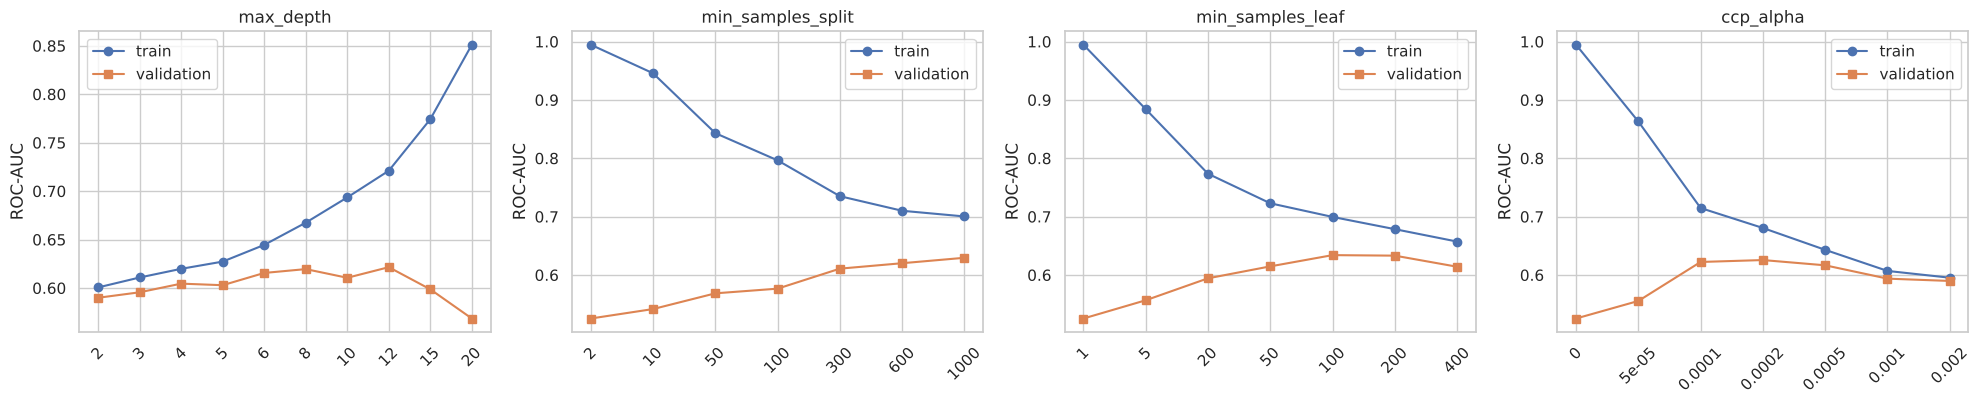

,max_depth,train AUC,validation AUC,leaves
0,2,0.6006,0.5899,4
1,3,0.6108,0.5956,8
2,4,0.6198,0.6045,16
3,5,0.6273,0.6029,32
4,6,0.6445,0.6155,60
5,8,0.6674,0.6195,150
6,10,0.6935,0.6106,313
7,12,0.7210,0.6215,546
8,15,0.7742,0.5986,1124
9,20,0.8511,0.5685,2354


In [67]:
enc = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=200, sparse_output=False), CAT), ("num", "passthrough", NUM)])
Xtr = enc.fit_transform(train[CAT + NUM]); Xva = enc.transform(val[CAT + NUM]); Xte = enc.transform(test[CAT + NUM])
names = [n.replace("cat__", "").replace("num__", "") for n in enc.get_feature_names_out()]
ytr, yva, yte = train["is_failed_inspection"].values, val["is_failed_inspection"].values, test["is_failed_inspection"].values
print("Encoded features:", Xtr.shape[1])

def fit_eval(**params):
    m = DecisionTreeClassifier(random_state=42, **params).fit(Xtr, ytr)
    return m, roc_auc_score(ytr, m.predict_proba(Xtr)[:, 1]), roc_auc_score(yva, m.predict_proba(Xva)[:, 1])

# one factor at a time, the other settings at their defaults
fig, ax = plt.subplots(1, 4, figsize=(20, 4.2))
sweeps = [("max_depth", [2, 3, 4, 5, 6, 8, 10, 12, 15, 20], {}), ("min_samples_split", [2, 10, 50, 100, 300, 600, 1000], {}),
          ("min_samples_leaf", [1, 5, 20, 50, 100, 200, 400], {}), ("ccp_alpha", [0, 0.00005, 0.0001, 0.0002, 0.0005, 0.001, 0.002], {})]
sweep_tables = {}
for a, (param, values, extra) in zip(ax, sweeps):
    rows = []
    for v in values:
        m, auc_tr, auc_va = fit_eval(**{param: v}); rows.append({param: v, "train AUC": auc_tr, "validation AUC": auc_va, "leaves": m.get_n_leaves()})
    t = pd.DataFrame(rows); sweep_tables[param] = t.copy()
    if param == "ccp_alpha":
        sweep_tables[param][param] = sweep_tables[param][param].map(lambda v: f"{v:g}")
    xs = range(len(values))
    a.plot(xs, t["train AUC"], marker="o", label="train"); a.plot(xs, t["validation AUC"], marker="s", label="validation")
    a.set_xticks(list(xs)); a.set_xticklabels([str(v) for v in values], rotation=45); a.set_title(param); a.set_ylabel("ROC-AUC"); a.legend()
plt.tight_layout(); plt.show()
sweep_tables["max_depth"].round(4)

In [68]:
print("min_samples_leaf (one factor):"); display(sweep_tables["min_samples_leaf"].round(4))
print("ccp_alpha (one factor):"); display(sweep_tables["ccp_alpha"].round(4))

min_samples_leaf (one factor):


,min_samples_leaf,train AUC,validation AUC,leaves
0,1,0.9946,0.5254,8057
1,5,0.8842,0.5566,3482
2,20,0.7735,0.5943,1022
3,50,0.7229,0.6147,398
4,100,0.6995,0.6340,206
5,200,0.6785,0.6331,99
6,400,0.6572,0.6141,52


ccp_alpha (one factor):


,ccp_alpha,train AUC,validation AUC,leaves
0,0,0.9946,0.5254,8057
1,5e-05,0.8630,0.5555,1770
2,0.0001,0.7147,0.6223,179
3,0.0002,0.6805,0.6256,53
4,0.0005,0.6431,0.6166,16
5,0.001,0.6069,0.5937,5
6,0.002,0.5953,0.5898,3


**Inference (investigating the tree settings, ROC-AUC on the 2024 validation year):**
- **max_depth:** the training AUC keeps rising (0.60 at depth 2 to 0.85 at depth 20) but the validation AUC peaks around depth 8-12 (0.62) and then falls to 0.57 at depth 20. Deep trees memorise the training years.
- **min_samples_leaf:** with 1 sample per leaf the tree has 8,057 leaves, a training AUC of 0.995 and a validation AUC of only 0.525 (almost random). The validation AUC is best at 100-200 samples per leaf (0.634 and 0.633).
- **min_samples_split:** a larger value acts like pruning: the validation AUC grows from about 0.53 (split 2) to about 0.63 (split 1000).
- **ccp_alpha (pruning):** a small penalty helps (0.6256 at 0.0002, 53 leaves); a large one underfits (0.5898 at 0.002, only 3 leaves).
- All four controls tell the same story: **an unrestricted tree over-fits badly and a well-restricted one generalises better, but the best validation AUC is only about 0.63.**

In [69]:
# grid search over the four settings together (ROC-AUC on the 2024 validation year)
import itertools, time
grid = list(itertools.product([3, 4, 5, 6, 8, 10, 12], [2, 50, 200], [1, 20, 50, 100, 200], [0, 0.0005, 0.001, 0.002]))
t0 = time.time(); rows = []
for depth, mss, msl, alpha in grid:
    m, auc_tr, auc_va = fit_eval(max_depth=depth, min_samples_split=mss, min_samples_leaf=msl, ccp_alpha=alpha)
    rows.append({"max_depth": depth, "min_samples_split": mss, "min_samples_leaf": msl, "ccp_alpha": alpha, "train AUC": auc_tr, "validation AUC": auc_va, "leaves": m.get_n_leaves()})
search = pd.DataFrame(rows).sort_values("validation AUC", ascending=False).reset_index(drop=True)
print(f"{len(grid)} combinations tried in {time.time() - t0:.0f} s")
display(search.head(8).round(4))
best = search.iloc[0]
BEST = dict(max_depth=int(best["max_depth"]), min_samples_split=int(best["min_samples_split"]), min_samples_leaf=int(best["min_samples_leaf"]), ccp_alpha=float(best["ccp_alpha"]))
print("Selected settings:", BEST)

420 combinations tried in 55 s


,max_depth,min_samples_split,min_samples_leaf,ccp_alpha,train AUC,validation AUC,leaves
0,8,200,200,0.0,0.6534,0.6357,37
1,8,2,200,0.0,0.6534,0.6357,37
2,8,50,200,0.0,0.6534,0.6357,37
3,12,200,20,0.0,0.6835,0.6357,107
4,12,2,100,0.0,0.6795,0.6355,112
5,12,200,100,0.0,0.6795,0.6355,112
6,12,50,100,0.0,0.6795,0.6355,112
7,12,2,200,0.0,0.6706,0.6351,69


Selected settings: {'max_depth': 8, 'min_samples_split': 200, 'min_samples_leaf': 200, 'ccp_alpha': 0.0}


**Inference:** 420 combinations were tried in about a minute. The best validation AUC is **0.6357**, and several combinations are practically tied (0.6351-0.6357), so there is a plateau and the choice is not sensitive. The simplest of the best settings was selected: **max_depth 8, min_samples_split 200, min_samples_leaf 200, no extra pruning**.

## 3. Final model: refit on 2022-2024, evaluate once on the 2025 test year

In [70]:
Xfit = np.vstack([Xtr, Xva]); yfit = np.concatenate([ytr, yva])
tree = DecisionTreeClassifier(random_state=42, **BEST).fit(Xfit, yfit)
proba = tree.predict_proba(Xte)[:, 1]

# threshold: the default 0.5 is shown, plus the threshold that maximises F1 on the VALIDATION year (model fitted on train only)
sel = DecisionTreeClassifier(random_state=42, **BEST).fit(Xtr, ytr)
p_va = sel.predict_proba(Xva)[:, 1]; prec, rec, thr = precision_recall_curve(yva, p_va)
f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-9, None); thr_best = float(thr[np.argmax(f1s)])

def report(name, p, t):
    pred = (p >= t).astype(int); tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
    return {"Model": name, "threshold": round(t, 3), "Accuracy": accuracy_score(yte, pred), "Precision": precision_score(yte, pred, zero_division=0), "Recall": recall_score(yte, pred),
            "F1": f1_score(yte, pred), "ROC-AUC": roc_auc_score(yte, p), "TN": tn, "FP": fp, "FN": fn, "TP": tp}
base = {"Model": "Baseline: always 'not failed'", "threshold": "-", "Accuracy": 1 - yte.mean(), "Precision": 0.0, "Recall": 0.0, "F1": 0.0, "ROC-AUC": 0.5, "TN": int((yte == 0).sum()), "FP": 0, "FN": int(yte.sum()), "TP": 0}
final = pd.DataFrame([base, report("Decision tree, threshold 0.5", proba, 0.5), report("Decision tree, validation-optimal threshold", proba, thr_best)])
print("Tree: %d leaves, depth %d" % (tree.get_n_leaves(), tree.get_depth()))
final.to_csv("../results/decision_tree_metrics.csv", index=False)
final.round(4)

Tree: 54 leaves, depth 8


,Model,threshold,Accuracy,Precision,Recall,F1,ROC-AUC,TN,FP,FN,TP
0,Baseline: always 'not failed',-,0.7887,0.0000,0.0000,0.0000,0.5000,12661,0,3391,0
1,"Decision tree, threshold 0.5",0.5,0.7836,0.3797,0.0386,0.0701,0.6354,12447,214,3260,131
2,"Decision tree, validation-optimal threshold",0.217,0.6005,0.2891,0.6107,0.3924,0.6354,7568,5093,1320,2071


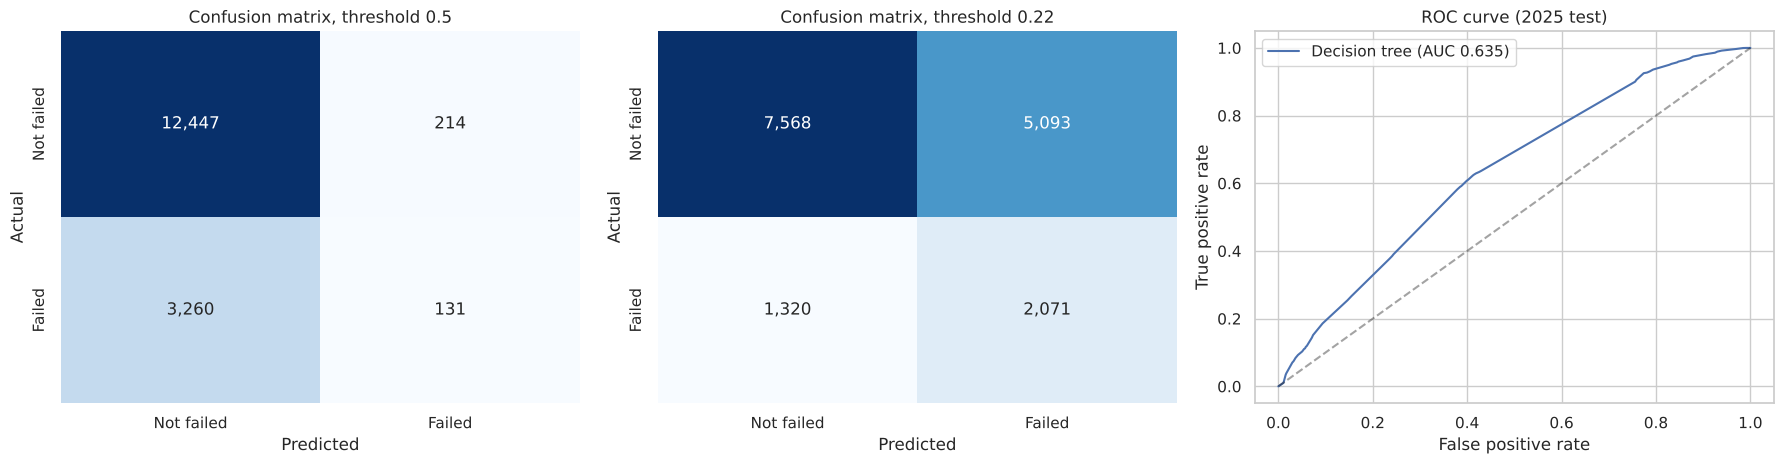

In [71]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
for a, (t, title) in zip(ax[:2], [(0.5, "threshold 0.5"), (thr_best, f"threshold {thr_best:.2f}")]):
    cm = confusion_matrix(yte, (proba >= t).astype(int)); sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=a, xticklabels=["Not failed", "Failed"], yticklabels=["Not failed", "Failed"])
    a.set_title(f"Confusion matrix, {title}"); a.set_xlabel("Predicted"); a.set_ylabel("Actual")
fpr, tpr, _ = roc_curve(yte, proba); ax[2].plot(fpr, tpr, label=f"Decision tree (AUC {roc_auc_score(yte, proba):.3f})"); ax[2].plot([0, 1], [0, 1], "k--", alpha=0.4)
ax[2].set_xlabel("False positive rate"); ax[2].set_ylabel("True positive rate"); ax[2].set_title("ROC curve (2025 test)"); ax[2].legend()
plt.tight_layout(); plt.show()

Feature importance (top 12):


,importance
prior_inspection_result_Fail,0.2940
inspection_type_Complaint,0.1470
prior_violation_count,0.1282
days_since_prior_inspection,0.0999
zip_60617,0.0520
inspection_type_Canvass Re-Inspection,0.0461
facility_type_School,0.0425
prior_inspection_result_Pass,0.0398
area_Southwest,0.0232
zip_60625,0.0226


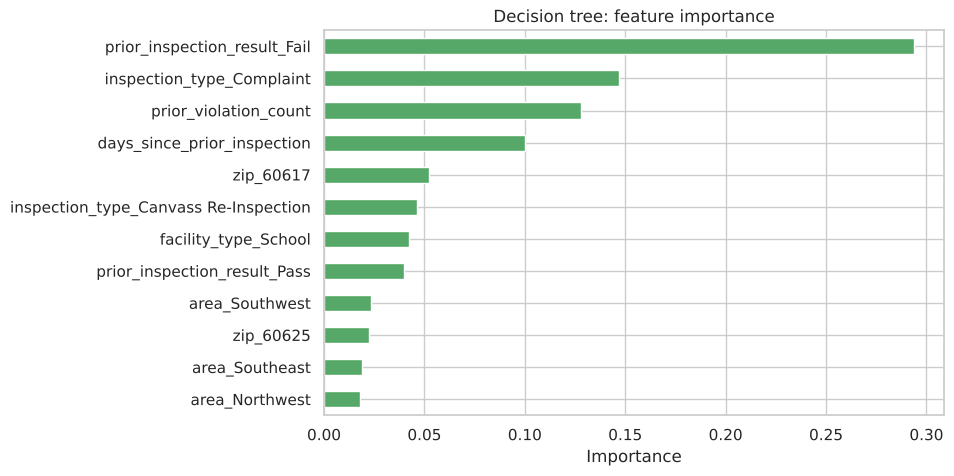

In [72]:
imp = pd.Series(tree.feature_importances_, index=names).sort_values(ascending=False)
imp.head(12).to_csv("../results/decision_tree_importance.csv", header=["importance"])
print("Feature importance (top 12):"); display(imp.head(12).round(4).to_frame("importance"))
plt.figure(figsize=(8, 5)); imp.head(12)[::-1].plot(kind="barh", color="#55A868"); plt.title("Decision tree: feature importance"); plt.xlabel("Importance"); plt.show()

**Inference (test year 2025, the model was fitted on 2022-2024):**
- **Baseline:** always predicting "not failed" is 78.9% accurate. The tree (54 leaves, depth 8) has a test **ROC-AUC of 0.635**, clearly above random (0.5) but far from a good classifier.
- **At the default threshold 0.5** the tree almost never predicts a fail: recall 3.9%, precision 38.0%, F1 0.07, and its accuracy (78.4%) is even slightly below the baseline. Accuracy is therefore a misleading measure here.
- **At the threshold that maximised F1 on the validation year (0.217)** it finds **61% of the failed inspections** (2,071 of 3,391) but with a precision of only 28.9%; it raises 5,093 false alarms and the accuracy drops to 60.1%. A health department could use this as a ranking, not as a decision.
- **Feature importance:** the most important predictors are the **result of the previous inspection** (Fail: 29%), a **complaint inspection** (15%), the **previous violation count** (13%) and the **days since the previous inspection** (10%). Then come ZIP 60617 (5%), canvass re-inspection (5%) and schools (4%). History and inspection type matter far more than the month or the weekday, which do not appear among the top features.

## 4. The trained tree and three actual decision paths

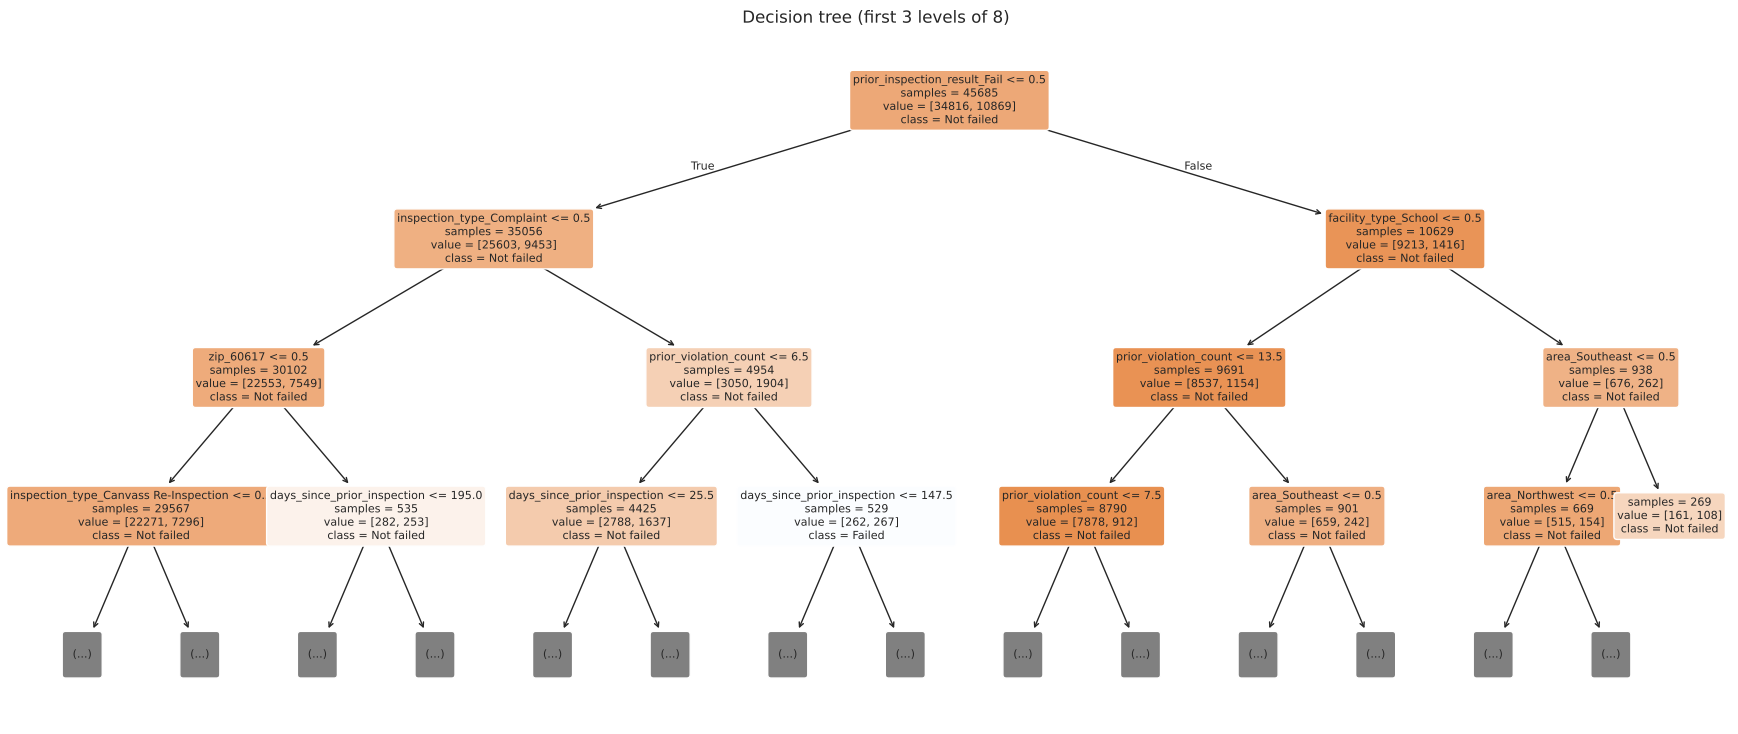

In [73]:
plt.figure(figsize=(22, 9))
plot_tree(tree, max_depth=3, feature_names=names, class_names=["Not failed", "Failed"], filled=True, rounded=True, fontsize=8, impurity=False, proportion=False)
plt.title("Decision tree (first 3 levels of %d)" % tree.get_depth()); plt.show()

In [74]:
# Decision paths: describe the leaves with the clearest signal (train+validation rows) and check them on the 2025 test year
leaf_fit, leaf_te = tree.apply(Xfit), tree.apply(Xte)
t_ = tree.tree_
def path_text(leaf):
    node_path = tree.decision_path(Xfit[leaf_fit == leaf][:1]).indices
    conds = []
    for a, b in zip(node_path[:-1], node_path[1:]):
        f = names[t_.feature[a]]; thr = t_.threshold[a]
        conds.append(f"{f} <= {thr:.1f}" if t_.children_left[a] == b else f"{f} > {thr:.1f}")
    return conds
leaves = pd.DataFrame({"leaf": np.unique(leaf_fit)})
leaves["n_fit"] = leaves["leaf"].map(pd.Series(leaf_fit).value_counts()); leaves["fail_rate_fit"] = leaves["leaf"].map(pd.Series(yfit).groupby(leaf_fit).mean())
leaves["n_test"] = leaves["leaf"].map(pd.Series(leaf_te).value_counts()).fillna(0).astype(int)
leaves["fail_rate_test"] = leaves["leaf"].map(pd.Series(yte).groupby(leaf_te).mean())
big = leaves[(leaves["n_fit"] >= 300) & (leaves["n_test"] >= 100)]
picks = {"HIGHEST fail rate": big.sort_values("fail_rate_fit", ascending=False).iloc[0], "LOWEST fail rate": big.sort_values("fail_rate_fit").iloc[0], "LARGEST group": big.sort_values("n_fit", ascending=False).iloc[0]}
paths = []
for label, r in picks.items():
    print(f"=== Path: {label} (leaf {int(r.leaf)})"); 
    for c in path_text(int(r.leaf)): print("   IF", c)
    print(f"   -> train+validation: {int(r.n_fit):,} inspections, {100 * r.fail_rate_fit:.1f}% failed | test 2025: {int(r.n_test):,} inspections, {100 * r.fail_rate_test:.1f}% failed\n")
    paths.append({"path": label, "conditions": " AND ".join(path_text(int(r.leaf))), "n (2022-24)": int(r.n_fit), "fail % (2022-24)": round(100 * r.fail_rate_fit, 1), "n (2025)": int(r.n_test), "fail % (2025)": round(100 * r.fail_rate_test, 1)})
pd.DataFrame(paths).to_csv("../results/decision_tree_paths.csv", index=False)
pd.DataFrame(paths)

=== Path: HIGHEST fail rate (leaf 61)
   IF prior_inspection_result_Fail <= 0.5
   IF inspection_type_Complaint > 0.5
   IF prior_violation_count > 6.5
   IF days_since_prior_inspection > 147.5
   -> train+validation: 327 inspections, 54.7% failed | test 2025: 140 inspections, 57.9% failed

=== Path: LOWEST fail rate (leaf 74)
   IF prior_inspection_result_Fail > 0.5
   IF facility_type_School <= 0.5
   IF prior_violation_count <= 13.5
   IF prior_violation_count <= 7.5
   IF days_since_prior_inspection <= 36.5
   IF area_Northwest > 0.5
   IF prior_violation_count <= 4.5
   IF prior_inspection_count <= 3.5
   -> train+validation: 1,398 inspections, 3.7% failed | test 2025: 208 inspections, 4.8% failed

=== Path: LARGEST group (leaf 8)
   IF prior_inspection_result_Fail <= 0.5
   IF inspection_type_Complaint <= 0.5
   IF zip_60617 <= 0.5
   IF inspection_type_Canvass Re-Inspection <= 0.5
   IF prior_inspection_result_Pass <= 0.5
   IF area_Southwest <= 0.5
   IF zip_60666 <= 0.5
   IF 

,path,conditions,n (2022-24),fail % (2022-24),n (2025),fail % (2025)
0,HIGHEST fail rate,prior_inspection_result_Fail <= 0.5 AND inspection_type_Complaint > 0.5 AND prior_violation_count > 6.5 AND days_sin...,327,54.7,140,57.9
1,LOWEST fail rate,prior_inspection_result_Fail > 0.5 AND facility_type_School <= 0.5 AND prior_violation_count <= 13.5 AND prior_viola...,1398,3.7,208,4.8
2,LARGEST group,prior_inspection_result_Fail <= 0.5 AND inspection_type_Complaint <= 0.5 AND zip_60617 <= 0.5 AND inspection_type_Ca...,10757,26.9,2360,27.5


**Inference (three actual decision paths, checked on the 2025 test year):**
1. **Highest fail rate (55-58%):** *the previous result was not a fail* AND *the inspection is a complaint inspection* AND *the previous inspection had more than 6 violations* AND *more than 147 days have passed since it*. A complaint visit to a facility that had many violations and has not been seen for 5 months fails 54.7% of the time in 2022-2024 (327 inspections) and 57.9% in 2025 (140 inspections), against 21% overall.
2. **Lowest fail rate (4-5%):** *the previous inspection was a fail* AND *not a school* AND *few violations then (at most 4)* AND *within 37 days* AND *Northwest area* AND *at most 3 earlier inspections*. This is a quick follow-up visit after a failed inspection: only 3.7% fail in 2022-2024 (1,398 inspections) and 4.8% in 2025 (208 inspections), so follow-up visits work.
3. **Largest group (27%):** *no previous fail* AND *not a complaint* AND *not ZIP 60617* AND *not a canvass re-inspection* AND *the previous result was not a pass* (so a conditional pass or no earlier inspection) AND *not in the Southwest or Northeast and not ZIP 60666*. These 10,757 inspections fail 26.9% of the time and 27.5% (2,360 inspections) in 2025, a little above the overall rate, so this group is not well separated.
The rates on the 2025 test inspections are close to those in the training years for all three paths, so the rules are stable over time even though the model as a whole is weak.

## Conclusion and limitations
1. A `DecisionTreeClassifier` was built on **information known before the inspection** and tuned on a separate validation year. Restricting the tree (depth, minimum leaf size, minimum split size, pruning) was essential: the unrestricted tree has a validation AUC of 0.53, the selected one 0.636.
2. On the 2025 test year the tree reaches an **ROC-AUC of 0.635**. At threshold 0.5 it is no better than always predicting "not failed" (78.4% against 78.9%); at the lower threshold 0.217 it finds 61% of the failures with 29% precision. Failure is **only weakly predictable in advance**.
3. What the tree learned is sensible: a **previous fail followed by a quick re-inspection rarely fails again**, **complaint inspections after a long gap and many earlier violations fail often**, and the facility's recent history is the strongest signal.
4. **Leakage was avoided:** no information from the current inspection (violations, band, result) is used and the history features use only earlier inspections.
5. Limitations: the history starts in 2022; the fail rate changed over time (24.9% in 2022 to 21.1% in 2025); the same facility appears in several rows; and what happens inside the facility on the day (the real cause of a fail) is not in the data. The tree should be used to **rank** inspections for attention, together with inspector judgement, not to decide them.

In [75]:
os.chdir(WORK)

# Part D. Distributed data warehouse (Citus): code and recorded results
**Not executed in Colab.** It needs a 3-node Citus 13.2 cluster on the PostgreSQL community (PGDG) build of PostgreSQL 16. The cells below only save the code; the measured results from my machine follow.

Design: coordinator + 2 workers on one machine, 32 shards, the fact table distributed by `FacilityKey`, the five dimensions as reference tables.

**`scripts/setup_citus_cluster.sh`**: creates the coordinator and two workers and registers the workers.

In [76]:
%%writefile Project/scripts/setup_citus_cluster.sh
#!/usr/bin/env bash
# Builds a 3-node Citus cluster on one machine: coordinator (port 5440) and two workers (5441, 5442).
# Requires the PGDG build of PostgreSQL 16 and the package postgresql-16-citus-13.2 (see docs/distributed_warehouse.md).
set -euo pipefail
for spec in "coord 5440" "worker1 5441" "worker2 5442"; do
  set -- $spec; name=$1; port=$2
  if ! pg_lsclusters -h | awk '{print $2}' | grep -qx "$name"; then
    pg_createcluster 16 "$name" -p "$port" -- --auth-local=trust --auth-host=trust >/dev/null
    cat >> "/etc/postgresql/16/$name/postgresql.conf" <<CONF
shared_preload_libraries = 'citus'
listen_addresses = 'localhost'
shared_buffers = 256MB
max_connections = 200
citus.shard_count = 32
CONF
  fi
  pg_ctlcluster 16 "$name" start 2>/dev/null || true
done
sleep 4
for port in 5440 5441 5442; do
  su postgres -c "psql -p $port -tAc \"SELECT 1 FROM pg_database WHERE datname='foodsafety_citus'\"" | grep -q 1 || su postgres -c "psql -p $port -c 'CREATE DATABASE foodsafety_citus'"
  su postgres -c "psql -p $port -d foodsafety_citus -c 'CREATE EXTENSION IF NOT EXISTS citus'" >/dev/null
done
su postgres -c "psql -p 5440 -d foodsafety_citus -c \"SELECT citus_set_coordinator_host('localhost', 5440)\"" >/dev/null
for port in 5441 5442; do
  su postgres -c "psql -p 5440 -d foodsafety_citus -tAc \"SELECT count(*) FROM pg_dist_node WHERE nodeport=$port\"" | grep -q '^1$' || \
    su postgres -c "psql -p 5440 -d foodsafety_citus -c \"SELECT citus_add_node('localhost', $port)\""
done
su postgres -c "psql -p 5440 -d foodsafety_citus -c \"SELECT nodeid, nodename, nodeport, noderole, isactive FROM pg_dist_node ORDER BY nodeid\""


Writing Project/scripts/setup_citus_cluster.sh


**`etl/distributed_baseline.py`**: distribution-key analysis (shard skew by simulating Citus' hash) and the centralized scaling baseline.

In [77]:
%%writefile Project/etl/distributed_baseline.py
"""Part D, step 1 (runs on plain PostgreSQL): distribution-key analysis and the CENTRALIZED side of the scaling experiment.

Volumes above the real size (61,737 completed inspections) are produced by SYNTHETIC SCALE-UP: bootstrap resampling of the real fact rows
(same facility / date / location mix, new surrogate ids). They measure query performance only; they are not new inspections and are never used for analysis.
"""
import statistics, time
from pathlib import Path
import pandas as pd
import psycopg2

ROOT = Path(__file__).resolve().parents[1]
DSN = "host=localhost dbname=foodsafety user=foodsafety password=foodsafety"
VOLUMES = [61737, 100_000, 500_000, 1_000_000, 2_000_000]
conn = psycopg2.connect(DSN); conn.autocommit = True; cur = conn.cursor()

# ------------------------------------------------------------------ 1. distribution-key candidates (shard simulation with PostgreSQL's hashint4, the hash Citus uses for integer keys)
rows = []
for key in ["facility_key", "location_key", "date_key"]:
    cur.execute(f"SELECT count(DISTINCT {key}), max(c)::float / sum(c) FROM (SELECT {key}, count(*) c FROM dw.fact_inspection GROUP BY 1) t")
    distinct, top_share = cur.fetchone()
    cur.execute(f"""SELECT count(*), avg(n), stddev_pop(n), max(n), min(n) FROM (
                      SELECT ((hashint4({key})::bigint + 2147483648) * 32 / 4294967296)::int AS shard, count(*) AS n FROM dw.fact_inspection GROUP BY 1) s""")
    shards, mean, std, mx, mn = cur.fetchone()
    cur.execute(f"""SELECT count(*), avg(n), stddev_pop(n), max(n) FROM (
                      SELECT ((hashint4({key})::bigint + 2147483648) * 2 / 4294967296)::int AS worker, count(*) AS n FROM dw.fact_inspection GROUP BY 1) s""")
    w, wmean, wstd, wmax = cur.fetchone()
    rows.append({"candidate_key": key, "distinct_values": distinct, "largest_single_value_share_%": round(100 * top_share, 2), "non_empty_shards_of_32": shards,
                 "rows_per_shard_mean": round(float(mean)), "rows_per_shard_max": mx, "shard_skew_max_over_mean": round(float(mx) / float(mean), 2),
                 "shard_cv": round(float(std) / float(mean), 3), "worker_split_max_over_mean_(2_workers)": round(float(wmax) / float(wmean), 3)})
pd.DataFrame(rows).to_csv(ROOT / "results" / "distribution_key_analysis.csv", index=False)
print(pd.DataFrame(rows).to_string(index=False))

# ------------------------------------------------------------------ 2. synthetic scale-up tables
cur.execute("DROP SCHEMA IF EXISTS bench CASCADE; CREATE SCHEMA bench;")
cur.execute("""CREATE TABLE bench.src AS SELECT row_number() OVER (ORDER BY inspection_key)::int AS rn, date_key, facility_key, inspection_type_key, result_key, location_key,
                      violation_count, fail_count, pass_count, conditional_pass_count, high_violation_flag FROM dw.fact_inspection""")
cur.execute("SELECT count(*) FROM bench.src"); n_src = cur.fetchone()[0]
cur.execute(f"""CREATE TABLE bench.fact_max AS
                SELECT g AS inspection_key, s.date_key, s.facility_key, s.inspection_type_key, s.result_key, s.location_key, s.violation_count, s.fail_count, s.pass_count, s.conditional_pass_count, s.high_violation_flag
                  FROM (SELECT g, 1 + floor(random() * {n_src})::int AS rn FROM generate_series(1, {max(VOLUMES)}) g) x JOIN bench.src s ON s.rn = x.rn""")
QUERIES = {
 "Q1 results by facility type": "SELECT fa.facility_type, r.result_group, count(*) FROM {f} f JOIN dw.dim_facility fa USING (facility_key) JOIN dw.dim_result r USING (result_key) GROUP BY 1, 2",
 "Q2 failure rate by area": "SELECT l.geographic_area_group, 100.0 * sum(f.fail_count) / count(*) FROM {f} f JOIN dw.dim_location l USING (location_key) GROUP BY 1",
 "Q3 monthly inspections": "SELECT d.year, d.month, count(*) FROM {f} f JOIN dw.dim_date d USING (date_key) GROUP BY 1, 2",
 "Q4 violations by risk": "SELECT fa.risk_group, sum(f.violation_count), avg(f.violation_count) FROM {f} f JOIN dw.dim_facility fa USING (facility_key) GROUP BY 1",
 "Q5 facility x year aggregation": "SELECT f.facility_key, d.year, count(*), sum(f.fail_count) FROM {f} f JOIN dw.dim_date d USING (date_key) GROUP BY 1, 2",
}
out = []
for n in VOLUMES:
    table = f"bench.fact_{n}"
    if n == n_src:
        cur.execute(f"CREATE TABLE {table} AS SELECT inspection_key::bigint, date_key, facility_key, inspection_type_key, result_key, location_key, violation_count, fail_count, pass_count, conditional_pass_count, high_violation_flag FROM dw.fact_inspection")
    else:
        cur.execute(f"CREATE TABLE {table} AS SELECT * FROM bench.fact_max WHERE inspection_key <= {n}")
    for c in ["date_key", "facility_key", "location_key", "result_key"]:
        cur.execute(f"CREATE INDEX ON {table} ({c})")
    cur.execute(f"ANALYZE {table}")
    for name, sql in QUERIES.items():
        q = sql.format(f=table)
        cur.execute(q); cur.fetchall()                            # warm-up
        ts = []
        for _ in range(5):
            t0 = time.perf_counter(); cur.execute(q); cur.fetchall(); ts.append((time.perf_counter() - t0) * 1000)
        out.append({"query": name, "rows": n, "centralized_ms": round(statistics.median(ts), 1)})
        print(f"{name:34s} {n:>9,d} rows  {statistics.median(ts):9.1f} ms")
    cur.execute(f"SELECT pg_total_relation_size('{table}')"); print(f"   {table}: {cur.fetchone()[0] / 1e6:.0f} MB with indexes")
pd.DataFrame(out).to_csv(ROOT / "results" / "centralized_scaling.csv", index=False)
cur.execute("DROP TABLE bench.fact_max; DROP TABLE bench.src")


Writing Project/etl/distributed_baseline.py


**`etl/distributed_citus.py`**: loads the Citus cluster and times the same five queries at 61,737 to 2,000,000 rows; checks that results are identical.

In [78]:
%%writefile Project/etl/distributed_citus.py
"""Part D, step 2: the DISTRIBUTED side of the scaling experiment on a 3-node Citus cluster (coordinator + 2 workers on one machine),
compared with the centralized PostgreSQL node measured in the same session.

Facts are distributed by FacilityKey (the key chosen in docs/distributed_warehouse.md); the five small dimensions are Citus REFERENCE tables
(a full copy on every node), so every join is local. Volumes above 61,737 rows are the synthetic scale-up tables made by etl/distributed_baseline.py.
"""
import io, statistics, tempfile, time, subprocess
from decimal import Decimal
from pathlib import Path
import pandas as pd
import psycopg2

ROOT = Path(__file__).resolve().parents[1]
MAIN = "host=localhost port=5432 dbname=foodsafety user=foodsafety password=foodsafety"
CITUS = "host=localhost port=5440 dbname=foodsafety_citus user=postgres"
VOLUMES = [61737, 100_000, 500_000, 1_000_000, 2_000_000]
KEY_TEST_VOLUME = 1_000_000
FACT_COLS = "inspection_key bigint, date_key int, facility_key int, inspection_type_key int, result_key int, location_key int, violation_count smallint, fail_count smallint, pass_count smallint, conditional_pass_count smallint, high_violation_flag smallint"
QUERIES = {
 "Q1 results by facility type": "SELECT fa.facility_type, r.result_group, count(*) FROM {f} f JOIN dw.dim_facility fa USING (facility_key) JOIN dw.dim_result r USING (result_key) GROUP BY 1, 2",
 "Q2 failure rate by area": "SELECT l.geographic_area_group, 100.0 * sum(f.fail_count) / count(*) FROM {f} f JOIN dw.dim_location l USING (location_key) GROUP BY 1",
 "Q3 monthly inspections": "SELECT d.year, d.month, count(*) FROM {f} f JOIN dw.dim_date d USING (date_key) GROUP BY 1, 2",
 "Q4 violations by risk": "SELECT fa.risk_group, sum(f.violation_count), avg(f.violation_count) FROM {f} f JOIN dw.dim_facility fa USING (facility_key) GROUP BY 1",
 "Q5 facility x year aggregation": "SELECT f.facility_key, d.year, count(*), sum(f.fail_count) FROM {f} f JOIN dw.dim_date d USING (date_key) GROUP BY 1, 2",
}
main = psycopg2.connect(MAIN); main.autocommit = True; mc = main.cursor()
cit = psycopg2.connect(CITUS); cit.autocommit = True; cc = cit.cursor()


def bench(cur, sql, runs=5):
    cur.execute(sql); res = cur.fetchall()                      # warm-up (also returns the result for the correctness check)
    ts = []
    for _ in range(runs):
        t0 = time.perf_counter(); cur.execute(sql); cur.fetchall(); ts.append((time.perf_counter() - t0) * 1000)
    return round(statistics.median(ts), 1), res


def norm(rows):
    return sorted(tuple(round(float(v), 4) if isinstance(v, (Decimal, float)) else v for v in r) for r in rows)


def copy_table(src_cur, query, dst_cur, target):
    with tempfile.TemporaryFile() as f:
        buf = io.TextIOWrapper(f, encoding="utf-8")
        src_cur.copy_expert(f"COPY ({query}) TO STDOUT WITH CSV", buf); buf.flush(); f.seek(0)
        dst_cur.copy_expert(f"COPY {target} FROM STDIN WITH CSV", io.TextIOWrapper(f, encoding="utf-8"))


# ------------------------------------------------------------------ cluster set-up: reference tables for the dimensions
cc.execute("DROP SCHEMA IF EXISTS bench CASCADE; DROP SCHEMA IF EXISTS dw CASCADE; CREATE SCHEMA dw; CREATE SCHEMA bench;")
cc.execute("""CREATE TABLE dw.dim_date (date_key int PRIMARY KEY, year smallint, month smallint);
              CREATE TABLE dw.dim_facility (facility_key int PRIMARY KEY, facility_type text, facility_group text, risk_group text);
              CREATE TABLE dw.dim_result (result_key int PRIMARY KEY, result_group text);
              CREATE TABLE dw.dim_location (location_key int PRIMARY KEY, geographic_area_group text);""")
for t in ["dim_date", "dim_facility", "dim_result", "dim_location"]:
    cc.execute(f"SELECT create_reference_table('dw.{t}')")
copy_table(mc, "SELECT date_key, year, month FROM dw.dim_date", cc, "dw.dim_date")
copy_table(mc, "SELECT facility_key, facility_type, facility_group, risk_group FROM dw.dim_facility", cc, "dw.dim_facility")
copy_table(mc, "SELECT result_key, result_group FROM dw.dim_result", cc, "dw.dim_result")
copy_table(mc, "SELECT location_key, geographic_area_group FROM dw.dim_location", cc, "dw.dim_location")
print("reference tables loaded")


def make_distributed(n, key):
    name = f"bench.fact_{n}_{key}"
    cc.execute(f"CREATE TABLE {name} ({FACT_COLS})")
    cc.execute(f"SELECT create_distributed_table('{name}', '{key}')")
    t0 = time.perf_counter()
    copy_table(mc, f"SELECT inspection_key, date_key, facility_key, inspection_type_key, result_key, location_key, violation_count, fail_count, pass_count, conditional_pass_count, high_violation_flag FROM bench.fact_{n}", cc, name)
    for c in ["date_key", "facility_key", "location_key", "result_key"]:
        cc.execute(f"CREATE INDEX ON {name} ({c})")
    cc.execute(f"ANALYZE {name}")
    return name, round(time.perf_counter() - t0, 1)


rows, load_rows = [], []
for n in VOLUMES:
    name, load_s = make_distributed(n, "facility_key"); load_rows.append({"rows": n, "distribution_key": "facility_key", "load_and_index_s": load_s})
    for qname, sql in QUERIES.items():
        c_ms, c_res = bench(mc, sql.format(f=f"bench.fact_{n}"))
        d_ms, d_res = bench(cc, sql.format(f=name))
        rows.append({"query": qname, "rows": n, "centralized_ms": c_ms, "distributed_ms": d_ms, "distributed_over_centralized": round(d_ms / c_ms, 2), "results_identical": norm(c_res) == norm(d_res)})
        print(f"{qname:34s} {n:>9,d}  central {c_ms:8.1f} ms  citus {d_ms:8.1f} ms  identical={rows[-1]['results_identical']}", flush=True)
scal = pd.DataFrame(rows)
scal.to_csv(ROOT / "results" / "distributed_scaling.csv", index=False)
scal[["query", "rows", "centralized_ms"]].to_csv(ROOT / "results" / "centralized_scaling.csv", index=False)     # re-measured in this session
pd.DataFrame(load_rows).to_csv(ROOT / "results" / "citus_load_times.csv", index=False)

# ------------------------------------------------------------------ which distribution key? same queries at 1,000,000 rows for each candidate
key_rows = []
for key in ["facility_key", "location_key", "date_key"]:
    name = f"bench.fact_{KEY_TEST_VOLUME}_{key}"
    if key != "facility_key":
        name, _ = make_distributed(KEY_TEST_VOLUME, key)
    for qname, sql in QUERIES.items():
        d_ms, _ = bench(cc, sql.format(f=name)); key_rows.append({"query": qname, "distribution_key": key, "distributed_ms": d_ms})
    cc.execute(f"""SELECT s.nodeport, count(*), sum(s.shard_size), max(s.shard_size), min(s.shard_size) FROM citus_shards s WHERE s.table_name = '{name}'::regclass GROUP BY 1 ORDER BY 1""")
    for port, shards, tot, mx, mn in cc.fetchall():
        key_rows.append({"query": "SHARD SIZES", "distribution_key": key, "distributed_ms": None, "worker_port": port, "shards": shards, "bytes_total": int(tot), "bytes_largest_shard": int(mx), "bytes_smallest_shard": int(mn)})
    cc.execute(f"SELECT max(shard_size)::float / avg(shard_size) FROM citus_shards WHERE table_name = '{name}'::regclass")
    key_rows.append({"query": "SHARD SKEW max/mean", "distribution_key": key, "distributed_ms": float(cc.fetchone()[0])})
pd.DataFrame(key_rows).to_csv(ROOT / "results" / "distribution_key_experiment.csv", index=False)

# ------------------------------------------------------------------ how the queries are executed (parallel plans) and resources
with open(ROOT / "results" / "citus_explain.txt", "w") as f:
    for qname in ["Q1 results by facility type", "Q5 facility x year aggregation"]:
        cc.execute("EXPLAIN (COSTS OFF) " + QUERIES[qname].format(f=f"bench.fact_{KEY_TEST_VOLUME}_facility_key"))
        f.write(f"--- {qname} (distributed by facility_key, {KEY_TEST_VOLUME:,} rows)\n" + "\n".join(r[0] for r in cc.fetchall()) + "\n\n")
ps = subprocess.run("ps -eo rss,args", shell=True, capture_output=True, text=True).stdout.splitlines()
res = {name: round(sum(int(l.split(None, 1)[0]) for l in ps if f"16/{name}" in l) / 1024) for name in ["main", "coord", "worker1", "worker2"]}
pd.DataFrame([{"cluster": k, "resident_memory_MB": v} for k, v in res.items()]).to_csv(ROOT / "results" / "citus_resources.csv", index=False)
print("resident memory (MB):", res)
print(scal.to_string(index=False))


Writing Project/etl/distributed_citus.py


In [79]:
import io, pandas as pd
# recorded measurement from the author's machine (results/distribution_key_experiment.csv)
print("Distribution-key experiment (which key gives the most even shards)")
pd.read_csv(io.StringIO("""query,distribution_key,distributed_ms,worker_port,shards,bytes_total,bytes_largest_shard,bytes_smallest_shard
Q1 results by facility type,facility_key,223.2,,,,,
Q2 failure rate by area,facility_key,148.1,,,,,
Q3 monthly inspections,facility_key,132.3,,,,,
Q4 violations by risk,facility_key,197.6,,,,,
Q5 facility x year aggregation,facility_key,212.8,,,,,
SHARD SIZES,facility_key,,5441.0,16.0,54181888.0,3768320.0,3072000.0
SHARD SIZES,facility_key,,5442.0,16.0,50864128.0,3694592.0,2965504.0
SHARD SKEW max/mean,facility_key,1.1479373001637683,,,,,
Q1 results by facility type,location_key,225.7,,,,,
Q2 failure rate by area,location_key,144.0,,,,,
Q3 monthly inspections,location_key,106.7,,,,,
Q4 violations by risk,location_key,216.6,,,,,
Q5 facility x year aggregation,location_key,255.3,,,,,
SHARD SIZES,location_key,,5441.0,16.0,57384960.0,8167424.0,950272.0
SHARD SIZES,location_key,,5442.0,16.0,50044928.0,6799360.0,155648.0
SHARD SKEW max/mean,location_key,2.432819887143511,,,,,
Q1 results by facility type,date_key,247.9,,,,,
Q2 failure rate by area,date_key,151.0,,,,,
Q3 monthly inspections,date_key,133.5,,,,,
Q4 violations by risk,date_key,174.3,,,,,
Q5 facility x year aggregation,date_key,255.8,,,,,
SHARD SIZES,date_key,,5441.0,16.0,52420608.0,4136960.0,2514944.0
SHARD SIZES,date_key,,5442.0,16.0,49815552.0,3891200.0,2588672.0
SHARD SKEW max/mean,date_key,1.294871794871795,,,,,
"""))

Distribution-key experiment (which key gives the most even shards)


,query,distribution_key,distributed_ms,worker_port,shards,bytes_total,bytes_largest_shard,bytes_smallest_shard
0,Q1 results by facility type,facility_key,223.200000,NaN,NaN,NaN,NaN,NaN
1,Q2 failure rate by area,facility_key,148.100000,NaN,NaN,NaN,NaN,NaN
2,Q3 monthly inspections,facility_key,132.300000,NaN,NaN,NaN,NaN,NaN
3,Q4 violations by risk,facility_key,197.600000,NaN,NaN,NaN,NaN,NaN
4,Q5 facility x year aggregation,facility_key,212.800000,NaN,NaN,NaN,NaN,NaN
5,SHARD SIZES,facility_key,NaN,5441.0,16.0,54181888.0,3768320.0,3072000.0
6,SHARD SIZES,facility_key,NaN,5442.0,16.0,50864128.0,3694592.0,2965504.0
7,SHARD SKEW max/mean,facility_key,1.147937,NaN,NaN,NaN,NaN,NaN
8,Q1 results by facility type,location_key,225.700000,NaN,NaN,NaN,NaN,NaN
9,Q2 failure rate by area,location_key,144.000000,NaN,NaN,NaN,NaN,NaN


In [80]:
import io, pandas as pd
# recorded measurement from the author's machine (results/distributed_scaling.csv)
print("Citus vs centralized timings (ms) over the data volumes")
pd.read_csv(io.StringIO("""query,rows,centralized_ms,distributed_ms,distributed_over_centralized,results_identical
Q1 results by facility type,61737,26.4,66.6,2.52,True
Q2 failure rate by area,61737,26.2,18.0,0.69,True
Q3 monthly inspections,61737,20.0,41.0,2.05,True
Q4 violations by risk,61737,32.9,65.4,1.99,True
Q5 facility x year aggregation,61737,56.5,130.2,2.3,True
Q1 results by facility type,100000,38.9,73.4,1.89,True
Q2 failure rate by area,100000,43.3,32.0,0.74,True
Q3 monthly inspections,100000,34.7,43.8,1.26,True
Q4 violations by risk,100000,49.8,53.5,1.07,True
Q5 facility x year aggregation,100000,59.5,121.2,2.04,True
Q1 results by facility type,500000,78.3,176.2,2.25,True
Q2 failure rate by area,500000,60.2,91.8,1.52,True
Q3 monthly inspections,500000,58.7,83.1,1.42,True
Q4 violations by risk,500000,56.0,135.5,2.42,True
Q5 facility x year aggregation,500000,257.3,158.3,0.62,True
Q1 results by facility type,1000000,178.3,223.2,1.25,True
Q2 failure rate by area,1000000,113.2,120.3,1.06,True
Q3 monthly inspections,1000000,91.0,130.9,1.44,True
Q4 violations by risk,1000000,88.8,173.1,1.95,True
Q5 facility x year aggregation,1000000,307.0,192.5,0.63,True
Q1 results by facility type,2000000,269.3,398.2,1.48,True
Q2 failure rate by area,2000000,232.0,251.0,1.08,True
Q3 monthly inspections,2000000,174.5,196.3,1.12,True
Q4 violations by risk,2000000,186.2,234.6,1.26,True
Q5 facility x year aggregation,2000000,255.1,291.3,1.14,True
"""))

Citus vs centralized timings (ms) over the data volumes


,query,rows,centralized_ms,distributed_ms,distributed_over_centralized,results_identical
0,Q1 results by facility type,61737,26.4,66.6,2.52,True
1,Q2 failure rate by area,61737,26.2,18.0,0.69,True
2,Q3 monthly inspections,61737,20.0,41.0,2.05,True
3,Q4 violations by risk,61737,32.9,65.4,1.99,True
4,Q5 facility x year aggregation,61737,56.5,130.2,2.30,True
5,Q1 results by facility type,100000,38.9,73.4,1.89,True
6,Q2 failure rate by area,100000,43.3,32.0,0.74,True
7,Q3 monthly inspections,100000,34.7,43.8,1.26,True
8,Q4 violations by risk,100000,49.8,53.5,1.07,True
9,Q5 facility x year aggregation,100000,59.5,121.2,2.04,True


**Reading the result:** all 25 distributed results were identical to the centralized ones, but Citus was clearly faster in only 4 of 25 cases and slower in 16, because the workers shared the same 4 CPU cores, so there was no extra hardware, only extra coordination. Volumes above 61,737 rows are a synthetic scale-up (resampled real facts) used for timing only.

# Part E. Real-time data warehouse: code and recorded results
**Not executed in Colab.** It needs Kafka 3.9 (KRaft), Spark 4.0.1, ClickHouse 26.3 and Grafana 11.3 (about 2.5 GB of memory). The cells below only save the code.

Flow: `producer.py` **replays** historical inspections into Kafka topic `food_inspections` (a simulation: every event carries `source_mode = REPLAY_SIMULATION`) -> `spark_stream.py` validates (7 rules), derives measures, aggregates 10-second and daily windows -> ClickHouse -> Grafana.

**`scripts/install_tools.sh`**: downloads Kafka, ClickHouse and Grafana and verifies checksums.

In [81]:
%%writefile Project/scripts/install_tools.sh
#!/usr/bin/env bash
# Downloads Apache Kafka, ClickHouse and Grafana into runtime/tools and verifies the published checksums.
# (PostgreSQL 16 comes from the OS package; PySpark is installed with pip into runtime/venv-spark.)
set -euo pipefail
ROOT="$(cd "$(dirname "$0")/.." && pwd)"; T="$ROOT/runtime/tools"; mkdir -p "$T"; cd "$T"

KAFKA=3.9.0; CH=26.3.19.3; GRAFANA=11.3.0

if [ ! -d "kafka_2.13-$KAFKA" ]; then
  curl -fsSL -o kafka.tgz "https://archive.apache.org/dist/kafka/$KAFKA/kafka_2.13-$KAFKA.tgz"
  curl -fsSL -o kafka.tgz.sha512 "https://archive.apache.org/dist/kafka/$KAFKA/kafka_2.13-$KAFKA.tgz.sha512"
  python3 - <<PY
import hashlib,re
exp=re.sub(r"\s+","",open("kafka.tgz.sha512").read().split(":")[-1]).lower()
got=hashlib.sha512(open("kafka.tgz","rb").read()).hexdigest()
assert exp==got,"Kafka checksum mismatch"; print("Kafka sha512 verified")
PY
  tar xzf kafka.tgz
fi
if [ ! -x "clickhouse/usr/bin/clickhouse" ]; then
  mkdir -p clickhouse
  curl -fsSL -o ch.tgz "https://packages.clickhouse.com/tgz/lts/clickhouse-common-static-$CH-amd64.tgz"
  curl -fsSL -o ch.tgz.sha512 "https://packages.clickhouse.com/tgz/lts/clickhouse-common-static-$CH-amd64.tgz.sha512"
  python3 - <<PY
import hashlib
exp=open("ch.tgz.sha512").read().split()[0].lower()
got=hashlib.sha512(open("ch.tgz","rb").read()).hexdigest()
assert exp==got,"ClickHouse checksum mismatch"; print("ClickHouse sha512 verified")
PY
  tar xzf ch.tgz -C clickhouse --strip-components=1
fi
if [ ! -d "grafana-v$GRAFANA" ]; then
  curl -fsSL -o grafana.tgz "https://dl.grafana.com/oss/release/grafana-$GRAFANA.linux-amd64.tar.gz"
  curl -fsSL -o grafana.tgz.sha256 "https://dl.grafana.com/oss/release/grafana-$GRAFANA.linux-amd64.tar.gz.sha256"
  python3 - <<PY
import hashlib
exp=open("grafana.tgz.sha256").read().split()[0].lower()
got=hashlib.sha256(open("grafana.tgz","rb").read()).hexdigest()
assert exp==got,"Grafana checksum mismatch"; print("Grafana sha256 verified")
PY
  tar xzf grafana.tgz
fi
rm -f kafka.tgz ch.tgz grafana.tgz
ls "$T"


Writing Project/scripts/install_tools.sh


**`scripts/start_realtime_stack.sh`**: starts ClickHouse, Kafka, the Spark job and Grafana.

In [82]:
%%writefile Project/scripts/start_realtime_stack.sh
#!/usr/bin/env bash
# Starts the real-time stack on one machine: ClickHouse -> Kafka (KRaft) -> Spark Structured Streaming -> Grafana.
# Afterwards run the replay:   python3 streaming/producer.py --from 2025-10-01 --to 2025-12-31 --rate 80 --bad-every 150
# Dashboard: http://127.0.0.1:3000/d/food-safety-rt   (no login needed, viewer access)
set -euo pipefail
ROOT="$(cd "$(dirname "$0")/.." && pwd)"; T="$ROOT/runtime/tools"; L="$ROOT/runtime/logs"; mkdir -p "$L" "$ROOT/runtime/ch-data" "$ROOT/runtime/kafka-data"
[ -x "$T/clickhouse/usr/bin/clickhouse" ] || "$ROOT/scripts/install_tools.sh"
[ -x "$ROOT/runtime/venv-spark/bin/python" ] || { python3 -m venv "$ROOT/runtime/venv-spark"; "$ROOT/runtime/venv-spark/bin/pip" install -q pyspark==4.0.1 clickhouse-connect pandas pyarrow; }

# 1. ClickHouse
if ! curl -sf http://127.0.0.1:8123/ping >/dev/null; then
  ( cd "$ROOT/runtime"; exec nohup "$T/clickhouse/usr/bin/clickhouse" server -- --path="$ROOT/runtime/ch-data/" --tcp_port=9000 --http_port=8123 --listen_host=127.0.0.1 \
      --logger.log="$L/clickhouse.log" --logger.errorlog="$L/clickhouse.err.log" ) > "$L/clickhouse.stdout" 2>&1 &
  until curl -sf http://127.0.0.1:8123/ping >/dev/null; do sleep 1; done
fi
python3 "$ROOT/streaming/init_clickhouse.py"

# 2. Kafka (single broker, KRaft mode, no ZooKeeper)
K="$T/kafka_2.13-3.9.0"; CFG="$ROOT/runtime/kafka-server.properties"
if [ ! -f "$CFG" ]; then
  cp "$K/config/kraft/server.properties" "$CFG"
  sed -i "s#^log.dirs=.*#log.dirs=$ROOT/runtime/kafka-data#; s/^num.partitions=.*/num.partitions=3/" "$CFG"
  "$K/bin/kafka-storage.sh" format -t "$("$K/bin/kafka-storage.sh" random-uuid | tail -1)" -c "$CFG" >/dev/null
fi
if ! "$K/bin/kafka-topics.sh" --bootstrap-server localhost:9092 --list >/dev/null 2>&1; then
  ( export KAFKA_HEAP_OPTS="-Xmx768m -Xms256m"; exec nohup "$K/bin/kafka-server-start.sh" "$CFG" ) > "$L/kafka.stdout" 2>&1 &
  until "$K/bin/kafka-topics.sh" --bootstrap-server localhost:9092 --list >/dev/null 2>&1; do sleep 2; done
fi
"$K/bin/kafka-topics.sh" --bootstrap-server localhost:9092 --create --if-not-exists --topic food_inspections --partitions 3 --replication-factor 1 2>&1 | grep -v -E "Picked up|WARNING"

# 3. Spark Structured Streaming (reads only NEW events: startingOffsets=latest)
( cd "$ROOT"; exec nohup "$ROOT/runtime/venv-spark/bin/python" streaming/spark_stream.py --fresh --starting-offsets latest ) > "$L/spark.log" 2>&1 &
until grep -q "Streaming queries started" "$L/spark.log" 2>/dev/null; do sleep 2; done

# 4. Grafana
"$ROOT/scripts/start_grafana.sh" >/dev/null
echo "Real-time stack is up. Spark needs ~20 s to settle before the replay."


Writing Project/scripts/start_realtime_stack.sh


**`scripts/start_grafana.sh`**: starts Grafana with the provisioned data source and dashboard.

In [83]:
%%writefile Project/scripts/start_grafana.sh
#!/usr/bin/env bash
# Starts Grafana with the ClickHouse datasource and the real-time dashboard provisioned (anonymous viewer access, port 3000).
set -euo pipefail
ROOT="$(cd "$(dirname "$0")/.." && pwd)"; G="$ROOT/runtime/tools/grafana-v11.3.0"; R="$ROOT/runtime/grafana"
mkdir -p "$R"/{data,logs,plugins,provisioning/datasources,provisioning/dashboards,dashboards}
cp "$ROOT/streaming/grafana/datasource.yml" "$R/provisioning/datasources/clickhouse.yml"
cp "$ROOT/streaming/grafana/food_safety_realtime_dashboard.json" "$R/dashboards/"
cat > "$R/provisioning/dashboards/dashboards.yml" <<YML
apiVersion: 1
providers:
  - name: food-safety
    type: file
    options: {path: $R/dashboards}
YML
cat > "$R/custom.ini" <<INI
[paths]
data = $R/data
logs = $R/logs
plugins = $R/plugins
provisioning = $R/provisioning
[server]
http_addr = 127.0.0.1
http_port = 3000
[auth.anonymous]
enabled = true
org_role = Viewer
[analytics]
reporting_enabled = false
check_for_updates = false
INI
( cd "$G"; exec nohup ./bin/grafana server --homepath "$G" --config "$R/custom.ini" ) > "$ROOT/runtime/logs/grafana.stdout" 2>&1 &
sleep 12; curl -s http://127.0.0.1:3000/api/health


Writing Project/scripts/start_grafana.sh


**`streaming/clickhouse_ddl.sql`**: ClickHouse tables (events, invalid events, window aggregates, daily aggregates).

In [84]:
%%writefile Project/streaming/clickhouse_ddl.sql
-- Real-time warehouse (ClickHouse). Written by the Spark Structured Streaming job; read by Grafana.
CREATE DATABASE IF NOT EXISTS food;

-- one row per validated inspection event (the "event" store)
CREATE TABLE IF NOT EXISTS food.inspection_events (
    event_id String, replay_run_id String, inspection_id UInt64, event_date Date,
    emitted_at DateTime64(3, 'UTC'), ingest_ts DateTime64(3, 'UTC'), written_at DateTime64(3, 'UTC'),
    license_number String, dba_name String, facility_type LowCardinality(String), facility_group LowCardinality(String),
    risk_group LowCardinality(String), inspection_type_group LowCardinality(String), result String, result_group LowCardinality(String),
    violation_count Nullable(UInt16), high_violation_flag UInt8, zip String, area_group LowCardinality(String),
    is_fail UInt8, is_pass UInt8, is_conditional UInt8
) ENGINE = MergeTree ORDER BY (ingest_ts, inspection_id);

-- events rejected by the validation rules (dead-letter table)
CREATE TABLE IF NOT EXISTS food.invalid_events (ingest_ts DateTime64(3, 'UTC'), reason String, raw String) ENGINE = MergeTree ORDER BY ingest_ts;

-- 10-second processing-time windows (Spark windowed aggregation, update mode => ReplacingMergeTree keeps the newest version)
CREATE TABLE IF NOT EXISTS food.window_agg (
    window_start DateTime('UTC'), facility_group LowCardinality(String), risk_group LowCardinality(String),
    area_group LowCardinality(String), result_group LowCardinality(String),
    inspections UInt32, violations UInt32, high_violation_inspections UInt32, updated_at DateTime64(3, 'UTC')
) ENGINE = ReplacingMergeTree(updated_at) ORDER BY (window_start, facility_group, risk_group, area_group, result_group);

-- event-time aggregation: one tumbling window per inspection DAY, with a 1-day watermark
CREATE TABLE IF NOT EXISTS food.daily_event_time_agg (
    event_day Date, result_group LowCardinality(String), inspections UInt32, updated_at DateTime64(3, 'UTC')
) ENGINE = ReplacingMergeTree(updated_at) ORDER BY (event_day, result_group);


Writing Project/streaming/clickhouse_ddl.sql


**`streaming/init_clickhouse.py`**: creates the ClickHouse tables.

In [85]:
%%writefile Project/streaming/init_clickhouse.py
"""Creates the ClickHouse real-time warehouse tables from streaming/clickhouse_ddl.sql."""
import re
from pathlib import Path
import clickhouse_connect

sql = Path(__file__).with_name("clickhouse_ddl.sql").read_text()
sql = re.sub(r"--[^\n]*", "", sql)                      # drop comments (they may contain semicolons)
client = clickhouse_connect.get_client(host="127.0.0.1", port=8123)
for stmt in [s.strip() for s in sql.split(";") if s.strip()]:
    client.command(stmt)
print("ClickHouse tables:", [r[0] for r in client.query("SHOW TABLES FROM food").result_rows])


Writing Project/streaming/init_clickhouse.py


**`streaming/producer.py`**: the Kafka producer (replay of historical inspections; can inject malformed test events).

In [86]:
%%writefile Project/streaming/producer.py
"""Kafka producer: REPLAYS historical completed inspections in chronological order as simulated live events.

IMPORTANT: the official dataset is a historical file, not a live feed. Every event carries
source_mode = "REPLAY_SIMULATION" and the dashboard is labelled as a replay simulation.

  python streaming/producer.py --from 2025-10-01 --to 2025-12-31 --rate 60 [--bad-every 100]
"""
import argparse, json, time, uuid
from datetime import datetime, timezone
from pathlib import Path
import pandas as pd
from kafka import KafkaProducer

ROOT = Path(__file__).resolve().parents[1]
ap = argparse.ArgumentParser()
ap.add_argument("--bootstrap", default="localhost:9092"); ap.add_argument("--topic", default="food_inspections")
ap.add_argument("--from", dest="d_from", default="2025-10-01"); ap.add_argument("--to", dest="d_to", default="2025-12-31")
ap.add_argument("--rate", type=float, default=60.0, help="replay speed in events per second")
ap.add_argument("--bad-every", type=int, default=0, help="inject one malformed test event after every N events (0 = none)")
args = ap.parse_args()

df = pd.read_csv(ROOT / "data" / "curated" / "inspections_curated.csv", parse_dates=["inspection_date"], dtype={"zip": str, "license_number": str})
df = df[df["is_completed"] & df["inspection_date"].between(args.d_from, args.d_to)].sort_values(["inspection_date", "inspection_id"])
run_id = uuid.uuid4().hex[:8]
producer = KafkaProducer(bootstrap_servers=args.bootstrap, key_serializer=lambda k: str(k).encode(), value_serializer=lambda v: v if isinstance(v, bytes) else json.dumps(v).encode(),
                         linger_ms=5, acks=1)
now_iso = lambda: datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%f")[:-3] + "Z"
nn = lambda v: None if pd.isna(v) else v

print(f"REPLAY SIMULATION run {run_id}: {len(df):,} completed inspections {args.d_from}..{args.d_to} at {args.rate}/s -> topic '{args.topic}'")
t0, sent, bad = time.time(), 0, 0
for i, r in enumerate(df.itertuples(index=False)):
    event = {"event_id": f"e-{r.inspection_id}", "source_mode": "REPLAY_SIMULATION", "replay_run_id": run_id, "emitted_at": now_iso(),
             "event_time": r.inspection_date.strftime("%Y-%m-%d"), "inspection_id": int(r.inspection_id), "license_number": nn(r.license_number),
             "dba_name": r.dba_name, "facility_type": r.facility_type_clean, "facility_group": r.facility_group, "risk_group": r.risk_group,
             "inspection_type_group": r.inspection_type_group, "result": r.results, "result_group": r.result_group,
             "violation_count": None if pd.isna(r.violation_count) else int(r.violation_count), "zip": r.zip, "area_group": r.geographic_area_group}
    producer.send(args.topic, key=r.inspection_id, value=event); sent += 1
    if args.bad_every and (i + 1) % args.bad_every == 0:               # labelled test injection to exercise the validation rules
        kind = (i // args.bad_every) % 3
        if kind == 0:   producer.send(args.topic, key="bad", value=b"{this is not json")
        elif kind == 1: producer.send(args.topic, key="bad", value={**event, "result_group": "Banana", "inspection_id": int(r.inspection_id) + 10**9})
        else:           producer.send(args.topic, key="bad", value={**event, "violation_count": -5, "inspection_id": int(r.inspection_id) + 2 * 10**9})
        bad += 1
    delay = t0 + (i + 1) / args.rate - time.time()
    if delay > 0:
        time.sleep(delay)
producer.flush()
print(f"done: {sent:,} events + {bad} injected malformed test events in {time.time() - t0:.1f} s ({sent / (time.time() - t0):.1f} events/s)")


Writing Project/streaming/producer.py


**`streaming/spark_stream.py`**: the Spark Structured Streaming application.

In [87]:
%%writefile Project/streaming/spark_stream.py
"""Spark Structured Streaming: Kafka -> parse + validate JSON -> derived measures -> windowed aggregation -> ClickHouse.

  python streaming/spark_stream.py [--starting-offsets earliest|latest]
Run with the PySpark virtualenv (runtime/venv-spark).
"""
import argparse, shutil
from datetime import datetime, timezone
from pathlib import Path
import clickhouse_connect
import pandas as pd
from pyspark.sql import SparkSession, functions as F, types as T

ROOT = Path(__file__).resolve().parents[1]
ap = argparse.ArgumentParser()
ap.add_argument("--bootstrap", default="localhost:9092"); ap.add_argument("--topic", default="food_inspections")
ap.add_argument("--starting-offsets", default="latest"); ap.add_argument("--fresh", action="store_true", help="delete checkpoints first")
args = ap.parse_args()
CKPT = ROOT / "runtime" / "spark-checkpoints"
if args.fresh:
    shutil.rmtree(CKPT, ignore_errors=True)

spark = (SparkSession.builder.master("local[2]").appName("food-inspection-stream")
         .config("spark.jars.packages", "org.apache.spark:spark-sql-kafka-0-10_2.13:4.0.1")
         .config("spark.sql.shuffle.partitions", "2").config("spark.sql.session.timeZone", "UTC").config("spark.ui.enabled", "false").getOrCreate())
spark.sparkContext.setLogLevel("WARN")
ch_client = lambda: clickhouse_connect.get_client(host="127.0.0.1", port=8123)   # one client per call: the four queries write concurrently
now = lambda: datetime.now(timezone.utc).replace(tzinfo=None)

schema = T.StructType([
    T.StructField("event_id", T.StringType()), T.StructField("source_mode", T.StringType()), T.StructField("replay_run_id", T.StringType()),
    T.StructField("emitted_at", T.StringType()), T.StructField("event_time", T.StringType()), T.StructField("inspection_id", T.LongType()),
    T.StructField("license_number", T.StringType()), T.StructField("dba_name", T.StringType()), T.StructField("facility_type", T.StringType()),
    T.StructField("facility_group", T.StringType()), T.StructField("risk_group", T.StringType()), T.StructField("inspection_type_group", T.StringType()),
    T.StructField("result", T.StringType()), T.StructField("result_group", T.StringType()), T.StructField("violation_count", T.IntegerType()),
    T.StructField("zip", T.StringType()), T.StructField("area_group", T.StringType())])

raw = (spark.readStream.format("kafka").option("kafka.bootstrap.servers", args.bootstrap).option("subscribe", args.topic)
       .option("startingOffsets", args.starting_offsets).option("failOnDataLoss", "false").load())
msgs = raw.select(F.col("value").cast("string").alias("raw"), F.col("timestamp").alias("ingest_ts")).withColumn("j", F.from_json("raw", schema))

# ---- validation rules (a rule that fails gives a reason; the first failing rule is reported)
j = F.col("j")
reason = (F.when(F.expr("try_parse_json(raw)").isNull(), "not valid JSON")
          .when(j.isNull(), "not valid JSON")
          .when(j["inspection_id"].isNull() | (j["inspection_id"] <= 0), "missing or invalid inspection_id")
          .when(F.to_date(j["event_time"], "yyyy-MM-dd").isNull(), "event_time is not a date")
          .when(~j["result_group"].isin("Pass", "Conditional Pass", "Fail"), "result_group not in (Pass, Conditional Pass, Fail)")
          .when(~j["risk_group"].isin("High", "Medium", "Low", "Unknown"), "risk_group not in documented list")
          .when(j["violation_count"].isNotNull() & ((j["violation_count"] < 0) | (j["violation_count"] > 100)), "violation_count out of range")
          .when(j["emitted_at"].isNull() | F.to_timestamp(j["emitted_at"]).isNull(), "emitted_at missing"))
checked = msgs.withColumn("reason", reason)
invalid = checked.filter(F.col("reason").isNotNull()).select("ingest_ts", "reason", "raw")
valid = (checked.filter(F.col("reason").isNull()).select("j.*", "ingest_ts")
         .withColumn("emitted_ts", F.to_timestamp("emitted_at")).withColumn("event_date", F.to_date("event_time"))
         # derived measures
         .withColumn("is_fail", (F.col("result_group") == "Fail").cast("int")).withColumn("is_pass", (F.col("result_group") == "Pass").cast("int"))
         .withColumn("is_conditional", (F.col("result_group") == "Conditional Pass").cast("int"))
         .withColumn("high_violation_flag", F.when(F.col("violation_count") >= 6, 1).otherwise(0)))


def write_events(df, batch_id):
    pdf = df.toPandas()
    if pdf.empty:
        return
    t = now()
    out = pd.DataFrame({
        "event_id": pdf["event_id"], "replay_run_id": pdf["replay_run_id"].fillna(""), "inspection_id": pdf["inspection_id"].astype("uint64"),
        "event_date": pd.to_datetime(pdf["event_date"]).dt.date, "emitted_at": pdf["emitted_ts"], "ingest_ts": pdf["ingest_ts"], "written_at": t,
        "license_number": pdf["license_number"].fillna(""), "dba_name": pdf["dba_name"].fillna(""), "facility_type": pdf["facility_type"].fillna("Unknown"),
        "facility_group": pdf["facility_group"].fillna("Unknown"), "risk_group": pdf["risk_group"], "inspection_type_group": pdf["inspection_type_group"].fillna("Other"),
        "result": pdf["result"].fillna(""), "result_group": pdf["result_group"], "violation_count": pdf["violation_count"].astype("Int64"),
        "high_violation_flag": pdf["high_violation_flag"].astype("uint8"), "zip": pdf["zip"].fillna("Unknown"), "area_group": pdf["area_group"].fillna("Unknown"),
        "is_fail": pdf["is_fail"].astype("uint8"), "is_pass": pdf["is_pass"].astype("uint8"), "is_conditional": pdf["is_conditional"].astype("uint8")})
    ch_client().insert_df("food.inspection_events", out)


def write_invalid(df, batch_id):
    pdf = df.toPandas()
    if not pdf.empty:
        ch_client().insert_df("food.invalid_events", pdf[["ingest_ts", "reason", "raw"]])


def write_windows(df, batch_id):
    pdf = df.toPandas()
    if pdf.empty:
        return
    out = pd.DataFrame({"window_start": pdf["window_start"], "facility_group": pdf["facility_group"].fillna("Unknown"), "risk_group": pdf["risk_group"],
                        "area_group": pdf["area_group"].fillna("Unknown"), "result_group": pdf["result_group"], "inspections": pdf["inspections"].astype("uint32"),
                        "violations": pdf["violations"].fillna(0).astype("uint32"), "high_violation_inspections": pdf["high_violation_inspections"].astype("uint32"), "updated_at": now()})
    ch_client().insert_df("food.window_agg", out)


def write_daily(df, batch_id):
    pdf = df.toPandas()
    if pdf.empty:
        return
    out = pd.DataFrame({"event_day": pd.to_datetime(pdf["event_day"]).dt.date, "result_group": pdf["result_group"], "inspections": pdf["inspections"].astype("uint32"), "updated_at": now()})
    ch_client().insert_df("food.daily_event_time_agg", out)


windows = (valid.withWatermark("ingest_ts", "30 seconds")
           .groupBy(F.window("ingest_ts", "10 seconds").alias("w"), "facility_group", "risk_group", "area_group", "result_group")
           .agg(F.count("*").alias("inspections"), F.sum("violation_count").alias("violations"), F.sum("high_violation_flag").alias("high_violation_inspections"))
           .select(F.col("w.start").alias("window_start"), "facility_group", "risk_group", "area_group", "result_group", "inspections", "violations", "high_violation_inspections"))
daily = (valid.withColumn("event_ts", F.to_timestamp("event_date")).withWatermark("event_ts", "1 day")
         .groupBy(F.window("event_ts", "1 day").alias("w"), "result_group").agg(F.count("*").alias("inspections"))
         .select(F.to_date(F.col("w.start")).alias("event_day"), "result_group", "inspections"))

trigger = {"processingTime": "2 seconds"}
queries = [
    valid.writeStream.foreachBatch(write_events).option("checkpointLocation", str(CKPT / "events")).trigger(**trigger).start(),
    invalid.writeStream.foreachBatch(write_invalid).option("checkpointLocation", str(CKPT / "invalid")).trigger(**trigger).start(),
    windows.writeStream.outputMode("update").foreachBatch(write_windows).option("checkpointLocation", str(CKPT / "windows")).trigger(**trigger).start(),
    daily.writeStream.outputMode("update").foreachBatch(write_daily).option("checkpointLocation", str(CKPT / "daily")).trigger(**trigger).start(),
]
print("Streaming queries started: events, invalid, windows (10 s), daily (event time). Waiting ...", flush=True)
spark.streams.awaitAnyTermination()


Writing Project/streaming/spark_stream.py


**`streaming/measure_streaming.py`**: measures latency, completeness and rejected events.

In [88]:
%%writefile Project/streaming/measure_streaming.py
"""Measures the real-time pipeline after a replay: end-to-end latency, ClickHouse query times, memory of the processes."""
import statistics, subprocess, time
from pathlib import Path
import clickhouse_connect
import pandas as pd

ROOT = Path(__file__).resolve().parents[1]
c = clickhouse_connect.get_client(host="127.0.0.1", port=8123)
q = lambda s: c.query(s).result_rows
rows = []
n, runs = q("SELECT count(), uniqExact(replay_run_id) FROM food.inspection_events")[0]
lat = q("SELECT round(avg(dateDiff('millisecond', emitted_at, written_at))), round(quantile(0.5)(dateDiff('millisecond', emitted_at, written_at))), "
        "round(quantile(0.95)(dateDiff('millisecond', emitted_at, written_at))), max(dateDiff('millisecond', emitted_at, written_at)) FROM food.inspection_events")[0]
span = q("SELECT dateDiff('millisecond', min(emitted_at), max(emitted_at)) / 1000 FROM food.inspection_events")[0][0]
rows += [("valid events stored", n), ("rejected test events", q("SELECT count() FROM food.invalid_events")[0][0]),
         ("sustained throughput (events/s, producer to ClickHouse)", round(n / span, 1)), ("latency avg (ms), emit -> ClickHouse", lat[0]),
         ("latency median (ms)", lat[1]), ("latency p95 (ms)", lat[2]), ("latency max (ms)", lat[3])]
QUERIES = {"KPI totals (window_agg, 6 stats)": "SELECT sum(inspections), sumIf(inspections, result_group='Fail'), sumIf(inspections, result_group='Pass'), sum(violations), sum(high_violation_inspections) FROM food.window_agg FINAL",
           "top facility types (events)": "SELECT facility_type, count() c FROM food.inspection_events GROUP BY facility_type ORDER BY c DESC LIMIT 8",
           "area alerts by ZIP (events)": "SELECT zip, count(), sum(is_fail), round(100*sum(is_fail)/count(),1) FROM food.inspection_events GROUP BY zip HAVING count() >= 5 ORDER BY 4 DESC LIMIT 12",
           "risk distribution (window_agg)": "SELECT risk_group, sum(inspections) FROM food.window_agg FINAL GROUP BY risk_group"}
for name, sql in QUERIES.items():
    ts = []
    for _ in range(9):
        t0 = time.perf_counter(); c.query(sql); ts.append((time.perf_counter() - t0) * 1000)
    rows.append((f"ClickHouse query: {name} (median ms)", round(statistics.median(ts), 1)))
ps = subprocess.run("ps -eo rss,args", shell=True, capture_output=True, text=True).stdout.splitlines()
for label, pat in [("Kafka broker", "kafka.Kafka"), ("ClickHouse server", "clickhouse server"), ("Spark streaming job (python + JVM)", "spark_stream.py"), ("Grafana", "grafana server")]:
    rss = sum(int(l.split(None, 1)[0]) for l in ps if pat in l and "grep" not in l)
    if pat == "spark_stream.py":
        rss += sum(int(l.split(None, 1)[0]) for l in ps if "org.apache.spark.deploy.SparkSubmit" in l or "SparkSubmit" in l)
    rows.append((f"memory (RSS, MB): {label}", round(rss / 1024)))
out = pd.DataFrame(rows, columns=["metric", "value"])
out.to_csv(ROOT / "results" / "streaming_metrics.csv", index=False)
print(out.to_string(index=False))


Writing Project/streaming/measure_streaming.py


In [89]:
import io, pandas as pd
# recorded measurement from the author's machine (results/streaming_metrics.csv)
print("Real-time measurements from the replay (3,647 events at 80 per second)")
pd.read_csv(io.StringIO("""metric,value
valid events stored,3647.0
rejected test events,24.0
"sustained throughput (events/s, producer to ClickHouse)",80.0
"latency avg (ms), emit -> ClickHouse",1518.0
latency median (ms),1510.0
latency p95 (ms),2457.0
latency max (ms),3541.0
"ClickHouse query: KPI totals (window_agg, 6 stats) (median ms)",7.3
ClickHouse query: top facility types (events) (median ms),5.6
ClickHouse query: area alerts by ZIP (events) (median ms),6.4
ClickHouse query: risk distribution (window_agg) (median ms),5.7
"memory (RSS, MB): Kafka broker",396.0
"memory (RSS, MB): ClickHouse server",704.0
"memory (RSS, MB): Spark streaming job (python + JVM)",1244.0
"memory (RSS, MB): Grafana",175.0
"""))

Real-time measurements from the replay (3,647 events at 80 per second)


,metric,value
0,valid events stored,3647.0
1,rejected test events,24.0
2,"sustained throughput (events/s, producer to ClickHouse)",80.0
3,"latency avg (ms), emit -> ClickHouse",1518.0
4,latency median (ms),1510.0
5,latency p95 (ms),2457.0
6,latency max (ms),3541.0
7,"ClickHouse query: KPI totals (window_agg, 6 stats) (median ms)",7.3
8,ClickHouse query: top facility types (events) (median ms),5.6
9,ClickHouse query: area alerts by ZIP (events) (median ms),6.4


# Part J. Architecture evaluation and recommendation

| Parameter | Batch (PostgreSQL) | Distributed (Citus) | Real-time (Kafka, Spark, ClickHouse) |
|---|---|---|---|
| Latency | periodic (ETL of one month: 0.5 s) | same bulk-load pattern | **1.5 s average**, p95 2.5 s |
| Historical analytics | excellent, 10-74 ms per query | identical results, not faster here | operational window only |
| Live monitoring | none until next batch | none | excellent, dashboard queries 6-7 ms |
| Scalability (measured) | 2,000,000 rows (32 x the real data) still 174-269 ms | no gain on one machine | high in design, not stress-tested |
| Complexity | low: one database | medium | high: four services, about 2.5 GB |

**Recommendation: a hybrid with the batch warehouse at the centre.** Use the batch PostgreSQL warehouse as the system of record; add the real-time layer only for operational monitoring if inspections are recorded digitally as they happen; add distribution only when the data outgrows one node (Chicago has about 16,000 inspections a year, so one node is enough for decades).

**Limitations:** the dataset is historical (the real-time layer is a replay); one 4-core machine ran every component; no Power BI file; the Citus and streaming parts were measured outside this notebook.